# VIHEPAT-Bénin · Modèle 2 : risque de rendez-vous manqué
### Jeu public *Medical Appointment No Shows* (Kaggle) · 110 527 rendez-vous · Vitória, Brésil, 2016

**Équipe TechMakers · Hackathon AI4Youth Lomé 2026 · Catégorie *Model / Data Science***

| | |
|---|---|
| **Question opérationnelle** | Quel patient risque de manquer son prochain rendez-vous ? |
| **Usage dans VIHEPAT** | Adapter l'intensité des rappels : rappel standard, rappel renforcé ou appel de confirmation par l'équipe. *Le score priorise, le soignant décide.* |
| **Moment de la prédiction (T0)** | La veille du rendez-vous (J−1), avec tout l'historique de présence connu à cette date |
| **Population** | Rendez-vous programmés **au moins un jour à l'avance**, les seuls pour lesquels un rappel est possible |
| **Cible** | Absence au rendez-vous (`No-show = Yes`) |
| **Approches comparées** | Référence naïve · Régression logistique · Random Forest · XGBoost · Réseau de neurones (MLP) |

**Plan**

0. Configuration et reproductibilité
1. Données : source, licence, chargement
2. Définition du problème : cible, moment de la prédiction, population
3. Audit des variables et des fuites de données
4. Qualité des données et nettoyage
5. Création de variables
6. Analyse exploratoire (EDA)
7. Protocole d'évaluation, découpage temporel, prétraitement
8. Modélisation
9. Comparaison des modèles et choix du modèle final
10. Évaluation finale sur le jeu de test
11. Explicabilité
12. Analyse des erreurs : exemples de succès et d'échecs
13. Équité et biais
14. Analyses de sensibilité
15. Limites
16. Pistes d'amélioration
17. Export du modèle et journal des expérimentations
18. Conclusion et sources

> **Cadre éthique.** Le score sert uniquement à **renforcer l'accompagnement** des patients (rappels, appel bienveillant). Il ne doit jamais servir à refuser un rendez-vous, à surréserver un créneau ou à pénaliser un patient. Les données sont publiques, anonymisées et sous licence CC BY-NC-SA 4.0 (usage non commercial).

### Résumé des résultats
| | |
|---|---|
| **Population** | 71 955 rendez-vous pris au moins la veille (45 838 patients), **28,5 % d'absences**. Les rendez-vous pris le jour même (35 % du total, 4,6 % d'absences) sont exclus : aucun rappel n'est possible pour eux |
| **Modèle retenu** | **Régression logistique** avec splines. C'est la meilleure en validation temporelle ; Random Forest, XGBoost et le MLP ne font pas mieux |
| **Performance (test, 2 au 8 juin 2016, IC 95 %)** | ROC-AUC **0,602** [0,590-0,613] · PR-AUC **0,342** [0,327-0,359] pour une prévalence de 0,261 |
| **Utilité opérationnelle** | Le niveau « élevé » compte **37,6 %** d'absents, contre **21,0 %** pour le niveau « faible » (1,8 fois plus). En appelant les 20 % de rendez-vous les plus à risque, l'équipe atteint 28 % des absences, contre 20 % au hasard |
| **Principaux facteurs** | Âge (pic de risque vers 15-25 ans), **délai de prise de rendez-vous** (le risque augmente nettement jusqu'à environ 4 semaines), **absences antérieures**, précarité (Bolsa Família) |
| **Rigueur** | Trois pièges évités et chiffrés : le taux d'absence « du patient » calculé sur tous ses rendez-vous (AUC artificielle de **0,99**), l'inclusion des rendez-vous du jour même (AUC gonflée à **0,74** sans valeur pratique) et le découpage aléatoire, qui favorise à tort XGBoost |
| **Message clé** | Avec les seules variables administratives disponibles, l'absence reste **difficile à prédire** (AUC ≈ 0,60). Le modèle sert à **graduer l'intensité des rappels**, pas à désigner des « absents ». Pour progresser, VIHEPAT doit collecter les déterminants manquants : confirmation du rappel, distance, coût du transport, motif de la visite |

## 0. Configuration et reproductibilité

**Pour reproduire les résultats** (Python 3.10 ou plus récent) :

```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace notebooks/02_modele_rendez_vous_manque_kaggle.ipynb
```

* Le jeu de données est fourni dans `data/raw/`. S'il est absent, il est **téléchargé automatiquement** depuis Kaggle (sans compte), puis son empreinte SHA-256 est vérifiée.
* Toutes les sources d'aléa (validation croisée, modèles, bootstrap) sont fixées par `SEED = 42`.
* Les figures sont enregistrées dans `figures/`, le modèle final dans `models/`, le journal des expériences dans `reports/`.
* Durée : environ 10 minutes sur un ordinateur portable à 12 cœurs.
* Sur Google Colab : exécuter d'abord `!pip install shap` si la bibliothèque est absente, puis le notebook.

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import copy, hashlib, io, json, platform, time, urllib.request, zipfile
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold, learning_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler
import xgboost as xgb
import shap
import joblib

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T_DEBUT = time.time()

In [2]:
# Arborescence du projet (le notebook peut être lancé depuis la racine du module ou depuis notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR = (ROOT / 'data' / 'raw', ROOT / 'figures',
                                            ROOT / 'models', ROOT / 'reports')
for dossier in (DATA_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR):
    dossier.mkdir(parents=True, exist_ok=True)

# Charte graphique : palette catégorielle validée (daltonisme) et encre discrète
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
C_PRES, C_ABS = SERIES[0], SERIES[1]            # bleu = présent, orange = absent
CLASSES = {0: 'Présent', 1: 'Absent'}
CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelsize': 10, 'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.8,
    'legend.frameon': False, 'figure.dpi': 100, 'axes.prop_cycle': mpl.cycler(color=SERIES)})


def savefig(fig, nom):
    """Enregistre une figure pour la présentation orale."""
    fig.savefig(FIG_DIR / f'{nom}.png', dpi=150, bbox_inches='tight')


versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__, 'shap': shap.__version__,
            'matplotlib': mpl.__version__, 'seaborn': sns.__version__}
pd.Series(versions, name='version').to_frame().T

,python,numpy,pandas,scikit-learn,xgboost,shap,matplotlib,seaborn
version,3.10.7,2.2.6,2.3.3,1.6.1,3.2.0,0.49.1,3.10.0,0.13.2


## 1. Données : source, licence, chargement

| | |
|---|---|
| **Jeu de données** | *Medical Appointment No Shows*, publié sur Kaggle par Joni Hoppen (Aquarela Analytics), version 5 |
| **Lien** | [kaggle.com/datasets/joniarroba/noshowappointments](https://www.kaggle.com/datasets/joniarroba/noshowappointments) |
| **Fichier** | `KaggleV2-May-2016.csv` : 110 527 rendez-vous, 14 colonnes |
| **Licence** | **CC BY-NC-SA 4.0** : réutilisation non commerciale, avec citation, et partage des adaptations sous la même licence |
| **Contexte** | Consultations du système de santé public de Vitória (État d'Espírito Santo, Brésil), d'après les noms de quartiers ; rendez-vous du 29 avril au 8 juin 2016 |

**Pourquoi ce jeu de données ?** C'est le jeu public de référence sur les rendez-vous manqués : grand effectif, système de santé public d'un pays à revenu intermédiaire, et des variables proches de celles que VIHEPAT collectera (âge, sexe, délai de prise de rendez-vous, historique de présence, rappels). Aucun jeu équivalent n'existe pour le Bénin. Ce modèle sert donc de **preuve de concept** : la méthode est transférable, mais les coefficients devront être réappris sur des données béninoises.

*Note technique :* l'archive est téléchargeable sans compte via l'API publique de Kaggle. L'empreinte SHA-256 est calculée sur le fichier CSV lui-même, car Kaggle peut régénérer l'archive.

In [3]:
DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/joniarroba/noshowappointments'
CSV_NOM = 'KaggleV2-May-2016.csv'
ZIP_FILE = DATA_DIR / 'noshowappointments.zip'
SHA256_ATTENDU = '9132d3e7d0246617df9041d3764f20ad6f08e7b0d9f0997fa254fc5e52eda27d'   # empreinte du CSV

if (DATA_DIR / CSV_NOM).exists():              # fichier téléchargé à la main depuis kaggle.com
    contenu = (DATA_DIR / CSV_NOM).read_bytes()
else:
    if not ZIP_FILE.exists():
        # Pas d'en-tête « navigateur » : l'API Kaggle répond 404 à un User-Agent de type Mozilla
        with urllib.request.urlopen(DATA_URL, timeout=120) as reponse:
            ZIP_FILE.write_bytes(reponse.read())
        print('Archive téléchargée depuis Kaggle.')
    with zipfile.ZipFile(ZIP_FILE) as archive:
        contenu = archive.read(CSV_NOM)

sha = hashlib.sha256(contenu).hexdigest()
assert sha == SHA256_ATTENDU, f'Fichier inattendu (sha256 = {sha})'
raw = pd.read_csv(io.BytesIO(contenu))
print(f'Intégrité vérifiée (SHA-256 OK) : {raw.shape[0]} lignes × {raw.shape[1]} colonnes')
raw.head()

Archive téléchargée depuis Kaggle.


Intégrité vérifiée (SHA-256 OK) : 110527 lignes × 14 colonnes


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,"29,872,499,824,296.000",5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,"558,997,776,694,438.000",5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,"4,262,962,299,951.000",5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,"867,951,213,174.000",5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,"8,841,186,448,183.000",5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 2. Définition du problème : cible, moment de la prédiction, population

### 2.1 La cible
La colonne `No-show` est formulée à l'envers de l'intuition : **`No-show = Yes` signifie que le patient ne s'est PAS présenté**. On la recode en `absent` (1 = absent, 0 = présent).

### 2.2 Le moment de la prédiction (T0)
VIHEPAT envoie ses rappels **la veille du rendez-vous**. Le score est donc calculé à J−1, avec uniquement ce qui est connu à ce moment :
* le profil du patient et les caractéristiques du rendez-vous (date, délai, jour et heure de la prise de rendez-vous) ;
* la présence ou l'absence du patient à ses **rendez-vous des jours précédents**.

L'issue des autres rendez-vous du même jour et l'envoi d'un SMS ne sont pas utilisables (voir section 3).

### 2.3 La population : pourquoi exclure les rendez-vous pris le jour même ?

In [4]:
prise_brute = pd.to_datetime(raw['ScheduledDay']).dt.tz_localize(None)
rdv_brut = pd.to_datetime(raw['AppointmentDay']).dt.tz_localize(None)
delai_brut = (rdv_brut - prise_brute.dt.normalize()).dt.days
absent_brut = (raw['No-show'] == 'Yes').astype(int)
print(f"Heures présentes dans AppointmentDay : {sorted(rdv_brut.dt.hour.unique())} → seule la date du rendez-vous est connue\n")

categorie = np.select([delai_brut < 0, delai_brut == 0], ['Incohérent (rendez-vous avant sa prise)', 'Pris le jour même'],
                      default='Pris au moins la veille')
pd.DataFrame({'rendez-vous': pd.Series(categorie).value_counts(),
              '% des rendez-vous': 100 * pd.Series(categorie).value_counts(normalize=True),
              '% absents': 100 * absent_brut.groupby(categorie).mean()})

Heures présentes dans AppointmentDay : [np.int32(0)] → seule la date du rendez-vous est connue



,rendez-vous,% des rendez-vous,% absents
Incohérent (rendez-vous avant sa prise),5,0.005,100.000
Pris au moins la veille,71959,65.105,28.519
Pris le jour même,38563,34.890,4.647


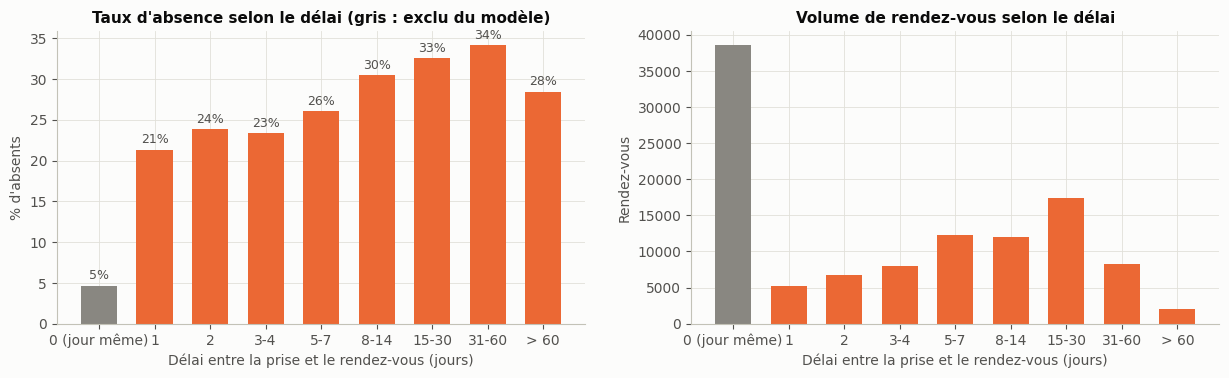

In [5]:
bornes_delai = [-1, 0, 1, 2, 4, 7, 14, 30, 60, 200]
noms_delai = ['0 (jour même)', '1', '2', '3-4', '5-7', '8-14', '15-30', '31-60', '> 60']
tranche = pd.cut(delai_brut, bornes_delai, labels=noms_delai)
par_delai = absent_brut[delai_brut >= 0].groupby(tranche[delai_brut >= 0], observed=True).agg(['mean', 'size'])

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
couleurs = [MUTED] + [C_ABS] * (len(par_delai) - 1)
axes[0].bar(par_delai.index.astype(str), 100 * par_delai['mean'], color=couleurs, width=0.65)
for i, v in enumerate(par_delai['mean']):
    axes[0].text(i, 100 * v + 0.8, f'{v:.0%}', ha='center', color=INK2, fontsize=9)
axes[0].set(xlabel='Délai entre la prise et le rendez-vous (jours)', ylabel="% d'absents",
            title="Taux d'absence selon le délai (gris : exclu du modèle)")
axes[1].bar(par_delai.index.astype(str), par_delai['size'], color=couleurs, width=0.65)
axes[1].set(xlabel='Délai entre la prise et le rendez-vous (jours)', ylabel='Rendez-vous', title='Volume de rendez-vous selon le délai')
savefig(fig, '01_population_delai')
plt.show()

**Interprétation.**
* **35 % des rendez-vous sont pris le jour même**, et seuls 4,6 % d'entre eux sont manqués : le patient est souvent déjà au centre ou décide de venir dans l'heure. Pour les rendez-vous pris au moins la veille, le taux d'absence est de **28,5 %**, soit six fois plus.
* Le taux d'absence augmente avec le délai : **21 %** à 1 jour, **30 à 34 %** au-delà d'une semaine. Il redescend légèrement au-delà de 60 jours (28 %), sur un petit effectif.
* Cinq rendez-vous sont datés *avant* leur prise de rendez-vous : ce sont des erreurs de saisie, supprimées en section 4.

➡️ **Choix de la population.** On modélise uniquement les rendez-vous pris au moins la veille. C'est la seule population pour laquelle un rappel à J−1 est possible. Inclure les rendez-vous du jour même ferait monter l'AUC artificiellement, car le modèle apprendrait simplement que « pris le jour même = présent ». Ce gain apparent est chiffré en section 14 (S6). Ces rendez-vous restent utilisés pour calculer l'historique de présence des patients.

## 3. Audit des variables et des fuites de données

Une **fuite de données** (*data leakage*) se produit quand un prédicteur contient une information indisponible au moment de la prédiction. Le modèle paraît alors excellent mais ne sert à rien en pratique. Chaque colonne est classée selon **le moment où elle devient connue** par rapport à T0 (la veille du rendez-vous).

In [6]:
dictionnaire = pd.DataFrame([
    ('PatientId', 'Identifiant du patient', 'Connu', "Non prédicteur ; sert à reconstruire l'historique et à grouper la validation croisée"),
    ('AppointmentID', 'Identifiant du rendez-vous', 'Connu', 'Non prédicteur : numéro séquentiel, quasi identique à la date de prise (corrélation 0,998)'),
    ('Gender, Age', 'Sexe et âge du patient', 'Connu à T0', 'Conservées'),
    ('Scholarship', 'Bénéficiaire de la Bolsa Família (aide sociale brésilienne)', 'Connu à T0', 'Conservée : indicateur de précarité'),
    ('Hipertension, Diabetes, Alcoholism, Handcap', 'Conditions de santé déclarées', 'Connu à T0', 'Conservées (handicap ramené à oui / non)'),
    ('ScheduledDay', 'Date et heure de la prise de rendez-vous', 'Connu à T0', 'Transformée : délai, heure de prise'),
    ('AppointmentDay', 'Date du rendez-vous (sans heure)', 'Connu à T0', 'Transformée : jour de la semaine, historique'),
    ('Neighbourhood', 'Quartier (constant pour chaque patient)', 'Connu à T0', 'Exclue du modèle principal : propre à Vitória, non transposable au Bénin (testée en S4)'),
    ('SMS_received', 'Au moins un SMS de rappel envoyé', 'Décidé avant le rendez-vous', "Exclue : c'est l'action que le score doit piloter, et elle est confondue avec le délai (section 6.5, testée en S3)"),
    ('No-show', 'Absence au rendez-vous', 'Après le rendez-vous', 'Cible'),
    ("Taux d'absence « du patient »", 'Calculé sur tous ses rendez-vous', 'Inclut le rendez-vous à prédire et les suivants', 'Interdit : fuite directe (démontrée en S1) ; remplacé par un historique strictement antérieur'),
], columns=['Variable(s)', 'Signification', 'Disponibilité', 'Décision'])
dictionnaire

,Variable(s),Signification,Disponibilité,Décision
0,PatientId,Identifiant du patient,Connu,Non prédicteur ; sert à reconstruire l'histori...
1,AppointmentID,Identifiant du rendez-vous,Connu,"Non prédicteur : numéro séquentiel, quasi iden..."
2,"Gender, Age",Sexe et âge du patient,Connu à T0,Conservées
3,Scholarship,Bénéficiaire de la Bolsa Família (aide sociale...,Connu à T0,Conservée : indicateur de précarité
4,"Hipertension, Diabetes, Alcoholism, Handcap",Conditions de santé déclarées,Connu à T0,Conservées (handicap ramené à oui / non)
5,ScheduledDay,Date et heure de la prise de rendez-vous,Connu à T0,"Transformée : délai, heure de prise"
6,AppointmentDay,Date du rendez-vous (sans heure),Connu à T0,"Transformée : jour de la semaine, historique"
7,Neighbourhood,Quartier (constant pour chaque patient),Connu à T0,"Exclue du modèle principal : propre à Vitória,..."
8,SMS_received,Au moins un SMS de rappel envoyé,Décidé avant le rendez-vous,Exclue : c'est l'action que le score doit pilo...
9,No-show,Absence au rendez-vous,Après le rendez-vous,Cible


In [7]:
# Rendez-vous multiples d'un même patient le même jour : leurs issues sont-elles liées ?
multi = raw.assign(jour=rdv_brut, absent=absent_brut).groupby(['PatientId', 'jour'])['absent'].agg(['size', 'mean'])
multi = multi[multi['size'] > 1]
print(f"{len(multi)} couples patient-jour ont plusieurs rendez-vous ({int(multi['size'].sum())} rendez-vous).")
print(f"Issue identique pour tous les rendez-vous du jour : {((multi['mean'] == 0) | (multi['mean'] == 1)).mean():.1%} des cas.")
print(f"Patients distincts : {raw['PatientId'].nunique()} ; patients ayant au moins 2 rendez-vous : "
      f"{(raw['PatientId'].value_counts() > 1).sum()}")

7481 couples patient-jour ont plusieurs rendez-vous (16200 rendez-vous).
Issue identique pour tous les rendez-vous du jour : 82.1% des cas.
Patients distincts : 62299 ; patients ayant au moins 2 rendez-vous : 24379


**Interprétation.**
* **Deux variables sont écartées du modèle principal pour des raisons de conception, pas de performance** :
  * Le **SMS de rappel** est l'action que VIHEPAT veut piloter avec le score. L'utiliser comme prédicteur serait circulaire : on ne peut pas décider d'envoyer un SMS à partir d'un score qui suppose déjà de savoir si le SMS sera envoyé. En outre, il n'est envoyé que pour les rendez-vous lointains (section 6.5).
  * Le **quartier** désigne 81 quartiers de Vitória : ces modalités n'ont aucun équivalent au Bénin.
* **Le piège le plus répandu sur ce jeu** consiste à calculer le « taux d'absence du patient » sur l'ensemble de ses rendez-vous, y compris celui que l'on cherche à prédire et les suivants. On reconstruit à la place un historique **strictement antérieur** au jour du rendez-vous (section 5).
* **82 % des patients ayant plusieurs rendez-vous le même jour** ont la même issue pour tous ces rendez-vous, et 24 379 patients ont au moins 2 rendez-vous. Les observations ne sont donc **pas indépendantes**. Le découpage, la validation croisée et les intervalles de confiance doivent garder ensemble les rendez-vous d'un même patient (section 7).

## 4. Qualité des données et nettoyage

### 4.1 Vue d'ensemble

In [8]:
apercu = pd.DataFrame({'type': raw.dtypes.astype(str), 'n manquants': raw.isna().sum(),
                       'valeurs distinctes': raw.nunique(), 'exemple': raw.iloc[0]})
display(apercu)
raw.describe().T

,type,n manquants,valeurs distinctes,exemple
PatientId,float64,0,62299,"29,872,499,824,296.000"
AppointmentID,int64,0,110527,5642903
Gender,object,0,2,F
ScheduledDay,object,0,103549,2016-04-29T18:38:08Z
AppointmentDay,object,0,27,2016-04-29T00:00:00Z
Age,int64,0,104,62
Neighbourhood,object,0,81,JARDIM DA PENHA
Scholarship,int64,0,2,0
Hipertension,int64,0,2,1
Diabetes,int64,0,2,0


,count,mean,std,min,25%,50%,75%,max
PatientId,"110,527.000","147,496,265,710,394.062","256,094,920,291,738.875","39,217.844","4,172,614,444,192.000","31,731,838,713,978.000","94,391,720,898,175.000","999,981,631,772,427.000"
AppointmentID,"110,527.000","5,675,305.123","71,295.752","5,030,230.000","5,640,285.500","5,680,573.000","5,725,523.500","5,790,484.000"
Age,"110,527.000",37.089,23.110,-1.000,18.000,37.000,55.000,115.000
Scholarship,"110,527.000",0.098,0.298,0.000,0.000,0.000,0.000,1.000
Hipertension,"110,527.000",0.197,0.398,0.000,0.000,0.000,0.000,1.000
Diabetes,"110,527.000",0.072,0.258,0.000,0.000,0.000,0.000,1.000
Alcoholism,"110,527.000",0.030,0.172,0.000,0.000,0.000,0.000,1.000
Handcap,"110,527.000",0.022,0.162,0.000,0.000,0.000,0.000,4.000
SMS_received,"110,527.000",0.321,0.467,0.000,0.000,0.000,1.000,1.000


### 4.2 Valeurs manquantes et doublons
Aucune valeur n'est manquante au sens strict. Pour les doublons, on cherche des rendez-vous identiques sur toutes les colonnes sauf l'identifiant du rendez-vous et l'issue : ce sont des rendez-vous **pris lors de la même session** (même patient, même seconde de prise, même jour).

In [9]:
print(f'Valeurs manquantes : {int(raw.isna().sum().sum())}')
print(f"Identifiants de rendez-vous uniques : {raw['AppointmentID'].is_unique}")
cles = [c for c in raw.columns if c not in ('AppointmentID', 'No-show')]
copies = raw[raw.duplicated(subset=cles, keep=False)]
groupes_copies = copies.groupby(cles)['No-show'].nunique()
print(f"{raw.duplicated(subset=cles).sum()} rendez-vous sont des copies d'un autre (hors identifiant et issue) : "
      f"{len(copies)} lignes en {len(groupes_copies)} groupes.")
print(f"Même issue dans tout le groupe : {(groupes_copies == 1).mean():.1%} des groupes.")

Valeurs manquantes : 0
Identifiants de rendez-vous uniques : True


632 rendez-vous sont des copies d'un autre (hors identifiant et issue) : 1227 lignes en 595 groupes.
Même issue dans tout le groupe : 97.6% des groupes.


### 4.3 Anomalies et incohérences

In [10]:
AGE_MAX = 105
anomalies = pd.DataFrame([
    ('Âge négatif', int((raw['Age'] < 0).sum()), 'Erreur de saisie', 'Supprimée'),
    (f'Âge supérieur à {AGE_MAX} ans', int((raw['Age'] > AGE_MAX).sum()),
     f"Valeur {sorted(raw.loc[raw['Age'] > AGE_MAX, 'Age'].unique())} pour {raw.loc[raw['Age'] > AGE_MAX, 'PatientId'].nunique()} patients : invraisemblable", 'Supprimées'),
    ('Âge = 0', int((raw['Age'] == 0).sum()), "Nourrissons de moins d'un an : plausible", 'Conservées'),
    ('Rendez-vous antérieur à sa prise', int((delai_brut < 0).sum()), 'Dates incohérentes', 'Supprimées'),
    ('Handicap codé de 2 à 4', int((raw['Handcap'] > 1).sum()), "Nombre de handicaps, et non booléen comme l'indique la documentation", 'Ramené à oui / non'),
    ('Alcoolisme déclaré avant 12 ans', int(((raw['Alcoholism'] == 1) & (raw['Age'] < 12)).sum()), "Suspect (alcoolisme d'un parent ?)", 'Conservées (effectif négligeable)'),
    ('Identifiant patient non entier', int((raw['PatientId'] % 1 != 0).sum()), 'Défaut de formatage', 'Converti en texte, conservé'),
    ('Rendez-vous un samedi', int((rdv_brut.dt.dayofweek == 5).sum()), 'Activité exceptionnelle (une seule date)', 'Conservés'),
], columns=['Anomalie', 'Lignes', 'Diagnostic', 'Décision'])
display(anomalies)
for c in ['Gender', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show']:
    print(f'{c:13s}', raw[c].value_counts().to_dict())

,Anomalie,Lignes,Diagnostic,Décision
0,Âge négatif,1,Erreur de saisie,Supprimée
1,Âge supérieur à 105 ans,5,Valeur [np.int64(115)] pour 2 patients : invra...,Supprimées
2,Âge = 0,3539,Nourrissons de moins d'un an : plausible,Conservées
3,Rendez-vous antérieur à sa prise,5,Dates incohérentes,Supprimées
4,Handicap codé de 2 à 4,199,"Nombre de handicaps, et non booléen comme l'in...",Ramené à oui / non
5,Alcoolisme déclaré avant 12 ans,6,Suspect (alcoolisme d'un parent ?),Conservées (effectif négligeable)
6,Identifiant patient non entier,5,Défaut de formatage,"Converti en texte, conservé"
7,Rendez-vous un samedi,39,Activité exceptionnelle (une seule date),Conservés


Gender        {'F': 71840, 'M': 38687}
Scholarship   {0: 99666, 1: 10861}
Hipertension  {0: 88726, 1: 21801}
Diabetes      {0: 102584, 1: 7943}
Alcoholism    {0: 107167, 1: 3360}
Handcap       {0: 108286, 1: 2042, 2: 183, 3: 13, 4: 3}
SMS_received  {0: 75045, 1: 35482}
No-show       {'No': 88208, 'Yes': 22319}


### 4.4 Nettoyage
Le nettoyage est **déterministe** : il ne dépend d'aucune statistique apprise. Il peut donc être appliqué avant le découpage sans risque de fuite. Il convertit les types, recode la cible, renomme les colonnes en français et supprime les lignes impossibles.

In [11]:
RENOMMAGE = {'AppointmentID': 'id_rdv', 'Gender': 'sexe', 'Age': 'age', 'Neighbourhood': 'quartier',
             'Scholarship': 'bolsa_familia', 'Hipertension': 'hypertension', 'Diabetes': 'diabete',
             'Alcoholism': 'alcoolisme', 'Handcap': 'nb_handicaps', 'SMS_received': 'sms_recu'}


def nettoyer(d):
    d = d.rename(columns=RENOMMAGE).copy()
    d['id_patient'] = d['PatientId'].map(lambda v: f'{v:.0f}' if float(v).is_integer() else repr(v))
    d['date_prise'] = pd.to_datetime(d['ScheduledDay']).dt.tz_localize(None)
    d['date_rdv'] = pd.to_datetime(d['AppointmentDay']).dt.tz_localize(None)
    d['delai_jours'] = (d['date_rdv'] - d['date_prise'].dt.normalize()).dt.days
    d['absent'] = (d['No-show'] == 'Yes').astype(int)
    valide = (d['delai_jours'] >= 0) & d['age'].between(0, AGE_MAX)
    d = d.loc[valide].drop(columns=['PatientId', 'ScheduledDay', 'AppointmentDay', 'No-show'])
    return d.sort_values(['date_rdv', 'date_prise', 'id_rdv']).reset_index(drop=True)


propre = nettoyer(raw)
print(f'{len(raw)} → {len(propre)} rendez-vous ({len(raw) - len(propre)} lignes impossibles supprimées)')

110527 → 110516 rendez-vous (11 lignes impossibles supprimées)


## 5. Création de variables

Chaque variable est connue à T0 (la veille du rendez-vous) et justifiée par le domaine :

| Variable | Construction | Justification |
|---|---|---|
| `delai_jours` | Jours entre la prise et le rendez-vous | Facteur le plus constant dans la littérature (Dantas *et al.*, 2018) : plus le rendez-vous est lointain, plus il est oublié ou supplanté par un empêchement |
| `heure_prise` | Heure de la prise de rendez-vous | Distingue une prise au guichet, en journée, d'une prise plus tardive |
| `jour_semaine` | Jour du rendez-vous | Contraintes de travail et de transport variables selon le jour |
| `handicap` | Au moins un handicap déclaré | Le nombre de handicaps (2 à 4) concerne trop peu de patients pour être exploité seul |
| `nb_rdv_anterieurs` | Rendez-vous du patient aux **dates strictement antérieures** | Mesure l'engagement dans le parcours de soins |
| `nb_absences_anterieures` | Absences à ces rendez-vous | L'historique d'absence est le 2ᵉ facteur le plus cité dans la littérature |
| `taux_absence_anterieur` | (absences + 0,23) / (rendez-vous + 1) | Taux **lissé** vers 23 %, le taux moyen de la littérature : un patient avec 1 absence sur 1 rendez-vous n'est pas « absent à 100 % » |
| `premier_rdv` | Aucun rendez-vous antérieur observé | Distingue « pas d'historique » de « historique sans absence » |
| `nb_rdv_jour` | Rendez-vous du patient le même jour, programmés au plus tard la veille | Plusieurs consultations le même jour : déplacement plus « rentable », mais journée plus lourde |

**Point crucial contre la fuite :** l'historique ne compte que les rendez-vous dont la date est **strictement antérieure** au jour du rendez-vous à prédire. Il inclut les rendez-vous pris le jour même : ils sont exclus de la population à prédire, mais ils informent sur l'assiduité du patient.

In [12]:
TAUX_A_PRIORI = 0.23    # taux moyen d'absence rapporté par la revue de Dantas et al. (2018), et non estimé sur nos données
JOURS = {0: 'lundi', 1: 'mardi', 2: 'mercredi', 3: 'jeudi', 4: 'vendredi', 5: 'samedi', 6: 'dimanche'}


def creer_variables(d):
    """Variables connues la veille du rendez-vous. `d` doit contenir TOUS les rendez-vous connus des patients."""
    d = d.copy()
    d['heure_prise'] = d['date_prise'].dt.hour + d['date_prise'].dt.minute / 60
    d['jour_semaine'] = d['date_rdv'].dt.dayofweek.map(JOURS)
    d['handicap'] = (d['nb_handicaps'] > 0).astype(int)
    # Historique : agrégation par patient et par jour, puis cumul des jours STRICTEMENT antérieurs
    jours = d.groupby(['id_patient', 'date_rdv'])['absent'].agg(n='size', absences='sum').reset_index()
    cumul = jours.groupby('id_patient')[['n', 'absences']].cumsum()
    jours['nb_rdv_anterieurs'] = cumul['n'] - jours['n']
    jours['nb_absences_anterieures'] = cumul['absences'] - jours['absences']
    d = d.merge(jours[['id_patient', 'date_rdv', 'nb_rdv_anterieurs', 'nb_absences_anterieures']],
                on=['id_patient', 'date_rdv'], how='left')
    d['premier_rdv'] = (d['nb_rdv_anterieurs'] == 0).astype(int)
    d['taux_absence_anterieur'] = (d['nb_absences_anterieures'] + TAUX_A_PRIORI) / (d['nb_rdv_anterieurs'] + 1)
    d['programme_veille'] = (d['delai_jours'] >= 1).astype(int)
    d['nb_rdv_jour'] = d.groupby(['id_patient', 'date_rdv'])['programme_veille'].transform('sum')
    d['meme_jour'] = (d['delai_jours'] == 0).astype(int)
    # Variable INTERDITE, construite uniquement pour démontrer la fuite (section 14, S1)
    d['FUITE_taux_absence_global'] = d.groupby('id_patient')['absent'].transform('mean')
    return d


df = creer_variables(propre)
df_model = df[df['delai_jours'] >= 1].reset_index(drop=True)        # population : rendez-vous pris au moins la veille

VARS_SPLINE = ['age', 'delai_jours']
VARS_COMPTE = ['nb_rdv_anterieurs', 'nb_absences_anterieures', 'nb_rdv_jour']
VARS_NUM = ['heure_prise', 'taux_absence_anterieur']
VARS_BIN = ['bolsa_familia', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'premier_rdv']
VARS_CAT = ['sexe', 'jour_semaine']
FEATURES = VARS_SPLINE + VARS_COMPTE + VARS_NUM + VARS_BIN + VARS_CAT

VARIABLES = {   # libellé et unité, pour les figures et la carte affichée dans VIHEPAT
    'age': ('Âge', 'ans'), 'delai_jours': ('Délai de prise de rendez-vous', 'jours'),
    'heure_prise': ('Heure de prise du rendez-vous', 'h'), 'nb_rdv_anterieurs': ('Rendez-vous antérieurs', ''),
    'nb_absences_anterieures': ('Absences antérieures', ''), 'taux_absence_anterieur': ("Taux d'absence antérieur (lissé)", ''),
    'nb_rdv_jour': ('Rendez-vous du patient ce jour-là', ''), 'bolsa_familia': ('Bénéficiaire Bolsa Família', ''),
    'hypertension': ('Hypertension', ''), 'diabete': ('Diabète', ''), 'alcoolisme': ('Alcoolisme', ''),
    'handicap': ('Handicap', ''), 'premier_rdv': ('Premier rendez-vous observé', ''), 'sexe': ('Sexe', ''),
    'jour_semaine': ('Jour du rendez-vous', ''), 'sms_recu': ('SMS de rappel reçu', ''), 'quartier': ('Quartier', ''),
    'meme_jour': ('Rendez-vous pris le jour même', ''), 'FUITE_taux_absence_global': ("FUITE : taux d'absence global", '')}
TRAD = {'F': 'femme', 'M': 'homme'}

print(f'Tous les rendez-vous valides (servent à l\'historique) : {len(df)}')
print(f'Population modélisée (pris au moins la veille) : {len(df_model)} rendez-vous, '
      f"{df_model['id_patient'].nunique()} patients, {df_model['absent'].mean():.1%} d'absents")
df_model[['id_patient', 'date_prise', 'date_rdv', 'absent'] + FEATURES].head()

Tous les rendez-vous valides (servent à l'historique) : 110516
Population modélisée (pris au moins la veille) : 71955 rendez-vous, 45838 patients, 28.5% d'absents


,id_patient,date_prise,date_rdv,absent,age,delai_jours,nb_rdv_anterieurs,nb_absences_anterieures,nb_rdv_jour,heure_prise,taux_absence_anterieur,bolsa_familia,hypertension,diabete,alcoolisme,handicap,premier_rdv,sexe,jour_semaine
0,1423328986773,2016-01-05 11:53:44,2016-04-29,0,84,115,0,0,1,11.883,0.230,0,1,1,0,1,1,M,vendredi
1,4616857575498,2016-01-05 15:02:46,2016-04-29,0,83,115,0,0,1,15.033,0.230,0,1,0,0,0,1,F,vendredi
2,55589627937198,2016-01-11 08:52:35,2016-04-29,0,74,109,0,0,1,8.867,0.230,0,0,0,0,0,1,F,vendredi
3,91896944762663,2016-01-11 09:08:10,2016-04-29,0,70,109,0,0,1,9.133,0.230,0,1,1,0,0,1,F,vendredi
4,1534481873995,2016-01-11 09:09:10,2016-04-29,0,87,109,0,0,1,9.150,0.230,0,0,0,0,0,1,F,vendredi


In [13]:
# Contrôle de l'absence de fuite sur un patient suivi plusieurs fois
exemple = df.loc[df['id_patient'] == df_model['id_patient'].value_counts().index[0],
                 ['date_rdv', 'delai_jours', 'absent', 'nb_rdv_anterieurs', 'nb_absences_anterieures', 'taux_absence_anterieur']]
print("Patient le plus suivi : l'historique d'un jour n'utilise que les issues des jours précédents")
exemple.head(12)

Patient le plus suivi : l'historique d'un jour n'utilise que les issues des jours précédents

,date_rdv,delai_jours,absent,nb_rdv_anterieurs,nb_absences_anterieures,taux_absence_anterieur
904,2016-04-29,17,0,0,0,0.230
4952,2016-05-02,6,1,1,0,0.115
9138,2016-05-03,7,0,2,1,0.410
9760,2016-05-03,4,0,2,1,0.410
13202,2016-05-04,8,0,4,1,0.246
17345,2016-05-05,9,0,5,1,0.205
18300,2016-05-05,2,0,5,1,0.205
21427,2016-05-06,10,1,7,1,0.154
25835,2016-05-09,7,0,8,2,0.248
27315,2016-05-09,0,0,8,2,0.248


**Interprétation.**
* Le contrôle sur le patient le plus suivi le confirme : le 3 mai, son historique compte 2 rendez-vous antérieurs (29 avril et 2 mai) et 1 absence (2 mai). Les deux rendez-vous du 3 mai partagent ce même historique : aucun des deux ne « voit » l'issue de l'autre.
* Le taux lissé évite les valeurs extrêmes : avec 1 absence sur 1 rendez-vous, il vaut (1 + 0,23) / 2 = 62 % et non 100 %.
* **58,6 % des rendez-vous modélisés n'ont aucun historique observé.** Ce n'est pas un vrai premier rendez-vous : le jeu ne couvre que 6 semaines, donc l'historique antérieur au 29 avril est invisible. C'est une limite majeure du jeu, qui sous-estime la valeur de l'historique (section 15).

## 6. Analyse exploratoire (EDA)
Sauf mention contraire, l'analyse porte sur la **population modélisée** (rendez-vous pris au moins la veille).

### 6.1 Déséquilibre des classes

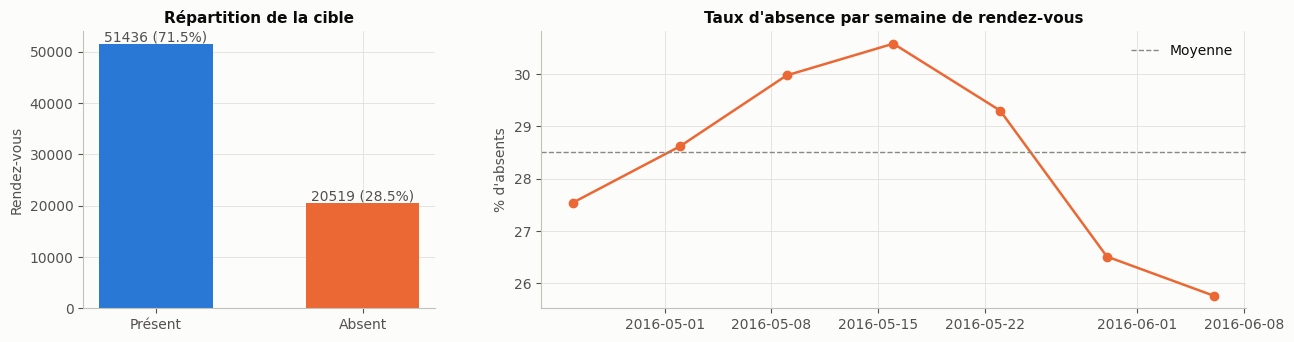

Ratio présents / absents : 2.51


In [14]:
compte = df_model['absent'].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={'width_ratios': [1, 2]})
axes[0].bar([CLASSES[i] for i in compte.index], compte.values, color=[C_PRES, C_ABS], width=0.55)
for i, v in enumerate(compte.values):
    axes[0].text(i, v + 600, f'{v} ({v / compte.sum():.1%})', ha='center', color=INK2)
axes[0].set(ylabel='Rendez-vous', title='Répartition de la cible')
semaine = df_model.groupby(df_model['date_rdv'].dt.to_period('W').dt.start_time)['absent'].agg(['mean', 'size'])
axes[1].plot(semaine.index, 100 * semaine['mean'], 'o-', color=C_ABS)
axes[1].axhline(100 * df_model['absent'].mean(), color=MUTED, ls='--', lw=1, label='Moyenne')
axes[1].set(ylabel="% d'absents", title="Taux d'absence par semaine de rendez-vous")
axes[1].legend()
savefig(fig, '02_desequilibre')
plt.show()
print(f"Ratio présents / absents : {compte[0] / compte[1]:.2f}")

**Interprétation.** Le déséquilibre est **modéré** : 28,5 % d'absents, soit 2,5 présents pour 1 absent. Trois conséquences :
* aucun rééquilibrage artificiel n'est nécessaire, et il fausserait les probabilités affichées ;
* l'**accuracy est trompeuse** : prédire « présent » pour tout le monde donne déjà 71,5 % de bonnes réponses ;
* le plancher de la PR-AUC est la prévalence (≈ 0,27 à 0,29), et non 0,5. Toute performance doit être lue par rapport à ce plancher.

Le taux d'absence **diminue au fil des semaines** (de près de 30 % en mai à 26 % début juin). Cette dérive explique en partie la légère surestimation des risques sur le jeu de test (section 10).

### 6.2 Distributions : histogrammes

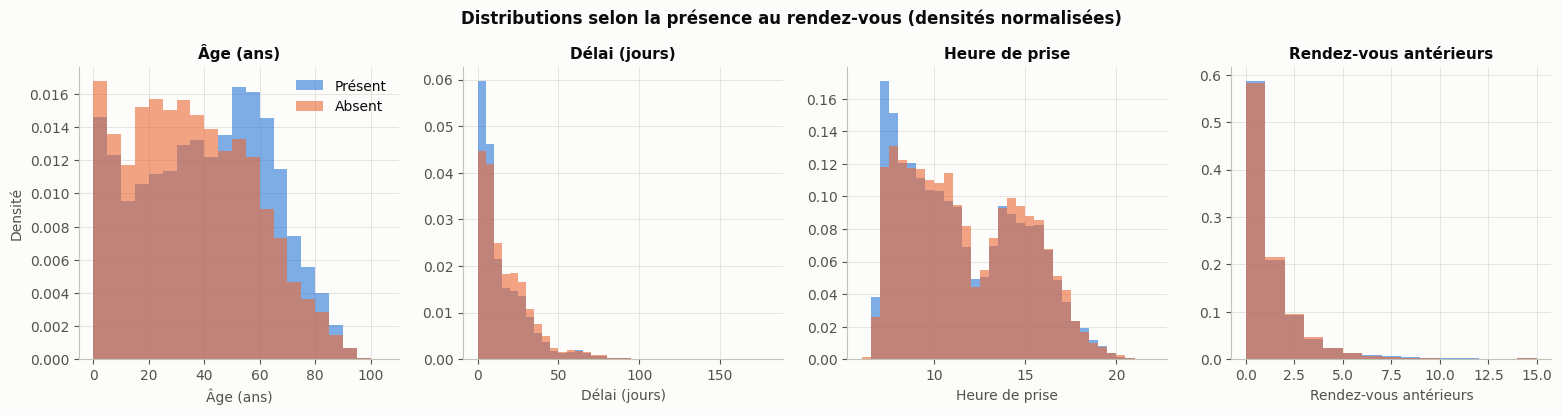

,count,mean,std,min,25%,50%,75%,max
age,"71,955.000",38.498,22.919,0.000,19.000,39.000,57.000,102.000
delai_jours,"71,955.000",15.642,16.494,1.000,4.000,9.000,22.000,179.000
heure_prise,"71,955.000",11.565,3.273,6.400,8.667,10.983,14.350,21.450
nb_rdv_anterieurs,"71,955.000",0.961,2.145,0.000,0.000,0.000,1.000,76.000
nb_absences_anterieures,"71,955.000",0.184,0.552,0.000,0.000,0.000,0.000,10.000


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
specs = [('age', np.arange(0, 106, 5), 'Âge (ans)'), ('delai_jours', np.arange(0, 181, 5), 'Délai (jours)'),
         ('heure_prise', np.arange(6, 22.5, 0.5), 'Heure de prise'), ('nb_rdv_anterieurs', np.arange(0, 16), 'Rendez-vous antérieurs')]
for ax, (var, bins, lab) in zip(axes, specs):
    for k, couleur in [(0, C_PRES), (1, C_ABS)]:
        ax.hist(df_model.loc[df_model['absent'] == k, var].clip(upper=bins[-1]), bins=bins, color=couleur,
                alpha=0.6, density=True, label=CLASSES[k])
    ax.set(xlabel=lab, title=lab)
axes[0].set_ylabel('Densité')
axes[0].legend()
fig.suptitle('Distributions selon la présence au rendez-vous (densités normalisées)', y=1.03, fontweight='bold')
savefig(fig, '03_histogrammes')
plt.show()
df_model[['age', 'delai_jours', 'heure_prise', 'nb_rdv_anterieurs', 'nb_absences_anterieures']].describe().T

### 6.3 Box plots et tests de comparaison
Le test de Mann-Whitney compare les distributions des présents et des absents sans supposer de loi normale.

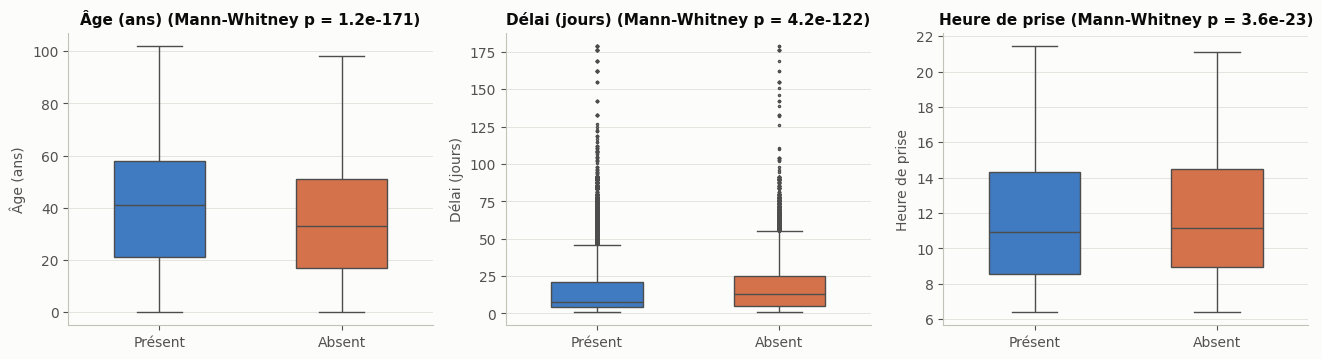

,age,delai_jours,heure_prise
absent,,,
Absent,33.000,13.000,11.167
Présent,41.000,8.000,10.900


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (var, lab) in zip(axes, [('age', 'Âge (ans)'), ('delai_jours', 'Délai (jours)'), ('heure_prise', 'Heure de prise')]):
    sns.boxplot(data=df_model, x=df_model['absent'].map(CLASSES), y=var, order=['Présent', 'Absent'], hue=df_model['absent'].map(CLASSES),
                palette={'Présent': C_PRES, 'Absent': C_ABS}, ax=ax, width=0.5, fliersize=1.5, legend=False)
    p = stats.mannwhitneyu(df_model.loc[df_model.absent == 0, var], df_model.loc[df_model.absent == 1, var])[1]
    ax.set(xlabel='', ylabel=lab, title=f'{lab} (Mann-Whitney p = {p:.1e})')
savefig(fig, '04_boxplots')
plt.show()
df_model.groupby(df_model['absent'].map(CLASSES))[['age', 'delai_jours', 'heure_prise']].median()

### 6.4 Taux d'absence selon chaque facteur
Les barres d'erreur sont des intervalles de confiance de Wilson à 95 %. La ligne pointillée indique le taux moyen.

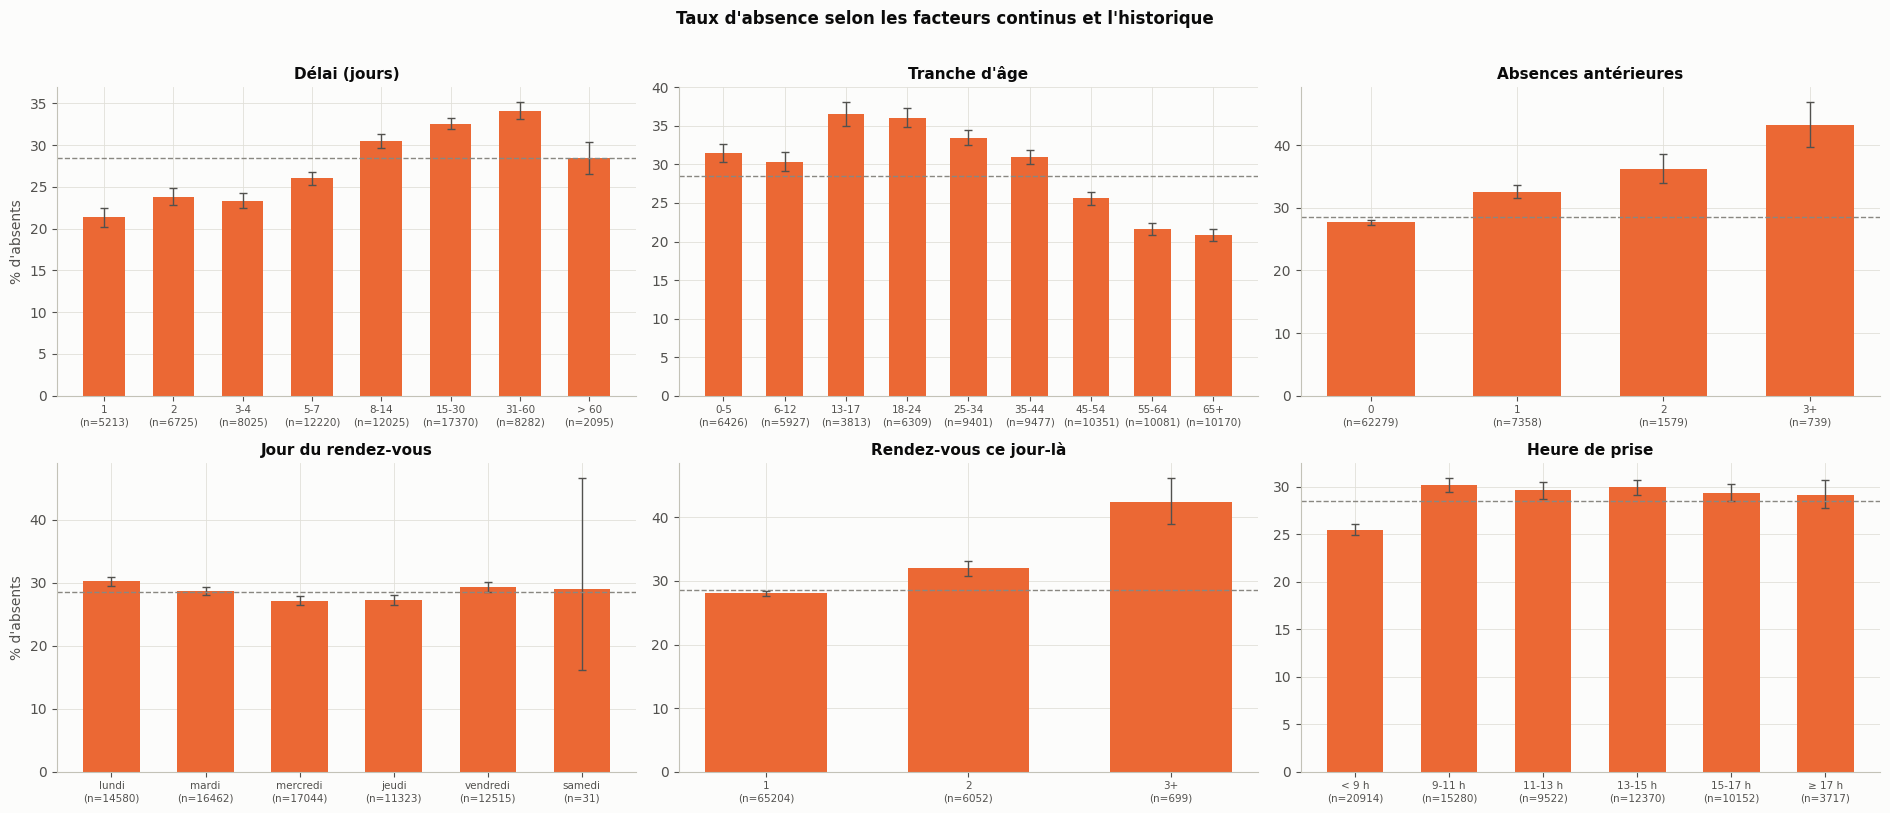

In [17]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - demi, centre + demi


def taux_par(groupe, cible=None):
    cible = df_model['absent'] if cible is None else cible
    t = cible.groupby(groupe, observed=True).agg(['sum', 'size'])
    t['taux'] = t['sum'] / t['size']
    t['bas'], t['haut'] = wilson(t['sum'], t['size'])
    return t


def barres(ax, t, titre, couleur=C_ABS):
    x = np.arange(len(t))
    ax.bar(x, 100 * t['taux'], color=couleur, width=0.6)
    ax.errorbar(x, 100 * t['taux'], yerr=[100 * (t['taux'] - t['bas']), 100 * (t['haut'] - t['taux'])],
                fmt='none', ecolor=INK2, capsize=3, lw=1)
    ax.axhline(100 * df_model['absent'].mean(), color=MUTED, ls='--', lw=1)
    ax.set_xticks(x, [f'{i}\n(n={n})' for i, n in zip(t.index.astype(str), t['size'])], fontsize=7.5)
    ax.set_title(titre)


PREV = df_model['absent'].mean()
facteurs = {
    'Délai (jours)': pd.cut(df_model['delai_jours'], [0, 1, 2, 4, 7, 14, 30, 60, 200], labels=['1', '2', '3-4', '5-7', '8-14', '15-30', '31-60', '> 60']),
    "Tranche d'âge": pd.cut(df_model['age'], [-1, 5, 12, 17, 24, 34, 44, 54, 64, 120], labels=['0-5', '6-12', '13-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']),
    'Absences antérieures': df_model['nb_absences_anterieures'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'}),
    'Jour du rendez-vous': pd.Categorical(df_model['jour_semaine'], categories=[j for j in JOURS.values() if j in set(df_model['jour_semaine'])]),
    'Rendez-vous ce jour-là': df_model['nb_rdv_jour'].clip(upper=3).map({1: '1', 2: '2', 3: '3+'}),
    'Heure de prise': pd.cut(df_model['heure_prise'], [0, 9, 11, 13, 15, 17, 24], labels=['< 9 h', '9-11 h', '11-13 h', '13-15 h', '15-17 h', '≥ 17 h']),
}
fig, axes = plt.subplots(2, 3, figsize=(19, 8))
for ax, (titre, g) in zip(axes.ravel(), facteurs.items()):
    barres(ax, taux_par(g), titre)
for ax in axes[:, 0]:
    ax.set_ylabel("% d'absents")
fig.suptitle("Taux d'absence selon les facteurs continus et l'historique", y=1.01, fontweight='bold')
fig.tight_layout()
savefig(fig, '05a_taux_par_facteur')
plt.show()

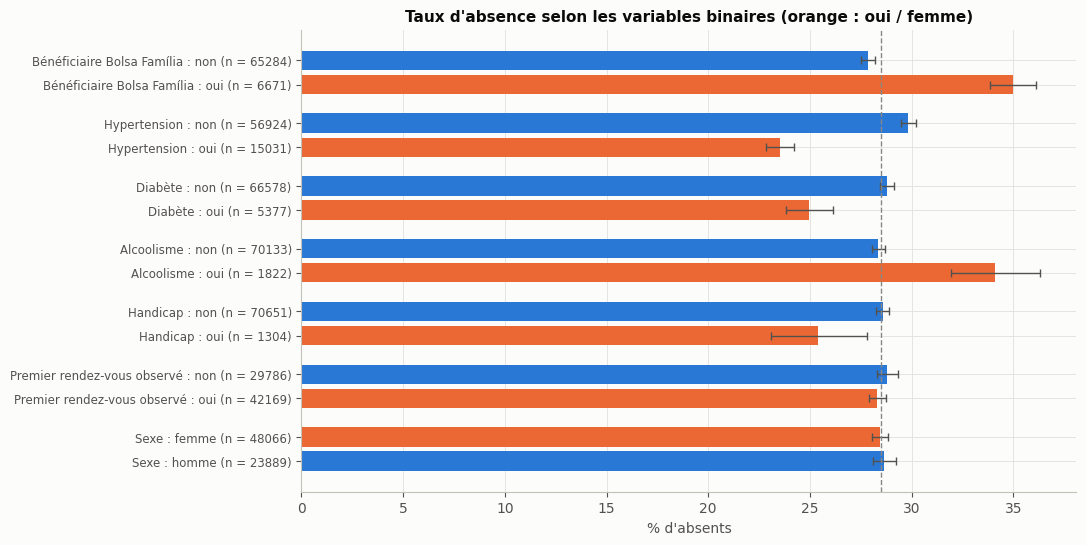

size  taux   bas  haut test du χ² (p)
Bénéficiaire Bolsa Família  non    65284 0.279 0.275 0.282        1.7e-34
                            oui     6671 0.350 0.338 0.361        1.7e-34
Hypertension                non    56924 0.298 0.295 0.302        2.3e-52
                            oui    15031 0.235 0.229 0.242        2.3e-52
Diabète                     non    66578 0.288 0.285 0.291        2.1e-09
                            oui     5377 0.250 0.238 0.261        2.1e-09
Alcoolisme                  non    70133 0.284 0.280 0.287        1.1e-07
                            oui     1822 0.341 0.319 0.363        1.1e-07
Handicap                    non    70651 0.286 0.282 0.289        1.2e-02
                            oui     1304 0.254 0.231 0.278        1.2e-02
Premier rendez-vous observé non    29786 0.288 0.283 0.293        1.5e-01
                            oui    42169 0.283 0.279 0.287        1.5e-01
Sexe                        femme  48066 0.284 0.280 0.288        5.4e-01
                            homme  23889 0.287 0.281 0.292        5.4e-01

In [18]:
binaires = pd.concat({VARIABLES[v][0]: taux_par(df_model[v].map({0: 'non', 1: 'oui'})) for v in
                      ['bolsa_familia', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'premier_rdv']}
                     | {'Sexe': taux_par(df_model['sexe'].map(TRAD))})
binaires['test du χ² (p)'] = [f"{stats.chi2_contingency(pd.crosstab(df_model[v], df_model['absent']))[1]:.1e}"
                              for v in ['bolsa_familia', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'premier_rdv', 'sexe'] for _ in range(2)]

fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(binaires))[::-1] + np.repeat(np.arange(len(binaires) // 2), 2)[::-1] * 0.6   # espace entre variables
ax.barh(ypos, 100 * binaires['taux'], color=[C_ABS if i[1] in ('oui', 'femme') else C_PRES for i in binaires.index], height=0.8)
ax.errorbar(100 * binaires['taux'], ypos, xerr=[100 * (binaires['taux'] - binaires['bas']), 100 * (binaires['haut'] - binaires['taux'])],
            fmt='none', ecolor=INK2, capsize=3, lw=1)
ax.axvline(100 * PREV, color=MUTED, ls='--', lw=1)
ax.set_yticks(ypos, [f'{v} : {m} (n = {n})' for (v, m), n in zip(binaires.index, binaires['size'])], fontsize=8.5)
ax.set(xlabel="% d'absents", title="Taux d'absence selon les variables binaires (orange : oui / femme)")
savefig(fig, '05b_taux_binaires')
plt.show()
binaires[['size', 'taux', 'bas', 'haut', 'test du χ² (p)']]

**Interprétation.**
* **Délai** : c'est le facteur le plus régulier. Le taux d'absence passe de 21 % (1 jour) à 34 % (31-60 jours), ce qui confirme la littérature (Dantas *et al.*, 2018).
* **Âge** : le risque culmine chez les **13-24 ans** (36-37 %) et décroît après 45 ans, jusqu'à 21 % chez les 65 ans et plus. Chez les enfants (0-12 ans), il est intermédiaire (30-31 %) : c'est l'assiduité des parents qui est mesurée.
* **Historique** : le taux d'absence monte de 28 % (aucune absence antérieure) à **43 % (3 absences ou plus)**. L'effet est net mais ne concerne que 13 % des rendez-vous, l'historique étant tronqué.
* **Plusieurs rendez-vous le même jour** : 42 % d'absences à partir de 3 rendez-vous. Quand le patient ne vient pas, il manque tous ses rendez-vous de la journée.
* **Précarité** : les bénéficiaires de la Bolsa Família manquent **35 %** de leurs rendez-vous, contre 28 %. L'**alcoolisme** est associé à 34 % d'absences.
* **Hypertension, diabète, handicap** : associés à *moins* d'absences (23 à 25 %). Mais ces patients sont plus âgés, et l'âge explique en grande partie cet écart (corrélation hypertension-âge de 0,50 en 6.6). Le modèle multivarié départage les deux effets (section 11).
* **Sexe** et **« premier rendez-vous observé »** : aucun effet significatif (p = 0,54 et 0,15).
* **Jour et heure** : les écarts sont faibles (27 à 30 % selon le jour). Les rendez-vous pris avant 9 h sont un peu moins manqués (25,5 %), peut-être parce qu'ils sont pris au guichet.

### 6.5 Le paradoxe du SMS (paradoxe de Simpson)
Les SMS de rappel semblent-ils efficaces ? On compare le taux d'absence avec et sans SMS, d'abord globalement (sur **tous** les rendez-vous), puis **à délai égal**.

SMS envoyés pour un délai de 0 à 2 jours : 0.0% ; à partir de 3 jours : 59.1%


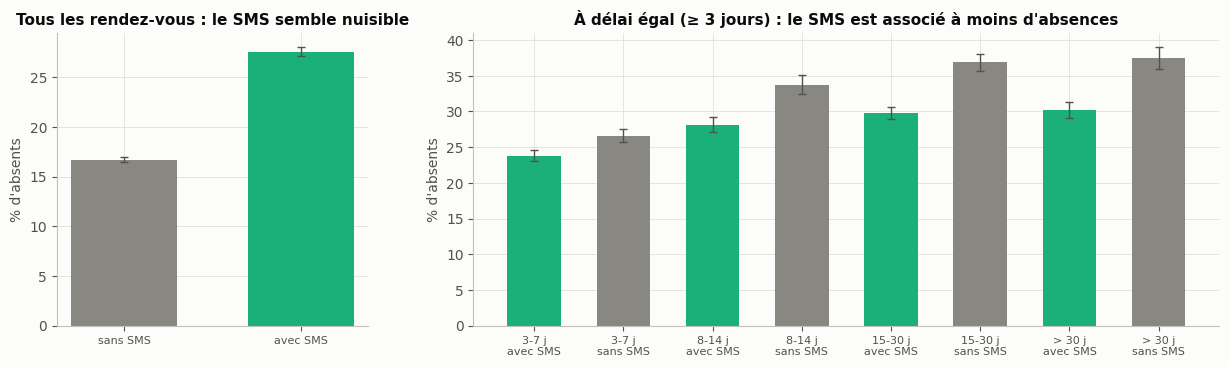

size              taux         
sms_recu avec SMS sans SMS avec SMS sans SMS
3-7 j       11548     8697    0.238    0.266
8-14 j       7004     5021    0.281    0.338
15-30 j     10519     6851    0.298    0.369
> 30 j       6410     3967    0.302    0.375

In [19]:
print(f"SMS envoyés pour un délai de 0 à 2 jours : {df.loc[df.delai_jours <= 2, 'sms_recu'].mean():.1%} ; "
      f"à partir de 3 jours : {df.loc[df.delai_jours >= 3, 'sms_recu'].mean():.1%}")
global_sms = taux_par(df['sms_recu'].map({0: 'sans SMS', 1: 'avec SMS'}), df['absent'])
strates = pd.cut(df['delai_jours'], [2, 7, 14, 30, 200], labels=['3-7 j', '8-14 j', '15-30 j', '> 30 j'])
par_strate = pd.concat({s: taux_par(df.loc[strates == s, 'sms_recu'].map({0: 'sans SMS', 1: 'avec SMS'}),
                                    df.loc[strates == s, 'absent']) for s in strates.cat.categories})

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1, 2.4]})
for ax, t, titre in [(axes[0], global_sms.reindex(['sans SMS', 'avec SMS']), 'Tous les rendez-vous : le SMS semble nuisible'),
                     (axes[1], par_strate, 'À délai égal (≥ 3 jours) : le SMS est associé à moins d\'absences')]:
    x = np.arange(len(t))
    ax.bar(x, 100 * t['taux'], color=[SERIES[2] if 'avec' in str(i) else MUTED for i in t.index], width=0.6)
    ax.errorbar(x, 100 * t['taux'], yerr=[100 * (t['taux'] - t['bas']), 100 * (t['haut'] - t['taux'])], fmt='none', ecolor=INK2, capsize=3, lw=1)
    ax.set_xticks(x, ['\n'.join(map(str, i)) if isinstance(i, tuple) else i for i in t.index], fontsize=8)
    ax.set(ylabel="% d'absents", title=titre)
savefig(fig, '06_paradoxe_sms')
plt.show()
par_strate[['size', 'taux']].unstack()

**Interprétation : un cas d'école du paradoxe de Simpson.**
* **Globalement**, les rendez-vous avec SMS sont *plus* souvent manqués (27,6 % contre 16,7 %). En conclure que le SMS est nuisible serait une erreur.
* **Explication** : aucun SMS n'est envoyé pour un délai de 0 à 2 jours, contre 59 % des rendez-vous à partir de 3 jours. Le SMS concerne donc surtout des rendez-vous lointains, qui sont les plus manqués. Le délai est un **facteur de confusion**.
* **À délai égal**, le SMS est associé à **3 à 7 points d'absence en moins** dans chaque strate (par exemple 29,8 % contre 36,9 % pour 15 à 30 jours). Cet effet est cohérent avec la revue Cochrane sur les rappels par SMS (Gurol-Urganci *et al.*, 2013), où la présence passe de 68 % à 79 %.
* **Prudence** : l'envoi n'a pas été tiré au sort, et d'autres différences entre patients peuvent subsister. Seule une évaluation contrôlée dans VIHEPAT permettra de mesurer l'effet réel des rappels.

➡️ Cette analyse justifie l'exclusion du SMS des prédicteurs (section 3). Elle montre aussi pourquoi **les associations observées ne doivent jamais être lues comme des causes**.

### 6.6 Matrice de corrélation
Corrélation de Spearman (fondée sur les rangs) : elle capte les relations monotones non linéaires et résiste aux valeurs extrêmes, comme les patients à 80 rendez-vous.

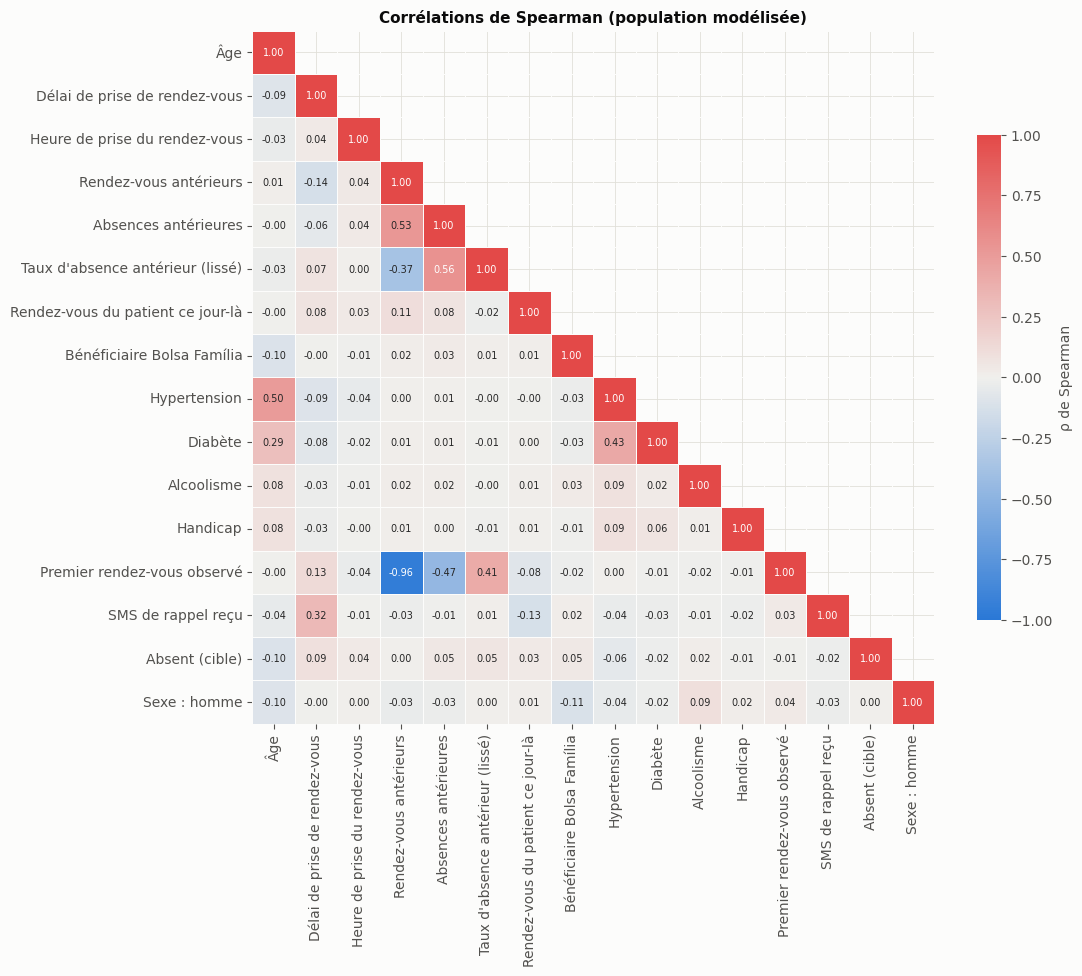

,age,delai_jours,hypertension,taux_absence_anterieur,nb_absences_anterieures,bolsa_familia,heure_prise,nb_rdv_jour,diabete,sms_recu,alcoolisme,handicap,premier_rdv,nb_rdv_anterieurs,sexe_homme
ρ avec la cible,-0.104,0.088,-0.057,0.055,0.049,0.046,0.037,0.033,-0.022,-0.021,0.020,-0.009,-0.005,0.003,0.002


In [20]:
vars_corr = ['age', 'delai_jours', 'heure_prise', 'nb_rdv_anterieurs', 'nb_absences_anterieures', 'taux_absence_anterieur',
             'nb_rdv_jour', 'bolsa_familia', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'premier_rdv', 'sms_recu', 'absent']
corr = df_model[vars_corr].assign(sexe_homme=(df_model['sexe'] == 'M').astype(int)).corr(method='spearman')
noms_corr = [VARIABLES.get(v, ('Absent (cible)' if v == 'absent' else 'Sexe : homme',))[0] for v in corr.columns]
fig, ax = plt.subplots(figsize=(11, 9))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 7},
            xticklabels=noms_corr, yticklabels=noms_corr, cbar_kws={'shrink': 0.7, 'label': 'ρ de Spearman'}, ax=ax,
            linewidths=0.5, linecolor=SURFACE)
ax.set_title('Corrélations de Spearman (population modélisée)')
savefig(fig, '07_correlations')
plt.show()
corr['absent'].drop('absent').sort_values(key=abs, ascending=False).to_frame('ρ avec la cible').T

### 6.7 Nuages de points : la dimension géographique
Chaque point est un quartier (taille proportionnelle au nombre de rendez-vous). On met en relation son taux d'absence avec deux caractéristiques de sa population : la part de bénéficiaires de la Bolsa Família (précarité) et le délai médian de prise de rendez-vous.

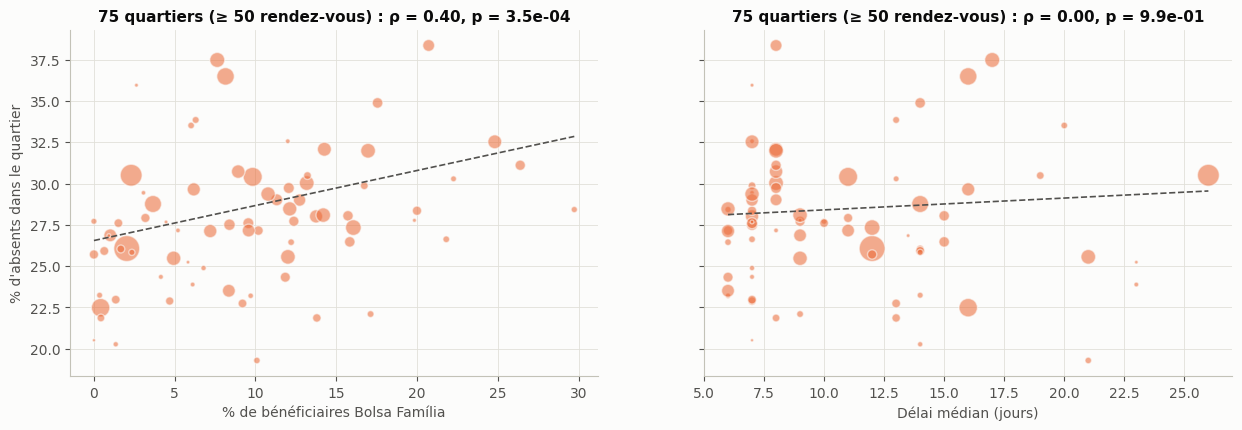

Taux d'absence par quartier : de 19.3% à 38.4%


In [21]:
quartiers = df_model.groupby('quartier').agg(rdv=('absent', 'size'), taux=('absent', 'mean'),
                                             bolsa=('bolsa_familia', 'mean'), delai=('delai_jours', 'median'))
quartiers = quartiers[quartiers['rdv'] >= 50]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (var, lab) in zip(axes, [('bolsa', '% de bénéficiaires Bolsa Família'), ('delai', 'Délai médian (jours)')]):
    xv = 100 * quartiers[var] if var == 'bolsa' else quartiers[var]
    ax.scatter(xv, 100 * quartiers['taux'], s=quartiers['rdv'] / 15, color=C_ABS, alpha=0.55, edgecolor=SURFACE)
    pente, origine = np.polyfit(xv, 100 * quartiers['taux'], 1, w=np.sqrt(quartiers['rdv']))
    grille_x = np.linspace(xv.min(), xv.max(), 50)
    ax.plot(grille_x, origine + pente * grille_x, color=INK2, lw=1.2, ls='--')
    rho, p = stats.spearmanr(xv, quartiers['taux'])
    ax.set(xlabel=lab, title=f'{len(quartiers)} quartiers (≥ 50 rendez-vous) : ρ = {rho:.2f}, p = {p:.1e}')
axes[0].set_ylabel("% d'absents dans le quartier")
savefig(fig, '08_nuages_quartiers')
plt.show()
print(f"Taux d'absence par quartier : de {quartiers['taux'].min():.1%} à {quartiers['taux'].max():.1%}")

**Interprétation.**
* Le taux d'absence varie fortement d'un quartier à l'autre, de **19 % à 38 %**.
* Il est corrélé à la **précarité du quartier** (ρ = 0,40, p = 3,5 × 10⁻⁴) : plus la part de bénéficiaires de la Bolsa Família est élevée, plus les absences sont fréquentes. Les obstacles sont probablement d'ordre socio-économique : coût du transport, emplois précaires, garde d'enfants.
* Le délai médian du quartier n'est **pas** corrélé à son taux d'absence (ρ = 0,00). L'effet du délai joue donc entre rendez-vous, et non entre quartiers.
* Corrélations (6.6) : toutes les variables sont **faiblement** liées à la cible (|ρ| ≤ 0,10 ; âge −0,10, délai +0,09). C'est un premier signe que la prédiction sera difficile. On note deux colinéarités attendues : « premier rendez-vous » et « rendez-vous antérieurs » (ρ = −0,96), ainsi que hypertension et âge (0,50). La pénalité L2 de la régression logistique gère ces redondances.

➡️ Pour VIHEPAT, l'équivalent béninois du quartier (commune, distance au centre) sera un prédicteur à collecter, mais il ne peut pas être transposé depuis ces données.

### 6.8 Évolution dans le temps et historique disponible
Le jeu ne couvre que 6 semaines de rendez-vous. Au début de la période, les patients n'ont **aucun historique observable**, même s'ils sont suivis depuis des années. Ce biais de troncature influence directement le découpage (section 7).

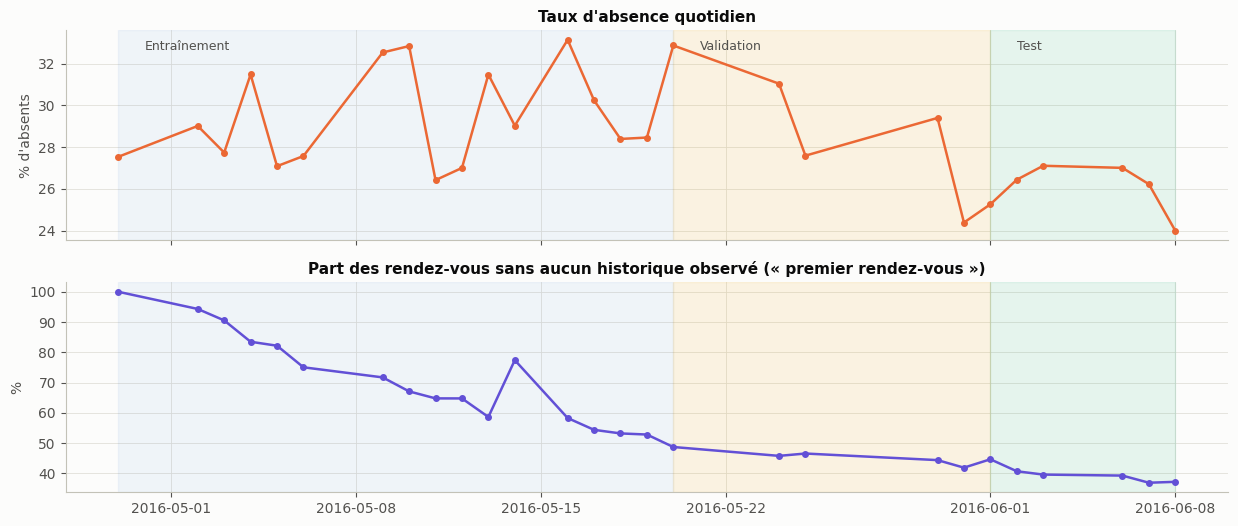

In [22]:
quotidien = df_model.groupby('date_rdv').agg(taux=('absent', 'mean'), premier=('premier_rdv', 'mean'), rdv=('absent', 'size'))
FIN_ENTRAINEMENT, FIN_VALIDATION = pd.Timestamp('2016-05-20'), pd.Timestamp('2016-06-01')
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
axes[0].plot(quotidien.index, 100 * quotidien['taux'], 'o-', color=C_ABS, ms=4)
axes[0].set(ylabel="% d'absents", title="Taux d'absence quotidien")
axes[1].plot(quotidien.index, 100 * quotidien['premier'], 'o-', color=SERIES[6], ms=4)
axes[1].set(ylabel='%', title='Part des rendez-vous sans aucun historique observé (« premier rendez-vous »)')
for ax in axes:
    ax.axvspan(quotidien.index.min(), FIN_ENTRAINEMENT, color=SERIES[0], alpha=0.06)
    ax.axvspan(FIN_ENTRAINEMENT, FIN_VALIDATION, color=SERIES[3], alpha=0.10)
    ax.axvspan(FIN_VALIDATION, quotidien.index.max(), color=SERIES[2], alpha=0.10)
for x, lab in [(quotidien.index.min(), 'Entraînement'), (FIN_ENTRAINEMENT, 'Validation'), (FIN_VALIDATION, 'Test')]:
    axes[0].text(x + pd.Timedelta(days=1), 100 * quotidien['taux'].max(), lab, color=INK2, fontsize=9, va='top')
savefig(fig, '09_evolution_temporelle')
plt.show()

**Interprétation.**
* Le taux d'absence quotidien varie entre 24 % et 33 %, avec une **tendance à la baisse** sur la période de test (24 à 27 %).
* La part des rendez-vous sans historique observé chute de **100 %** le 29 avril à **37 %** le 8 juin. Plus la période avance, plus on connaît le passé des patients.
* Les trois jeux n'ont donc pas la même composition : l'entraînement compte 70 % de rendez-vous sans historique, le test 39 %. C'est **exactement la situation d'un déploiement réel** : le modèle est appris au démarrage, puis utilisé quand l'historique s'est enrichi. Le découpage temporel mesure cet effet au lieu de le masquer.

### 6.9 Synthèse de l'analyse exploratoire
| Constat | Conséquence pour la modélisation |
|---|---|
| 35 % de rendez-vous pris le jour même, presque toujours honorés | Population restreinte aux rendez-vous pris au moins la veille |
| Aucune valeur manquante ; 11 lignes impossibles (âge, dates) | Suppression déterministe, sans imputation |
| Rendez-vous d'un même patient fortement liés (même jour, même session) | Découpage temporel, validation croisée et bootstrap **groupés par patient** |
| Effet non linéaire de l'âge (pic à 13-24 ans) et du délai (montée puis plateau) | **Splines** dans la régression logistique |
| Historique d'absences prédictif mais tronqué (58,6 % sans historique) | Variables d'historique + indicateur « premier rendez-vous observé » |
| SMS confondu avec le délai (paradoxe de Simpson) | SMS exclu des prédicteurs |
| Corrélations toutes faibles avec la cible (\|ρ\| ≤ 0,10) | Attendre une discrimination **modeste** ; privilégier la priorisation à la classification |
| Dérive du taux d'absence au fil des semaines | Découpage temporel ; surveiller la calibration |

## 7. Protocole d'évaluation, découpage et prétraitement

### 7.1 Métriques retenues et règles de décision (fixées *avant* d'entraîner les modèles)
| Métrique | Ce qu'elle mesure | Pourquoi ici |
|---|---|---|
| **PR-AUC** (précision moyenne) | Qualité du classement des rendez-vous à risque | **Métrique principale** : l'usage consiste à ordonner une liste de rappels |
| ROC-AUC | Discrimination globale | Standard ; permet la comparaison avec la littérature |
| **Rappel @ capacité** | Part des absences captées en ciblant les *k* % de rendez-vous les plus à risque | **Traduit directement la contrainte de l'équipe** : on ne peut pas appeler tout le monde |
| Sensibilité, VPP, F1 | Erreurs au seuil d'action | La VPP indique la part d'appels « utiles » |
| Brier, courbe de calibration | Fiabilité des probabilités | VIHEPAT affiche un niveau de risque : il doit correspondre à la réalité |
| Bénéfice net (*decision curve*) | Utilité selon le coût relatif d'une action inutile | Méthode de référence pour un modèle d'aide à la décision (Vickers & Elkin, 2006) |

**Règle de sélection.** On retient le modèle ayant la meilleure PR-AUC en validation. *Principe de parcimonie :* si son avantage sur la régression logistique n'est pas significatif (l'intervalle de confiance à 95 % de la différence, obtenu par bootstrap apparié, contient 0), on garde la régression logistique, plus simple et plus explicable.

**Niveaux d'action (seuils fixés par la capacité, sur la validation).** Le rappel standard (SMS ou message vocal la veille) est peu coûteux et **envoyé à tous**. Le score sert à décider des actions supplémentaires :

| Niveau | Rendez-vous concernés | Action proposée dans VIHEPAT |
|---|---|---|
| **Élevé** | Les 20 % les plus à risque | **Appel de confirmation** par un membre de l'équipe : vérifier les obstacles (transport, coût, horaire) et proposer un autre créneau |
| **Modéré** | Les 30 % suivants | **Rappel renforcé** : un second rappel à J−3, en langue locale |
| **Faible** | Les 50 % restants | Rappel standard uniquement |

La capacité de 20 % est une **hypothèse de travail** ; la section 10.1 montre ce que donnent d'autres capacités.

### 7.2 Découpage temporel train / validation / test
* **Entraînement** : rendez-vous du 29 avril au 20 mai 2016 ; **validation** : du 24 mai au 1ᵉʳ juin ; **test** : du 2 au 8 juin.
* **Pourquoi temporel ?** En production, le modèle apprend sur le passé et prédit l'avenir. Un découpage aléatoire placerait des rendez-vous d'un même jour (et d'un même patient) des deux côtés, ce qui gonfle les scores (vérifié en S2). Le découpage temporel mesure aussi l'effet de la **dérive** d'une semaine à l'autre.
* **Validation croisée groupée par patient** pour régler les hyperparamètres : les rendez-vous d'un même patient restent dans le même pli. Sinon, ses rendez-vous pris lors d'une même session (souvent identiques) se retrouveraient de part et d'autre.
* **Bootstrap par patient** (*cluster bootstrap*) pour les intervalles de confiance : les rendez-vous d'un même patient ne sont pas indépendants.

In [23]:
X, y = df_model[FEATURES], df_model['absent']
GROUPES = df_model['id_patient']
idx_train = df_model.index[df_model['date_rdv'] <= FIN_ENTRAINEMENT]
idx_val = df_model.index[(df_model['date_rdv'] > FIN_ENTRAINEMENT) & (df_model['date_rdv'] <= FIN_VALIDATION)]
idx_test = df_model.index[df_model['date_rdv'] > FIN_VALIDATION]
X_train, X_val, X_test = X.loc[idx_train], X.loc[idx_val], X.loc[idx_test]
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]
patients_train = set(GROUPES.loc[idx_train])

pd.DataFrame({jeu: {'période': f"{df_model.loc[i, 'date_rdv'].min():%d/%m} → {df_model.loc[i, 'date_rdv'].max():%d/%m/%Y}",
                    'rendez-vous': len(i), '% du total': f'{100 * len(i) / len(df_model):.1f}',
                    'patients': GROUPES.loc[i].nunique(), "% d'absents": f'{100 * y.loc[i].mean():.1f}',
                    '% premiers rendez-vous': f"{100 * df_model.loc[i, 'premier_rdv'].mean():.1f}",
                    "% de patients déjà vus à l'entraînement": f'{100 * GROUPES.loc[i].isin(patients_train).mean():.1f}'}
              for jeu, i in [('Entraînement', idx_train), ('Validation', idx_val), ('Test', idx_test)]}).T

,période,rendez-vous,% du total,patients,% d'absents,% premiers rendez-vous,% de patients déjà vus à l'entraînement
Entraînement,29/04 → 20/05/2016,43939,61.1,31959,29.6,69.5,100.0
Validation,24/05 → 01/06/2016,13608,18.9,11826,27.4,44.5,43.9
Test,02/06 → 08/06/2016,14408,20.0,12715,26.1,38.7,42.1


**Interprétation.**
* Les proportions 61 / 19 / 20 sont proches de la cible 60 / 20 / 20. La première coupure tombe sur trois jours sans aucun rendez-vous dans le jeu (21 au 23 mai), ce qui sépare nettement l'entraînement de la validation.
* Le taux d'absence **baisse** d'un jeu à l'autre (29,6 %, 27,4 %, 26,1 %) : le modèle sera évalué en conditions de dérive réelle.
* Environ **43 %** des rendez-vous de validation et de test concernent des patients déjà vus à l'entraînement. Ce n'est pas une fuite, puisque leur historique est calculé uniquement à partir des jours précédents. C'est la situation normale d'un centre qui suit ses patients dans la durée.

### 7.3 Prétraitement : transformation, standardisation, encodage
Il n'y a **aucune valeur manquante** à imputer : l'absence d'historique est portée explicitement par `premier_rdv`.

| Bloc | Traitement | Justification |
|---|---|---|
| Âge | **Spline cubique** (5 nœuds) | Effet non monotone : le risque monte de l'enfance à 18-24 ans, puis décroît (section 6.4). Une variable linéaire ne pourrait pas le représenter dans la régression logistique |
| Délai | log(1 + délai), puis **spline cubique** | Le risque augmente vite sur les premiers jours, puis plafonne : l'échelle log et la spline épousent cette forme |
| Comptages d'historique | log(1 + x), puis standardisation | Distributions très asymétriques (jusqu'à 80 rendez-vous) : le log réduit le poids des patients extrêmes |
| Heure de prise, taux lissé | Standardisation | Échelles différentes |
| Variables binaires | Inchangées (0/1) | Déjà à la bonne échelle |
| Sexe, jour de la semaine | **One-hot** | Variables nominales sans ordre |

**Standardisation.** Indispensable pour la régression logistique, car la pénalité L2 doit traiter toutes les variables à la même échelle, et pour le réseau de neurones, dont la descente de gradient converge mal sur des échelles hétérogènes. Les arbres y sont insensibles. **Un seul préprocesseur pour tous les modèles** : ils voient exactement la même information, ce qui rend la comparaison équitable.

**Rééquilibrage des classes** (SMOTE, sous-échantillonnage) : **non utilisé**. Le déséquilibre est modéré (28 % d'absents) et le rééquilibrage fausse les probabilités, alors que VIHEPAT affiche un niveau de risque.

In [24]:
def construire_preprocesseur(vars_compte=VARS_COMPTE, vars_num=VARS_NUM, vars_bin=VARS_BIN, vars_cat=VARS_CAT, vars_cat_rares=()):
    """Les arguments permettent de construire les variantes de la section 14 avec le même prétraitement."""
    log1p = FunctionTransformer(np.log1p, feature_names_out='one-to-one')
    blocs = [('age', SplineTransformer(n_knots=5, degree=3), ['age']),
             ('delai', Pipeline([('log', clone(log1p)), ('spl', SplineTransformer(n_knots=5, degree=3))]), ['delai_jours']),
             ('compte', Pipeline([('log', clone(log1p)), ('sc', StandardScaler())]), list(vars_compte)),
             ('num', StandardScaler(), list(vars_num)),
             ('bin', 'passthrough', list(vars_bin)),
             ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), list(vars_cat))]
    if vars_cat_rares:   # quartier : modalités de moins de 30 rendez-vous regroupées
        blocs.append(('rares', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False),
                      list(vars_cat_rares)))
    return ColumnTransformer([b for b in blocs if b[2]], verbose_feature_names_out=False)


def var_modele(nom):
    """Nom d'une colonne transformée → variable d'origine."""
    if '_sp_' in nom:
        return nom.rsplit('_sp_', 1)[0]
    if nom in VARIABLES:
        return nom
    return next((c for c in VARIABLES if nom.startswith(c + '_')), nom)


def libelle(nom):
    v = var_modele(nom)
    lab = VARIABLES.get(v, (v,))[0]
    if '_sp_' in nom:
        return f"{lab} (spline {nom.rsplit('_sp_', 1)[1]})"
    if nom != v:
        valeur = nom[len(v) + 1:]
        return f"{lab} = {TRAD.get(valeur, valeur)}"
    return lab


prep_fit = construire_preprocesseur().fit(X_train)                   # appris sur l'entraînement uniquement
A_train, A_val, A_test = (prep_fit.transform(d) for d in (X_train, X_val, X_test))
NOMS_A = prep_fit.get_feature_names_out()
print(f'{A_train.shape[1]} colonnes après prétraitement :')
print([libelle(n) for n in NOMS_A])

32 colonnes après prétraitement :
['Âge (spline 0)', 'Âge (spline 1)', 'Âge (spline 2)', 'Âge (spline 3)', 'Âge (spline 4)', 'Âge (spline 5)', 'Âge (spline 6)', 'Délai de prise de rendez-vous (spline 0)', 'Délai de prise de rendez-vous (spline 1)', 'Délai de prise de rendez-vous (spline 2)', 'Délai de prise de rendez-vous (spline 3)', 'Délai de prise de rendez-vous (spline 4)', 'Délai de prise de rendez-vous (spline 5)', 'Délai de prise de rendez-vous (spline 6)', 'Rendez-vous antérieurs', 'Absences antérieures', 'Rendez-vous du patient ce jour-là', 'Heure de prise du rendez-vous', "Taux d'absence antérieur (lissé)", 'Bénéficiaire Bolsa Família', 'Hypertension', 'Diabète', 'Alcoolisme', 'Handicap', 'Premier rendez-vous observé', 'Sexe = homme', 'Jour du rendez-vous = jeudi', 'Jour du rendez-vous = lundi', 'Jour du rendez-vous = mardi', 'Jour du rendez-vous = mercredi', 'Jour du rendez-vous = samedi', 'Jour du rendez-vous = vendredi']


## 8. Modélisation

Cinq approches de complexité croissante :

| Modèle | Rôle | Hypothèse |
|---|---|---|
| Référence naïve | Plancher : prédit le taux moyen pour tous | Aucun signal |
| Régression logistique | Référence **interprétable** (odds ratios, courbes d'effet) | Effets additifs sur le log-odds (non linéaires grâce aux splines) |
| Random Forest | Non linéaire, robuste, peu sensible au réglage | Interactions captées par bagging d'arbres |
| XGBoost | Boosting de gradient, souvent le meilleur sur données tabulaires | Interactions captées séquentiellement |
| MLP (réseau de neurones) | Approche *deep learning* | Représentation non linéaire apprise |

In [25]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
G_TRAIN = GROUPES.loc[idx_train]
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}
NOMS_MODELES = ['Référence naïve', 'Régression logistique', 'Random Forest', 'XGBoost', 'MLP']
COULEUR = {'Régression logistique': SERIES[0], 'Random Forest': SERIES[1], 'XGBoost': SERIES[2], 'MLP': SERIES[3]}
modeles, historiques = {}, {}


def auc_roc(y_vrai, p):
    """ROC-AUC via la statistique de Mann-Whitney : identique à roc_auc_score, bien plus rapide en bootstrap."""
    y_vrai, rangs = np.asarray(y_vrai), stats.rankdata(p)
    n1 = y_vrai.sum()
    return (rangs[y_vrai == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y_vrai) - n1))


def metriques(y_vrai, p, seuil=0.5):
    """Métriques de discrimination, de calibration et de décision au seuil donné."""
    y_vrai, p = np.asarray(y_vrai).astype(int), np.asarray(p, dtype=float)
    signale, absent = p >= seuil, y_vrai == 1
    tp, fp = int((signale & absent).sum()), int((signale & ~absent).sum())
    fn, tn = int((~signale & absent).sum()), int((~signale & ~absent).sum())
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    return {'ROC-AUC': auc_roc(y_vrai, p), 'PR-AUC': average_precision_score(y_vrai, p),
            'Brier': np.mean((p - y_vrai) ** 2), 'Log-loss': -np.mean(y_vrai * np.log(pc) + (1 - y_vrai) * np.log(1 - pc)),
            'Sensibilité': tp / (tp + fn), 'Spécificité': tn / (tn + fp),
            'VPP': tp / (tp + fp) if tp + fp else np.nan, 'VPN': tn / (tn + fn) if tn + fn else np.nan,
            'F1': 2 * tp / (2 * tp + fp + fn), '% signalés': (tp + fp) / len(y_vrai)}


def tracer_courbes(hist, x, titre, nom_fig, marque=None, refs=None):
    """Évolution de la perte et de l'AUC sur l'entraînement et la validation."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
    for ax, m, ylab in [(axes[0], 'loss', 'Log-loss (entropie croisée)'), (axes[1], 'auc', 'ROC-AUC')]:
        ax.plot(hist[x], hist[f'{m}_train'], color=SERIES[0], label='Entraînement')
        ax.plot(hist[x], hist[f'{m}_val'], color=SERIES[1], label='Validation')
        if marque is not None:
            ax.axvline(marque, color=INK2, ls='--', lw=1, label=f'retenu : {marque}')
        if refs and m in refs:
            for etiquette, valeur, couleur in refs[m]:
                ax.axhline(valeur, color=couleur, ls=':', lw=1.2, label=etiquette)
        ax.set_xlabel(x)
        ax.set_ylabel(ylab)
        ax.legend(fontsize=8)
    fig.suptitle(titre, y=1.02, fontweight='bold')
    savefig(fig, nom_fig)
    plt.show()

### 8.1 Référence naïve

In [26]:
modeles['Référence naïve'] = Pipeline([('prep', construire_preprocesseur()),
                                       ('clf', DummyClassifier(strategy='prior'))]).fit(X_train, y_train)
pd.Series(metriques(y_val, modeles['Référence naïve'].predict_proba(X_val)[:, 1]), name='validation').to_frame().T

,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,% signalés
validation,0.500,0.274,0.199,0.589,0.000,1.000,NaN,0.726,0.000,0.000


### 8.2 Régression logistique (référence interprétable)
L'intensité de la régularisation L2 (paramètre `C`) est choisie par validation croisée à 5 plis, groupée par patient.

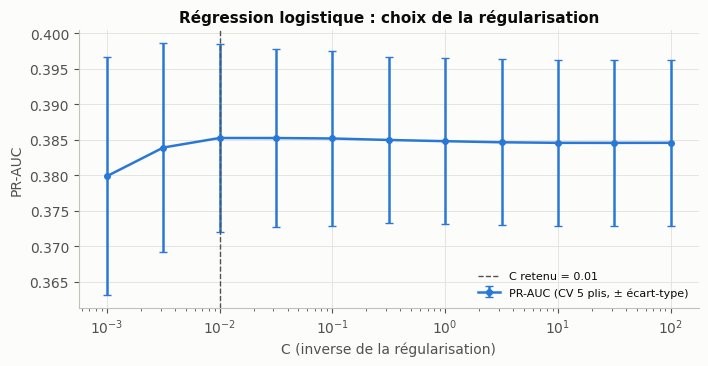

C optimal = 0.01 | PR-AUC CV = 0.385 ± 0.013


In [27]:
grille_lr = GridSearchCV(
    Pipeline([('prep', construire_preprocesseur()), ('clf', LogisticRegression(max_iter=5000))]),
    {'clf__C': np.logspace(-3, 2, 11)}, scoring=SCORING, refit='pr_auc', cv=CV, n_jobs=-1).fit(X_train, y_train, groups=G_TRAIN)
modeles['Régression logistique'] = grille_lr.best_estimator_
C_OPT = grille_lr.best_params_['clf__C']

cvr = pd.DataFrame(grille_lr.cv_results_)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(cvr['param_clf__C'].astype(float), cvr['mean_test_pr_auc'], yerr=cvr['std_test_pr_auc'],
            color=SERIES[0], marker='o', ms=4, capsize=3, label='PR-AUC (CV 5 plis, ± écart-type)')
ax.axvline(C_OPT, color=INK2, ls='--', lw=1, label=f'C retenu = {C_OPT:.3g}')
ax.set_xscale('log')
ax.set_xlabel('C (inverse de la régularisation)')
ax.set_ylabel('PR-AUC')
ax.set_title('Régression logistique : choix de la régularisation')
ax.legend(fontsize=8)
plt.show()
print(f"C optimal = {C_OPT:.3g} | PR-AUC CV = {grille_lr.best_score_:.3f} ± {cvr.loc[grille_lr.best_index_, 'std_test_pr_auc']:.3f}")

**Évolution de la perte par epoch.** La régression logistique de scikit-learn est résolue par L-BFGS, un optimiseur déterministe sans notion d'epoch. Pour visualiser l'apprentissage, on entraîne **le même modèle** (même pénalité, même préprocesseur) par descente de gradient stochastique : une epoch correspond à un passage complet sur l'entraînement. Les pointillés indiquent la perte de la solution L-BFGS, vers laquelle la SGD doit converger.

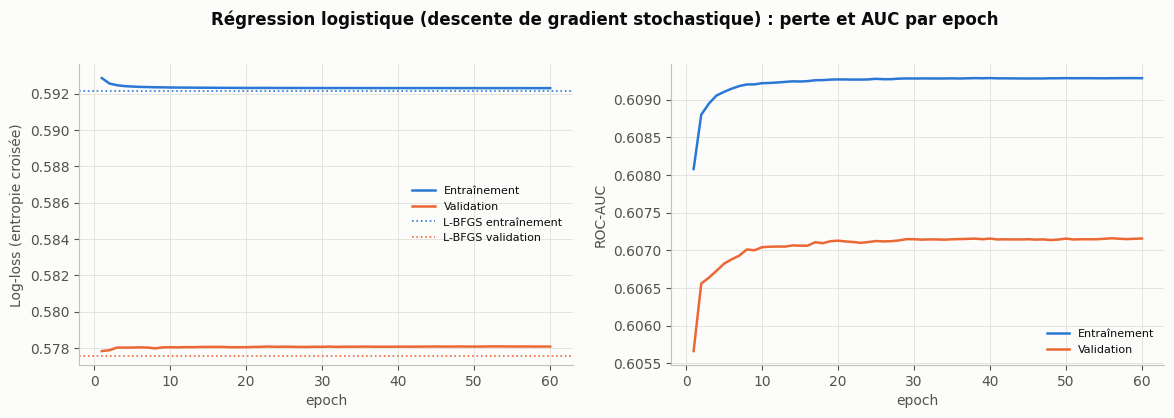

In [28]:
lr_lbfgs = modeles['Régression logistique']
refs_lr = {'loss': [('L-BFGS entraînement', log_loss(y_train, lr_lbfgs.predict_proba(X_train)[:, 1]), SERIES[0]),
                    ('L-BFGS validation', log_loss(y_val, lr_lbfgs.predict_proba(X_val)[:, 1]), SERIES[1])]}
sgd = SGDClassifier(loss='log_loss', penalty='l2', alpha=1 / (C_OPT * len(A_train)), average=True,
                    learning_rate='invscaling', eta0=0.05, power_t=0.25, random_state=SEED)   # SGD moyennée : convergence lisse
rng_sgd, hist = np.random.default_rng(SEED), []
for epoch in range(1, 61):
    ordre = rng_sgd.permutation(len(A_train))
    sgd.partial_fit(A_train[ordre], y_train.values[ordre], classes=[0, 1])
    p_tr, p_va = sgd.predict_proba(A_train)[:, 1], sgd.predict_proba(A_val)[:, 1]
    hist.append({'epoch': epoch, 'loss_train': log_loss(y_train, p_tr), 'loss_val': log_loss(y_val, p_va),
                 'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
historiques['Régression logistique'] = pd.DataFrame(hist)
tracer_courbes(historiques['Régression logistique'], 'epoch',
               'Régression logistique (descente de gradient stochastique) : perte et AUC par epoch',
               '11_courbes_lr', refs=refs_lr)

### 8.3 Random Forest
Recherche aléatoire de 15 combinaisons d'hyperparamètres en validation croisée groupée à 5 plis. Chaque arbre est appris sur 50 % des rendez-vous (`max_samples`) : le calcul est deux fois plus rapide et les arbres sont plus décorrélés.

Meilleurs hyperparamètres : {'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 10} | PR-AUC CV = 0.393


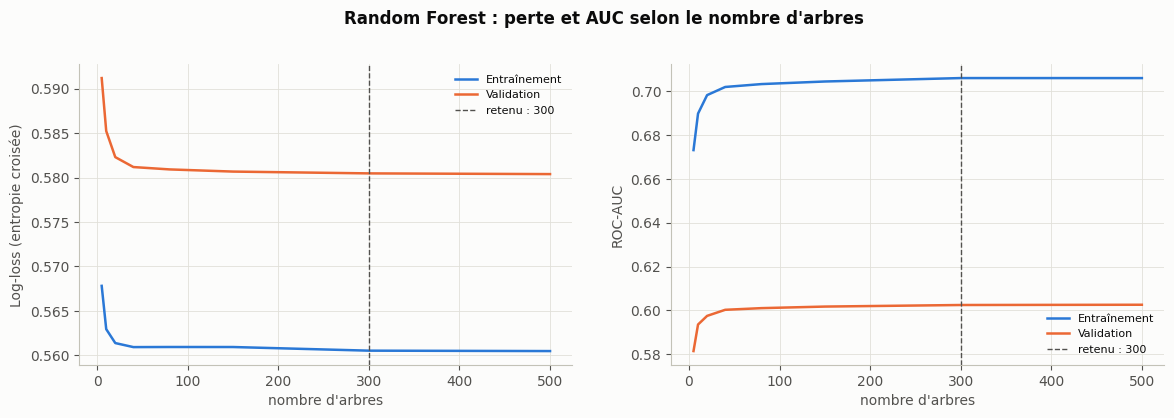

In [29]:
RF_FIXES = {'n_estimators': 300, 'max_samples': 0.5}
recherche_rf = RandomizedSearchCV(
    Pipeline([('prep', construire_preprocesseur()),
              ('clf', RandomForestClassifier(**RF_FIXES, random_state=SEED, n_jobs=1))]),
    {'clf__max_depth': [6, 8, 10, 14, None], 'clf__min_samples_leaf': [5, 10, 20, 50, 100],
     'clf__max_features': ['sqrt', 0.3, 0.5]},
    n_iter=15, scoring=SCORING, refit='pr_auc', cv=CV, random_state=SEED, n_jobs=-1).fit(X_train, y_train, groups=G_TRAIN)
modeles['Random Forest'] = recherche_rf.best_estimator_
params_rf = {k.replace('clf__', ''): v for k, v in recherche_rf.best_params_.items()}
print(f'Meilleurs hyperparamètres : {params_rf} | PR-AUC CV = {recherche_rf.best_score_:.3f}')

# Courbe de performance en fonction du nombre d'arbres (équivalent des epochs pour le bagging)
rf_courbe, hist = RandomForestClassifier(**params_rf, max_samples=0.5, warm_start=True, random_state=SEED, n_jobs=-1), []
for n in [5, 10, 20, 40, 80, 150, 300, 500]:
    rf_courbe.set_params(n_estimators=n).fit(A_train, y_train)
    p_tr, p_va = rf_courbe.predict_proba(A_train)[:, 1], rf_courbe.predict_proba(A_val)[:, 1]
    hist.append({"nombre d'arbres": n, 'loss_train': log_loss(y_train, np.clip(p_tr, 1e-6, 1 - 1e-6)),
                 'loss_val': log_loss(y_val, np.clip(p_va, 1e-6, 1 - 1e-6)),
                 'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
historiques['Random Forest'] = pd.DataFrame(hist)
tracer_courbes(historiques['Random Forest'], "nombre d'arbres",
               "Random Forest : perte et AUC selon le nombre d'arbres", '12_courbes_rf', marque=RF_FIXES['n_estimators'])

### 8.4 XGBoost
Recherche aléatoire de 30 combinaisons en validation croisée groupée à 5 plis. Le nombre d'arbres retenu est **celui de la validation croisée**. Les courbes ci-dessous (jusqu'à 2 000 itérations, arrêt 500 itérations après le minimum de la perte de validation) servent uniquement de **diagnostic** : elles vérifient que ce choix est proche de l'optimum observé sur la validation, sans utiliser la validation pour régler le modèle.

Meilleurs hyperparamètres : {'subsample': 1.0, 'reg_lambda': 20, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree': 0.5} | PR-AUC CV = 0.399


Optimum de la perte en validation : 116 arbres ; retenu par CV : 500


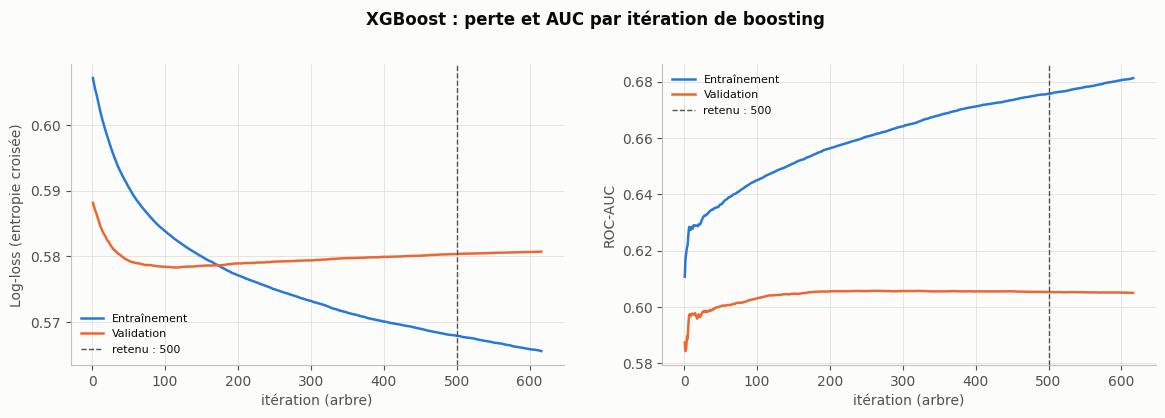

In [30]:
recherche_xgb = RandomizedSearchCV(
    Pipeline([('prep', construire_preprocesseur()),
              ('clf', xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', eval_metric='logloss',
                                        random_state=SEED, n_jobs=1))]),
    {'clf__n_estimators': [100, 200, 300, 500, 800], 'clf__learning_rate': [0.01, 0.02, 0.05, 0.1],
     'clf__max_depth': [2, 3, 4, 5, 6], 'clf__min_child_weight': [1, 5, 10, 20, 50], 'clf__subsample': [0.6, 0.8, 1.0],
     'clf__colsample_bytree': [0.5, 0.7, 1.0], 'clf__reg_lambda': [1, 5, 10, 20], 'clf__gamma': [0, 0.5, 1]},
    n_iter=30, scoring=SCORING, refit='pr_auc', cv=CV, random_state=SEED, n_jobs=-1).fit(X_train, y_train, groups=G_TRAIN)
modeles['XGBoost'] = recherche_xgb.best_estimator_
params_xgb = {k.replace('clf__', ''): v for k, v in recherche_xgb.best_params_.items()}
print(f'Meilleurs hyperparamètres : {params_xgb} | PR-AUC CV = {recherche_xgb.best_score_:.3f}')

xgb_diag = xgb.XGBClassifier(**{k: v for k, v in params_xgb.items() if k != 'n_estimators'}, n_estimators=2000,
                             early_stopping_rounds=500, eval_metric=['auc', 'logloss'], objective='binary:logistic',
                             tree_method='hist', random_state=SEED, n_jobs=-1)
xgb_diag.fit(A_train, y_train, eval_set=[(A_train, y_train), (A_val, y_val)], verbose=False)
res = xgb_diag.evals_result()
historiques['XGBoost'] = pd.DataFrame({'itération (arbre)': np.arange(1, len(res['validation_0']['logloss']) + 1),
                                       'loss_train': res['validation_0']['logloss'], 'loss_val': res['validation_1']['logloss'],
                                       'auc_train': res['validation_0']['auc'], 'auc_val': res['validation_1']['auc']})
print(f"Optimum de la perte en validation : {xgb_diag.best_iteration + 1} arbres ; retenu par CV : {params_xgb['n_estimators']}")
tracer_courbes(historiques['XGBoost'], 'itération (arbre)', 'XGBoost : perte et AUC par itération de boosting',
               '13_courbes_xgb', marque=params_xgb['n_estimators'])

### 8.5 Réseau de neurones (MLP)
* **Architecture** : 2 couches cachées (32 puis 16 neurones, ReLU) et une sortie sigmoïde.
* **Entraînement** : optimiseur Adam, mini-lots de 256, 150 epochs au plus.
* **Arrêt anticipé** : on garde les poids de l'epoch où la perte de validation est minimale (patience de 15 epochs).
* **Régularisation L2** (`alpha`) : 4 valeurs testées, de 0,001 à 1.

Ici, la validation sert à *régler* le réseau (arrêt anticipé et `alpha`). Ses scores de validation sont donc légèrement optimistes ; seul le jeu de test donne une estimation sans biais.

,meilleure epoch,log-loss validation,epochs effectuées
alpha,,,
0.001,3.000,0.580,18.000
0.010,3.000,0.580,18.000
0.100,3.000,0.580,18.000
1.000,4.000,0.579,19.000


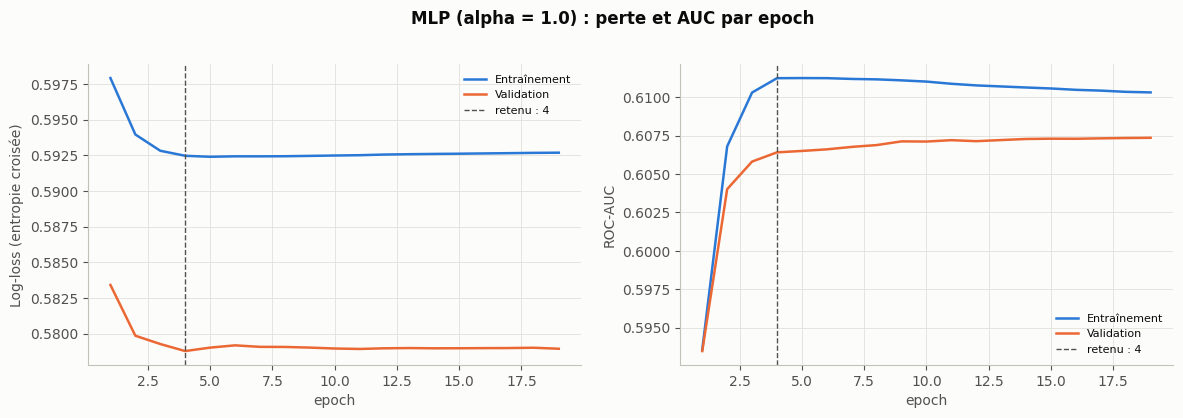

In [31]:
def entrainer_mlp(alpha, max_epochs=150, patience=15):
    mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', solver='adam', alpha=alpha,
                        batch_size=256, learning_rate_init=1e-3, random_state=SEED)
    hist, meilleur = [], (np.inf, None, 0)
    for epoch in range(1, max_epochs + 1):
        mlp.partial_fit(A_train, y_train.values, classes=np.array([0, 1]))
        p_tr, p_va = mlp.predict_proba(A_train)[:, 1], mlp.predict_proba(A_val)[:, 1]
        hist.append({'epoch': epoch, 'loss_train': log_loss(y_train, p_tr), 'loss_val': log_loss(y_val, p_va),
                     'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
        if hist[-1]['loss_val'] < meilleur[0] - 1e-4:
            meilleur = (hist[-1]['loss_val'], copy.deepcopy(mlp), epoch)
        elif epoch - meilleur[2] >= patience:
            break
    return {'modele': meilleur[1], 'hist': pd.DataFrame(hist), 'epoch': meilleur[2], 'loss_val': meilleur[0]}


essais_mlp = {alpha: entrainer_mlp(alpha) for alpha in [1e-3, 1e-2, 1e-1, 1.0]}
display(pd.DataFrame({a: {'meilleure epoch': r['epoch'], 'log-loss validation': r['loss_val'],
                          'epochs effectuées': len(r['hist'])} for a, r in essais_mlp.items()}).T.rename_axis('alpha'))
ALPHA_OPT = min(essais_mlp, key=lambda a: essais_mlp[a]['loss_val'])
mlp_retenu = essais_mlp[ALPHA_OPT]
modeles['MLP'] = Pipeline([('prep', prep_fit), ('clf', mlp_retenu['modele'])])   # préprocesseur déjà appris sur l'entraînement
historiques['MLP'] = mlp_retenu['hist']
tracer_courbes(historiques['MLP'], 'epoch', f'MLP (alpha = {ALPHA_OPT}) : perte et AUC par epoch',
               '14_courbes_mlp', marque=mlp_retenu['epoch'])

### 8.6 Courbes d'apprentissage selon la taille de l'échantillon
Elles montrent si un modèle souffre plutôt de **biais** (les deux courbes sont proches et basses) ou de **variance** (grand écart entre entraînement et validation). Elles indiquent aussi si **davantage de données** améliorerait le modèle.

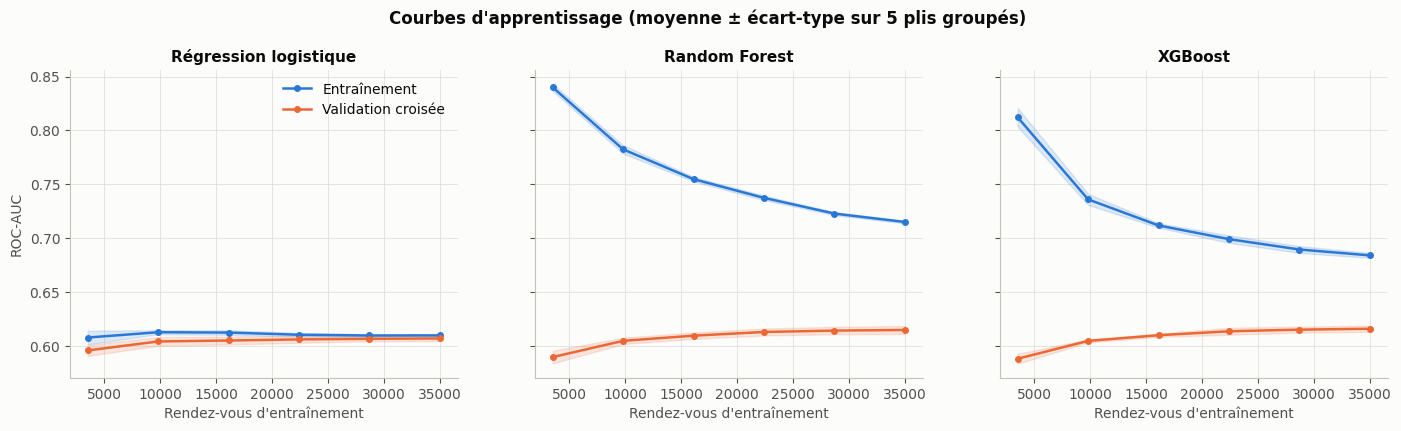

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, nom in zip(axes, ['Régression logistique', 'Random Forest', 'XGBoost']):
    tailles, sc_tr, sc_va = learning_curve(clone(modeles[nom]), X_train, y_train, groups=G_TRAIN, cv=CV, scoring='roc_auc',
                                           train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True,
                                           random_state=SEED)
    for sc, couleur, etiquette in [(sc_tr, SERIES[0], 'Entraînement'), (sc_va, SERIES[1], 'Validation croisée')]:
        ax.plot(tailles, sc.mean(axis=1), 'o-', color=couleur, ms=4, label=etiquette)
        ax.fill_between(tailles, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=couleur, alpha=0.15)
    ax.set_title(nom)
    ax.set_xlabel("Rendez-vous d'entraînement")
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
fig.suptitle("Courbes d'apprentissage (moyenne ± écart-type sur 5 plis groupés)", y=1.03, fontweight='bold')
savefig(fig, '15_courbes_apprentissage')
plt.show()

**Interprétation des courbes d'entraînement.**
* **Perte de validation inférieure à celle de l'entraînement** (régression logistique, MLP) : ce n'est pas une anomalie. La validation compte moins d'absents (27,4 % contre 29,6 %), et l'entropie d'une issue moins incertaine est plus faible. On compare donc l'**évolution** des courbes, pas leur niveau.
* **Régression logistique** : la descente de gradient atteint en une dizaine d'epochs la perte de la solution L-BFGS (pointillés). Le problème est convexe, sans surapprentissage. La régularisation retenue est forte (C = 0,01) : les variables apportent peu d'information individuellement.
* **Random Forest** : la perte de validation se stabilise dès 80 arbres. L'écart d'AUC entre entraînement (0,70) et validation (0,60) révèle de la **variance** : les arbres mémorisent des particularités de la période d'entraînement.
* **XGBoost** : la perte de validation est minimale vers **116 arbres**, puis remonte lentement pendant que celle de l'entraînement continue de baisser. C'est la signature du **surapprentissage**. La validation croisée a retenu 500 arbres (avec un pas de 0,02), au-delà de l'optimum observé ; l'écart de perte reste toutefois faible.
* **MLP** : la perte de validation atteint son minimum dès l'**epoch 4**, puis plafonne. Le réseau n'apprend rien de plus qu'un modèle linéaire (même AUC de 0,606) : il n'existe pas d'interaction complexe à découvrir dans ces variables.
* **Courbes d'apprentissage** : pour la régression logistique, entraînement et validation se rejoignent vers **0,61** dès 10 000 rendez-vous. C'est un régime de **biais** : la limite vient du **contenu informatif des variables**, pas du volume de données. Pour Random Forest et XGBoost, l'écart se resserre, mais l'AUC de validation plafonne à 0,615.

➡️ **Ajouter des rendez-vous du même type n'améliorerait presque pas le modèle. Il faut de nouvelles variables** : c'est l'argument central pour la collecte de données prévue dans VIHEPAT (section 16).

## 9. Comparaison des modèles et choix du modèle final

### 9.1 Validation croisée (entraînement) et jeu de validation

In [33]:
cv_resume = pd.DataFrame({nom: {'PR-AUC CV (moyenne)': r.cv_results_['mean_test_pr_auc'][r.best_index_],
                               'PR-AUC CV (écart-type)': r.cv_results_['std_test_pr_auc'][r.best_index_],
                               'ROC-AUC CV (moyenne)': r.cv_results_['mean_test_roc_auc'][r.best_index_],
                               'ROC-AUC CV (écart-type)': r.cv_results_['std_test_roc_auc'][r.best_index_]}
                          for nom, r in [('Régression logistique', grille_lr), ('Random Forest', recherche_rf),
                                         ('XGBoost', recherche_xgb)]}).T
display(cv_resume)

p_val = {nom: modeles[nom].predict_proba(X_val)[:, 1] for nom in NOMS_MODELES}
tab_val = pd.DataFrame({nom: metriques(y_val, p) for nom, p in p_val.items()}).T
print('Jeu de validation (métriques à seuil calculées à 0,5) :')
tab_val

,PR-AUC CV (moyenne),PR-AUC CV (écart-type),ROC-AUC CV (moyenne),ROC-AUC CV (écart-type)
Régression logistique,0.385,0.013,0.607,0.003
Random Forest,0.393,0.014,0.614,0.003
XGBoost,0.399,0.012,0.617,0.003


Jeu de validation (métriques à seuil calculées à 0,5) :


,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,% signalés
Référence naïve,0.500,0.274,0.199,0.589,0.000,1.000,NaN,0.726,0.000,0.000
Régression logistique,0.608,0.363,0.195,0.578,0.034,0.986,0.474,0.730,0.064,0.020
Random Forest,0.602,0.357,0.197,0.580,0.070,0.967,0.445,0.734,0.121,0.043
XGBoost,0.605,0.354,0.197,0.580,0.080,0.960,0.430,0.734,0.134,0.051
MLP,0.606,0.362,0.196,0.579,0.003,0.999,0.545,0.726,0.006,0.002


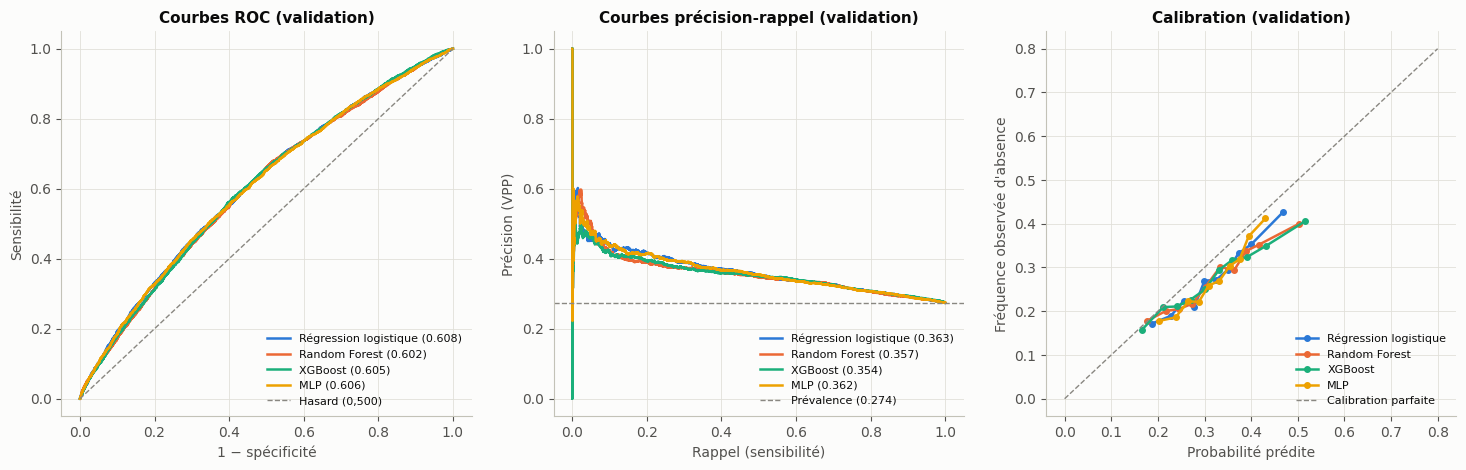

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for nom in NOMS_MODELES[1:]:
    p = p_val[nom]
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=COULEUR[nom], label=f'{nom} ({roc_auc_score(y_val, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=COULEUR[nom], label=f'{nom} ({average_precision_score(y_val, p):.3f})')
    frac, moy = calibration_curve(y_val, p, n_bins=10, strategy='quantile')
    axes[2].plot(moy, frac, 'o-', ms=4, color=COULEUR[nom], label=nom)
axes[0].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='Hasard (0,500)')
axes[0].set(xlabel='1 − spécificité', ylabel='Sensibilité', title='Courbes ROC (validation)')
axes[1].axhline(y_val.mean(), color=MUTED, ls='--', lw=1, label=f'Prévalence ({y_val.mean():.3f})')
axes[1].set(xlabel='Rappel (sensibilité)', ylabel='Précision (VPP)', title='Courbes précision-rappel (validation)')
axes[2].plot([0, 0.8], [0, 0.8], color=MUTED, ls='--', lw=1, label='Calibration parfaite')
axes[2].set(xlabel='Probabilité prédite', ylabel="Fréquence observée d'absence", title='Calibration (validation)')
for ax in axes:
    ax.legend(fontsize=8, loc='lower right')
savefig(fig, '16_comparaison_validation')
plt.show()

### 9.2 Les écarts sont-ils significatifs ? Bootstrap apparié par patient
On rééchantillonne 1 000 fois les **patients** de validation (avec tous leurs rendez-vous). Pour chaque tirage, on calcule l'écart entre chaque modèle et la régression logistique *sur les mêmes rendez-vous*. Si l'intervalle à 95 % contient 0, l'écart n'est pas significatif.

In [35]:
def tirages_grappes(groupes, n=1000, seed=SEED):
    """Indices de rendez-vous pour n tirages bootstrap de patients (avec remise)."""
    codes = pd.factorize(np.asarray(groupes))[0]
    n_g, rng = codes.max() + 1, np.random.default_rng(seed)
    for _ in range(n):
        poids = np.bincount(rng.integers(0, n_g, n_g), minlength=n_g)
        yield np.repeat(np.arange(len(codes)), poids[codes])


def bootstrap_diff(y_vrai, p1, p2, fn, groupes, n=1000):
    y_vrai, ecarts = np.asarray(y_vrai), []
    for i in tirages_grappes(groupes, n):
        ecarts.append(fn(y_vrai[i], p1[i]) - fn(y_vrai[i], p2[i]))
    return np.mean(ecarts), *np.percentile(ecarts, [2.5, 97.5])


ecarts = []
for nom in ['Random Forest', 'XGBoost', 'MLP']:
    for metrique, fn in [('PR-AUC', average_precision_score), ('ROC-AUC', auc_roc)]:
        m, bas, haut = bootstrap_diff(y_val, p_val[nom], p_val['Régression logistique'], fn, GROUPES.loc[idx_val])
        ecarts.append({'modèle': nom, 'métrique': metrique, 'écart vs régression logistique': m,
                       'IC95 bas': bas, 'IC95 haut': haut, 'significatif': 'oui' if bas > 0 or haut < 0 else 'non'})
ecarts = pd.DataFrame(ecarts).set_index(['modèle', 'métrique'])
ecarts

écart vs régression logistique  IC95 bas  IC95 haut significatif
modèle        métrique                                                                  
Random Forest PR-AUC                            -0.006    -0.014      0.003          non
              ROC-AUC                           -0.005    -0.011      0.000          non
XGBoost       PR-AUC                            -0.008    -0.017      0.000          non
              ROC-AUC                           -0.002    -0.008      0.003          non
MLP           PR-AUC                            -0.001    -0.005      0.005          non
              ROC-AUC                           -0.001    -0.004      0.002          non

In [36]:
# Application de la règle de sélection déclarée en 7.1
candidats = ['Régression logistique', 'Random Forest', 'XGBoost', 'MLP']
meilleur = max(candidats, key=lambda n: tab_val.loc[n, 'PR-AUC'])
if meilleur != 'Régression logistique' and ecarts.loc[(meilleur, 'PR-AUC'), 'IC95 bas'] > 0:
    NOM_FINAL = meilleur
    raison = 'PR-AUC de validation la plus élevée et gain significatif sur la régression logistique'
else:
    NOM_FINAL = 'Régression logistique'
    raison = ('meilleur modèle' if meilleur == 'Régression logistique'
              else f"{meilleur} n'apporte pas de gain significatif : parcimonie")
modele_final = modeles[NOM_FINAL]
print(f'Meilleure PR-AUC de validation : {meilleur} ({tab_val.loc[meilleur, "PR-AUC"]:.3f})')
print(f'MODÈLE FINAL : {NOM_FINAL} ({raison})')

Meilleure PR-AUC de validation : Régression logistique (0.363)
MODÈLE FINAL : Régression logistique (meilleur modèle)


### 9.3 Seuils des niveaux d'action (sur la validation)
Les seuils sont les quantiles des scores de validation correspondant aux capacités fixées en 7.1 : **20 %** des rendez-vous en niveau élevé, **50 %** en niveau modéré ou élevé.

Seuil « élevé » (20 % les plus à risque) : 0.385 | seuil « modéré » (50 %) : 0.312 | seuil maximisant F1 : 0.288


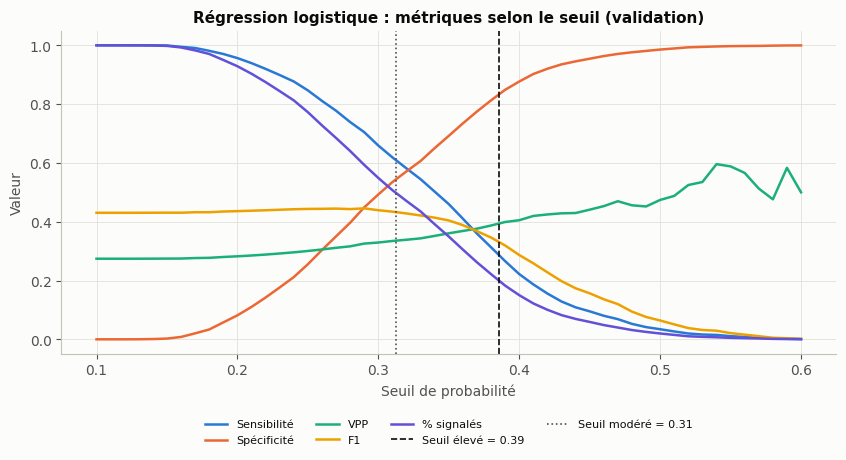

,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,% signalés
seuil élevé (0.39),0.608,0.363,0.195,0.578,0.284,0.832,0.390,0.755,0.329,0.200
seuil modéré (0.31),0.608,0.363,0.195,0.578,0.612,0.542,0.336,0.787,0.434,0.500
seuil F1 (0.29),0.608,0.363,0.195,0.578,0.711,0.442,0.325,0.802,0.446,0.600


In [37]:
CAPACITE_APPEL, CAPACITE_RAPPEL = 0.20, 0.50
p_val_final = p_val[NOM_FINAL]
SEUIL_ELEVE = float(np.quantile(p_val_final, 1 - CAPACITE_APPEL))     # appel de confirmation
SEUIL_MODERE = float(np.quantile(p_val_final, 1 - CAPACITE_RAPPEL))   # rappel renforcé
prec, rec, seuils = precision_recall_curve(y_val, p_val_final)
f1_par_seuil = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
SEUIL_F1 = float(seuils[f1_par_seuil.argmax()])


def niveau_risque(p):
    return 'élevé' if p >= SEUIL_ELEVE else ('modéré' if p >= SEUIL_MODERE else 'faible')


print(f'Seuil « élevé » (20 % les plus à risque) : {SEUIL_ELEVE:.3f} | seuil « modéré » (50 %) : {SEUIL_MODERE:.3f} '
      f'| seuil maximisant F1 : {SEUIL_F1:.3f}')
grille_fine = np.linspace(0.10, 0.60, 51)
courbe = pd.DataFrame([metriques(y_val, p_val_final, t) for t in grille_fine], index=grille_fine)
fig, ax = plt.subplots(figsize=(10, 4.2))
for m, couleur in [('Sensibilité', SERIES[0]), ('Spécificité', SERIES[1]), ('VPP', SERIES[2]), ('F1', SERIES[3]), ('% signalés', SERIES[6])]:
    ax.plot(courbe.index, courbe[m], color=couleur, label=m)
ax.axvline(SEUIL_ELEVE, color=INK, ls='--', lw=1.2, label=f'Seuil élevé = {SEUIL_ELEVE:.2f}')
ax.axvline(SEUIL_MODERE, color=INK2, ls=':', lw=1.2, label=f'Seuil modéré = {SEUIL_MODERE:.2f}')
ax.set(xlabel='Seuil de probabilité', ylabel='Valeur', title=f'{NOM_FINAL} : métriques selon le seuil (validation)')
ax.legend(fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.17))
savefig(fig, '17_choix_seuil')
plt.show()
pd.DataFrame({f'seuil élevé ({SEUIL_ELEVE:.2f})': metriques(y_val, p_val_final, SEUIL_ELEVE),
              f'seuil modéré ({SEUIL_MODERE:.2f})': metriques(y_val, p_val_final, SEUIL_MODERE),
              f'seuil F1 ({SEUIL_F1:.2f})': metriques(y_val, p_val_final, SEUIL_F1)}).T

**Interprétation.**
* **Validation croisée (période d'entraînement)** : XGBoost (PR-AUC 0,399) devance Random Forest (0,393) et la régression logistique (0,385).
* **Validation temporelle (semaine suivante)** : l'ordre **s'inverse**. La régression logistique (0,363) devance le MLP (0,362), Random Forest (0,357) et XGBoost (0,354). L'avantage des modèles flexibles tient à des régularités propres à la période d'entraînement, qui ne se maintiennent pas la semaine suivante. Le découpage temporel joue ici pleinement son rôle (voir aussi S2).
* **Bootstrap apparié par patient** : aucun écart n'est significatif, et tous sont *négatifs* par rapport à la régression logistique. La règle fixée à l'avance retient la régression logistique **comme meilleur modèle**, sans même recourir au principe de parcimonie.
* **Calibration** : tous les modèles surestiment légèrement le risque en validation (points sous la diagonale), conséquence de la baisse du taux d'absence.
* **Seuils** : le niveau « élevé » commence à **0,385** et le niveau « modéré » à **0,312**. Au seuil élevé (20 % des rendez-vous), **39 %** des rendez-vous signalés sont réellement manqués, contre 27 % en moyenne, et 28 % des absences sont détectées. Le seuil maximisant le F1 (0,288) signalerait 60 % des rendez-vous, ce qui est incompatible avec la capacité d'une équipe. D'où le choix de seuils fondés sur la capacité.

## 10. Évaluation finale sur le jeu de test
Le jeu de test (2 au 8 juin 2016) n'a servi à **aucune** décision jusqu'ici. Les intervalles de confiance à 95 % sont obtenus par bootstrap par patient (1 000 rééchantillonnages). Les métriques à seuil sont calculées au **seuil « élevé »** (appel de confirmation).

In [38]:
def bootstrap_metriques(y_vrai, p, seuil, groupes, n=1000):
    y_vrai, p = np.asarray(y_vrai), np.asarray(p)
    tirages = [metriques(y_vrai[i], p[i], seuil) for i in tirages_grappes(groupes, n)]
    return pd.DataFrame(tirages).quantile([0.025, 0.975]).T


p_test = {nom: modeles[nom].predict_proba(X_test)[:, 1] for nom in NOMS_MODELES}
p_final_test = p_test[NOM_FINAL]

ic_test = bootstrap_metriques(y_test, p_final_test, SEUIL_ELEVE, GROUPES.loc[idx_test])
resultats_test = pd.DataFrame({'valeur': pd.Series(metriques(y_test, p_final_test, SEUIL_ELEVE)),
                               'IC95 bas': ic_test[0.025], 'IC95 haut': ic_test[0.975]})
print(f"{NOM_FINAL} sur le jeu de test (n = {len(y_test)} rendez-vous, seuil élevé = {SEUIL_ELEVE:.3f}) :")
display(resultats_test)

tab_test = pd.DataFrame({nom: {k: v for k, v in metriques(y_test, p).items() if k in ('ROC-AUC', 'PR-AUC', 'Brier')}
                         for nom, p in p_test.items()}).T
print(f"Calibration globale : risque moyen prédit {p_final_test.mean():.1%} vs taux observé {y_test.mean():.1%}")
print('Transparence : tous les modèles sur le test (aucun choix ne repose sur ce tableau) :')
tab_test

Régression logistique sur le jeu de test (n = 14408 rendez-vous, seuil élevé = 0.385) :


,valeur,IC95 bas,IC95 haut
ROC-AUC,0.602,0.590,0.613
PR-AUC,0.342,0.327,0.359
Brier,0.190,0.187,0.193
Log-loss,0.567,0.560,0.574
Sensibilité,0.240,0.226,0.255
Spécificité,0.859,0.851,0.866
VPP,0.376,0.354,0.398
VPN,0.762,0.753,0.770
F1,0.293,0.277,0.309
% signalés,0.167,0.161,0.174


Calibration globale : risque moyen prédit 30.4% vs taux observé 26.1%
Transparence : tous les modèles sur le test (aucun choix ne repose sur ce tableau) :


,ROC-AUC,PR-AUC,Brier
Référence naïve,0.500,0.261,0.194
Régression logistique,0.602,0.342,0.190
Random Forest,0.603,0.338,0.191
XGBoost,0.601,0.336,0.192
MLP,0.600,0.338,0.190


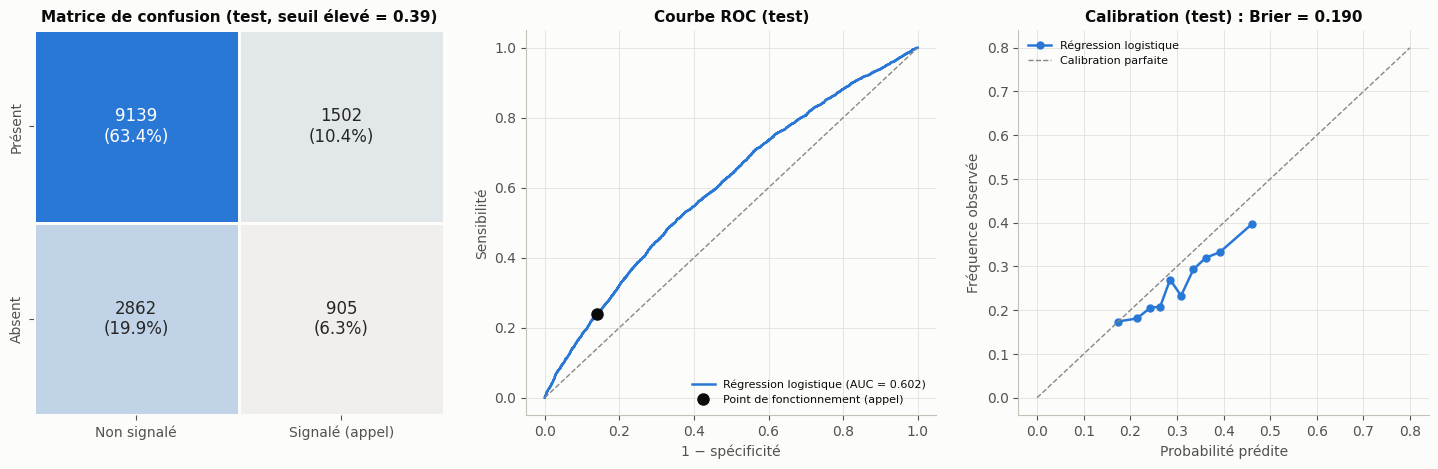

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test, (p_final_test >= SEUIL_ELEVE).astype(int))
sns.heatmap(cm, annot=np.array([[f'{v}\n({v / cm.sum():.1%})' for v in ligne] for ligne in cm]), fmt='',
            cmap=LinearSegmentedColormap.from_list('seq', ['#f0efec', '#2a78d6']), cbar=False, ax=axes[0],
            xticklabels=['Non signalé', 'Signalé (appel)'], yticklabels=['Présent', 'Absent'],
            annot_kws={'size': 12}, linewidths=2, linecolor=SURFACE)
axes[0].set_title(f'Matrice de confusion (test, seuil élevé = {SEUIL_ELEVE:.2f})')

fpr, tpr, _ = roc_curve(y_test, p_final_test)
axes[1].plot(fpr, tpr, color=COULEUR[NOM_FINAL], label=f'{NOM_FINAL} (AUC = {roc_auc_score(y_test, p_final_test):.3f})')
if NOM_FINAL != 'Régression logistique':
    fpr2, tpr2, _ = roc_curve(y_test, p_test['Régression logistique'])
    axes[1].plot(fpr2, tpr2, color=COULEUR['Régression logistique'], lw=1.2,
                 label=f"Régression logistique (AUC = {roc_auc_score(y_test, p_test['Régression logistique']):.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1)
pt = metriques(y_test, p_final_test, SEUIL_ELEVE)
axes[1].plot(1 - pt['Spécificité'], pt['Sensibilité'], 'o', color=INK, ms=8, label='Point de fonctionnement (appel)')
axes[1].set(xlabel='1 − spécificité', ylabel='Sensibilité', title='Courbe ROC (test)')
axes[1].legend(fontsize=8, loc='lower right')

frac, moy = calibration_curve(y_test, p_final_test, n_bins=10, strategy='quantile')
axes[2].plot(moy, frac, 'o-', color=COULEUR[NOM_FINAL], ms=5, label=NOM_FINAL)
axes[2].plot([0, 0.8], [0, 0.8], color=MUTED, ls='--', lw=1, label='Calibration parfaite')
axes[2].set(xlabel='Probabilité prédite', ylabel='Fréquence observée',
            title=f"Calibration (test) : Brier = {brier_score_loss(y_test, p_final_test):.3f}")
axes[2].legend(fontsize=8)
savefig(fig, '18_evaluation_test')
plt.show()

### 10.1 Utilité opérationnelle : courbe de décision et rappel selon la capacité
* **Courbe de décision** : le *bénéfice net* soustrait aux absences correctement ciblées les actions inutiles, pondérées par le seuil. Le seuil traduit l'arbitrage de l'équipe : « j'agis si le risque dépasse *p* ». Un modèle est utile là où sa courbe dépasse à la fois « agir pour tous » et « n'agir pour personne ».
* **Capacité** : si l'équipe peut traiter *k* % des rendez-vous, quelle part des absences atteint-elle ?

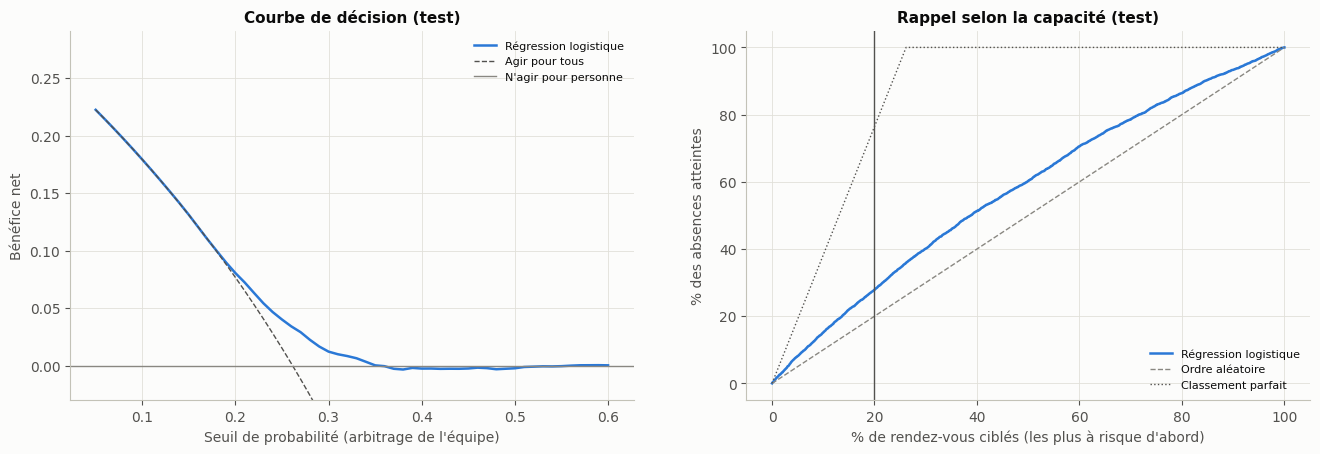

,rendez-vous ciblés,% des absences atteintes,précision (absents parmi ciblés),gain vs hasard (×)
% ciblés,,,,
10%,1441,15.158,39.625,1.516
20%,2882,27.874,36.433,1.393
30%,4322,40.111,34.961,1.337
40%,5763,51.341,33.559,1.284
50%,7204,60.260,31.510,1.205


In [40]:
def benefice_net(y_vrai, p, seuil):
    y_vrai, signale, n = np.asarray(y_vrai), np.asarray(p) >= seuil, len(y_vrai)
    vp, fp = (signale & (y_vrai == 1)).sum(), (signale & (y_vrai == 0)).sum()
    return vp / n - fp / n * seuil / (1 - seuil)


seuils_dca = np.linspace(0.05, 0.60, 56)
prev = y_test.mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].plot(seuils_dca, [benefice_net(y_test, p_final_test, s) for s in seuils_dca], color=COULEUR[NOM_FINAL], label=NOM_FINAL)
axes[0].plot(seuils_dca, prev - (1 - prev) * seuils_dca / (1 - seuils_dca), color=INK2, ls='--', lw=1, label='Agir pour tous')
axes[0].axhline(0, color=MUTED, lw=1, label="N'agir pour personne")
axes[0].set_ylim(-0.03, prev + 0.03)
axes[0].set(xlabel="Seuil de probabilité (arbitrage de l'équipe)", ylabel='Bénéfice net', title='Courbe de décision (test)')
axes[0].legend(fontsize=8)

ordre = np.argsort(-p_final_test)
y_trie = y_test.values[ordre]
part = np.arange(1, len(y_trie) + 1) / len(y_trie)
axes[1].plot(100 * part, 100 * np.cumsum(y_trie) / y_trie.sum(), color=COULEUR[NOM_FINAL], label=NOM_FINAL)
axes[1].plot([0, 100], [0, 100], color=MUTED, ls='--', lw=1, label='Ordre aléatoire')
axes[1].plot(100 * part, 100 * np.minimum(part / prev, 1), color=INK2, ls=':', lw=1, label='Classement parfait')
axes[1].axvline(100 * CAPACITE_APPEL, color=INK2, lw=1)
axes[1].set(xlabel='% de rendez-vous ciblés (les plus à risque d\'abord)', ylabel='% des absences atteintes',
            title='Rappel selon la capacité (test)')
axes[1].legend(fontsize=8, loc='lower right')
savefig(fig, '19_utilite_operationnelle')
plt.show()

capacite = []
for k in [0.10, 0.20, 0.30, 0.40, 0.50]:
    n_k = int(round(k * len(y_trie)))
    capacite.append({'% ciblés': f'{k:.0%}', 'rendez-vous ciblés': n_k,
                     '% des absences atteintes': 100 * y_trie[:n_k].sum() / y_trie.sum(),
                     "précision (absents parmi ciblés)": 100 * y_trie[:n_k].mean(),
                     'gain vs hasard (×)': y_trie[:n_k].mean() / prev})
pd.DataFrame(capacite).set_index('% ciblés')

In [41]:
# Niveaux d'action affichés dans VIHEPAT : taux d'absence observé par niveau (test)
niveaux = pd.Series([niveau_risque(p) for p in p_final_test], index=X_test.index)
pd.DataFrame({'rendez-vous': niveaux.value_counts(), '% des rendez-vous': 100 * niveaux.value_counts(normalize=True),
              '% réellement absents': 100 * y_test.groupby(niveaux).mean(),
              '% des absences du test': 100 * y_test.groupby(niveaux).sum() / y_test.sum()}).reindex(['faible', 'modéré', 'élevé'])

,rendez-vous,% des rendez-vous,% réellement absents,% des absences du test
faible,8133,56.448,21.038,45.421
modéré,3868,26.846,29.757,30.555
élevé,2407,16.706,37.599,24.024


**Interprétation des résultats sur le jeu de test.**
* **Discrimination** : ROC-AUC **0,602** [0,590-0,613] et PR-AUC **0,342** [0,327-0,359], pour un plancher de 0,261. Le modèle classe mieux que le hasard, avec un gain **modeste mais certain** (l'intervalle exclut nettement le plancher). Les quatre modèles obtiennent tous entre 0,600 et 0,603 : le plafond tient aux données, pas à l'algorithme.
* **Point de fonctionnement « appel »** : 16,7 % des rendez-vous sont signalés, au lieu des 20 % visés, en raison de la dérive. Parmi eux, **37,6 %** sont réellement manqués (VPP) ; ils représentent 24 % des absences (sensibilité).
* **Niveaux d'action** : le taux d'absence passe de **21,0 %** (faible) à **29,8 %** (modéré) puis **37,6 %** (élevé). La gradation est nette et monotone : c'est l'usage visé.
* **Capacité** : en ciblant 10 % des rendez-vous, l'équipe atteint 15 % des absences (1,5 fois le hasard) ; avec 20 %, 28 % des absences ; avec 50 %, 60 %.
* **Courbe de décision** : le modèle apporte un bénéfice net supérieur aux deux stratégies simples pour des seuils d'action **entre environ 20 % et 35 %**. Autrement dit, il est utile quand l'équipe juge qu'un appel vaut la peine dès que le risque dépasse 20 à 35 %. En dessous, autant agir pour tous (le rappel standard universel) ; au-dessus, presque personne n'atteint ce risque.
* **Calibration** : le risque moyen prédit (30,4 %) dépasse le taux observé (26,1 %) de 4 points, en raison de la dérive. L'**ordre** des patients reste valable, mais le pourcentage affiché devra être **recalibré régulièrement** sur les données récentes.

➡️ Le modèle n'est pas un outil de diagnostic d'absence. C'est un outil de **gradation** : il concentre l'effort de l'équipe sur des rendez-vous près de deux fois plus à risque que les autres.

## 11. Explicabilité
Un soignant ne fera confiance au score que s'il comprend **pourquoi** un rendez-vous est signalé. On croise trois éclairages :
1. **Régression logistique** : courbes d'effet de l'âge et du délai, odds ratios des autres facteurs.
2. **SHAP** (*SHapley Additive exPlanations*) sur le modèle final : contribution de chaque variable à *chaque* prédiction. Les contributions des colonnes d'une même variable (bases de spline, modalités) sont additionnées.
3. **Importance par permutation** : perte de performance quand on brouille une variable. Cette méthode ne dépend pas du type de modèle.

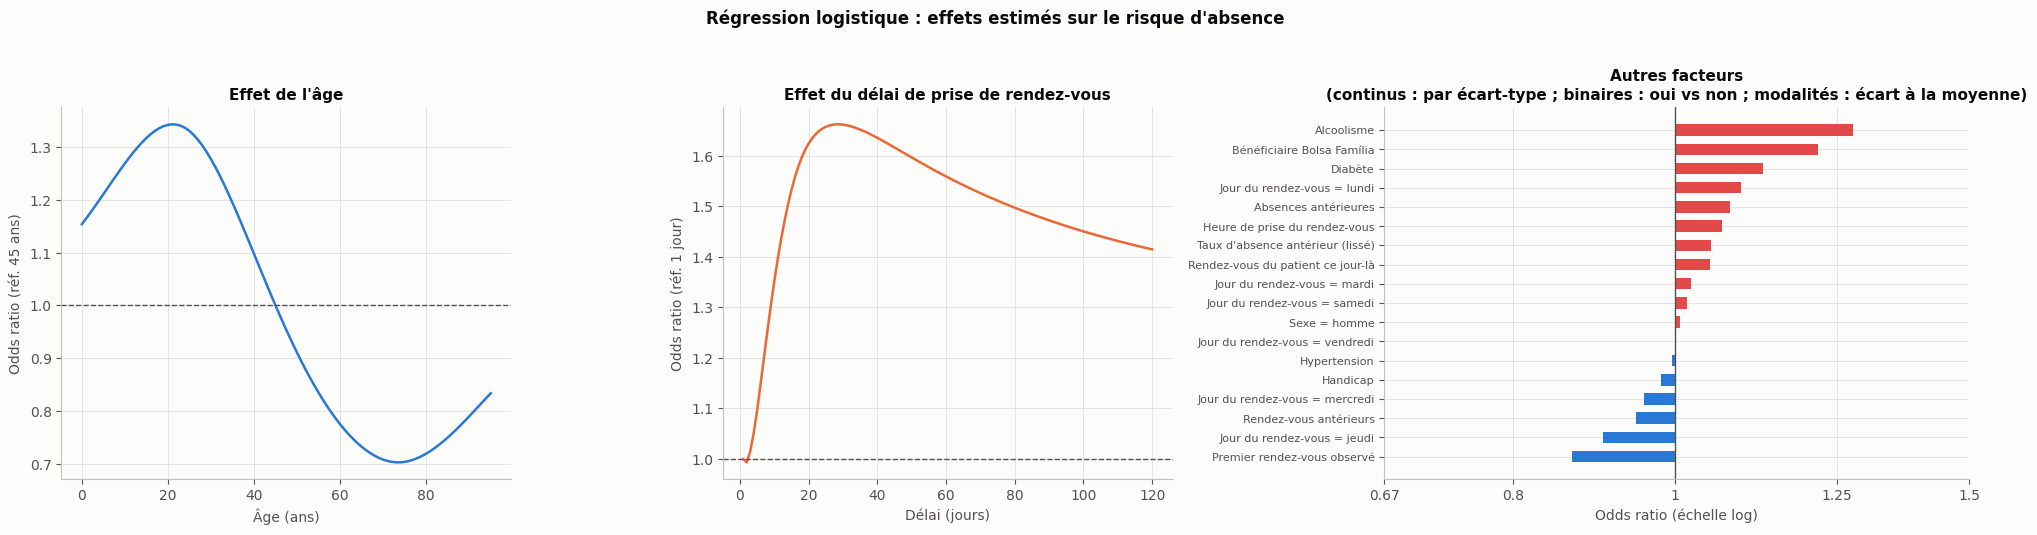

Âge : odds ratio maximal 1.34 à 21 ans, minimal 0.70 à 74 ans (référence 45 ans)
Délai : odds ratio maximal 1.66 à 29 jours, 1.42 à 120 jours (référence 1 jour)


,Premier rendez-vous observé,Jour du rendez-vous = jeudi,Rendez-vous antérieurs,Jour du rendez-vous = mercredi,Handicap,Hypertension,Jour du rendez-vous = vendredi,Sexe = homme,Jour du rendez-vous = samedi,Jour du rendez-vous = mardi,Rendez-vous du patient ce jour-là,Taux d'absence antérieur (lissé),Heure de prise du rendez-vous,Absences antérieures,Jour du rendez-vous = lundi,Diabète,Bénéficiaire Bolsa Família,Alcoolisme
odds ratio,0.870,0.910,0.950,0.960,0.980,1.000,1.000,1.010,1.020,1.020,1.050,1.050,1.070,1.080,1.100,1.130,1.220,1.280


In [42]:
lr = modeles['Régression logistique']
prep_lr, clf_lr = lr.named_steps['prep'], lr.named_steps['clf']
coefs = pd.Series(clf_lr.coef_[0], index=prep_lr.get_feature_names_out())


def effet(var, valeurs, reference):
    """Odds ratio d'une variable spline par rapport à une valeur de référence (autres variables fixées)."""
    bloc = 'age' if var == 'age' else 'delai'
    base = prep_lr.named_transformers_[bloc].transform(pd.DataFrame({var: np.r_[reference, valeurs]}))
    noms = [n for n in coefs.index if n.startswith(var + '_sp_')]
    logit = base @ coefs[noms].values
    return np.exp(logit[1:] - logit[0])


fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={'width_ratios': [1, 1, 1.3]})
ages = np.arange(0, 96)
axes[0].plot(ages, effet('age', ages, 45), color=SERIES[0])
axes[0].axhline(1, color=INK2, lw=1, ls='--')
axes[0].set(xlabel='Âge (ans)', ylabel='Odds ratio (réf. 45 ans)', title="Effet de l'âge")
delais = np.arange(1, 121)
axes[1].plot(delais, effet('delai_jours', delais, 1), color=SERIES[1])
axes[1].axhline(1, color=INK2, lw=1, ls='--')
axes[1].set(xlabel='Délai (jours)', ylabel='Odds ratio (réf. 1 jour)', title='Effet du délai de prise de rendez-vous')

autres = np.exp(coefs[[n for n in coefs.index if '_sp_' not in n]]).sort_values()
autres.index = [libelle(n) for n in autres.index]
axes[2].barh(range(len(autres)), np.log(autres.values), color=[SERIES[0] if v < 1 else SERIES[7] for v in autres.values], height=0.6)
axes[2].set_yticks(range(len(autres)), autres.index, fontsize=8)
ticks = [0.67, 0.8, 1, 1.25, 1.5]
axes[2].set_xticks(np.log(ticks), [str(t) for t in ticks])
axes[2].axvline(0, color=INK2, lw=1)
axes[2].set(xlabel='Odds ratio (échelle log)', title='Autres facteurs\n(continus : par écart-type ; binaires : oui vs non ; modalités : écart à la moyenne)')
fig.suptitle('Régression logistique : effets estimés sur le risque d\'absence', y=1.02, fontweight='bold')
fig.tight_layout()
savefig(fig, '20_effets_regression_logistique')
plt.show()

or_age, or_delai = effet('age', ages, 45), effet('delai_jours', delais, 1)
print(f'Âge : odds ratio maximal {or_age.max():.2f} à {ages[or_age.argmax()]} ans, minimal {or_age.min():.2f} '
      f'à {ages[or_age.argmin()]} ans (référence 45 ans)')
print(f'Délai : odds ratio maximal {or_delai.max():.2f} à {delais[or_delai.argmax()]} jours, {or_delai[-1]:.2f} à '
      f'{delais[-1]} jours (référence 1 jour)')
autres.round(2).to_frame('odds ratio').T

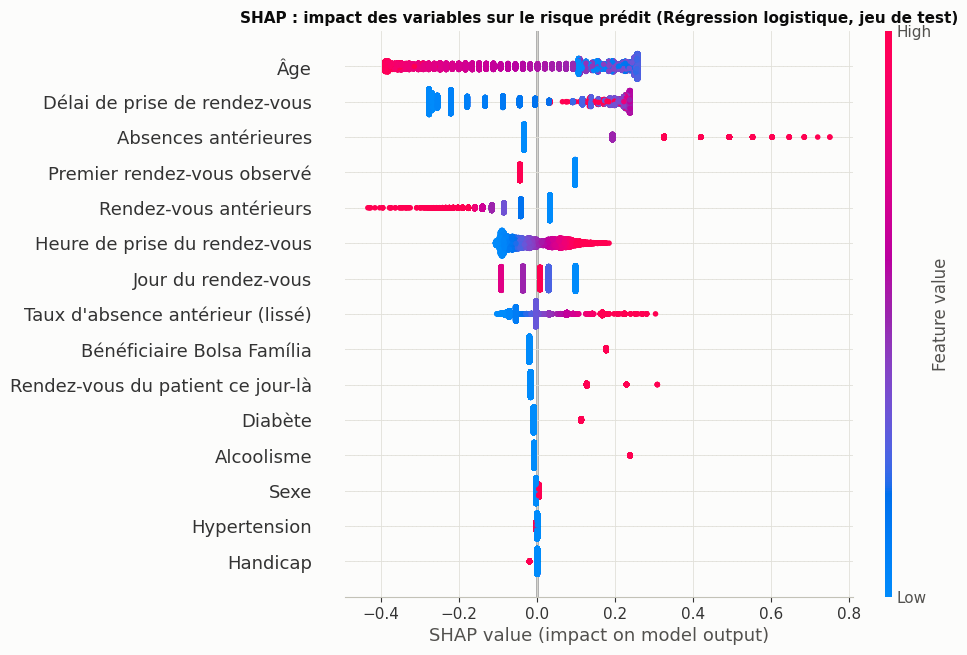

In [43]:
def valeurs_shap(modele, X_fond, X_cible):
    """Valeurs SHAP adaptées au type de modèle (log-odds pour XGBoost et la régression logistique)."""
    prep, clf = modele.named_steps['prep'], modele.named_steps['clf']
    A_fond, A_cible = prep.transform(X_fond), prep.transform(X_cible)
    if isinstance(clf, xgb.XGBClassifier):
        # TreeSHAP exact calculé nativement par XGBoost (contourne une incompatibilité shap 0.49 / xgboost 3)
        contributions = clf.get_booster().predict(xgb.DMatrix(A_cible), pred_contribs=True)
        sv, base = contributions[:, :-1], float(contributions[0, -1])
    elif isinstance(clf, RandomForestClassifier):
        explicateur = shap.TreeExplainer(clf)
        sv = explicateur.shap_values(A_cible)
        sv = sv[1] if isinstance(sv, list) else sv
        sv = sv[:, :, 1] if sv.ndim == 3 else sv
        base = np.ravel(explicateur.expected_value)[-1]
    elif isinstance(clf, LogisticRegression):
        explicateur = shap.LinearExplainer(clf, A_fond)
        sv, base = explicateur.shap_values(A_cible), explicateur.expected_value
    else:
        fond = shap.sample(A_fond, 100, random_state=SEED)
        explicateur = shap.KernelExplainer(lambda a: clf.predict_proba(a)[:, 1], fond)
        sv, base = explicateur.shap_values(A_cible[:500], nsamples=200), explicateur.expected_value
    return np.asarray(sv), base, prep.get_feature_names_out()


sv_test, base_shap, noms_shap = valeurs_shap(modele_final, X_train, X_test)
contrib_groupes = pd.DataFrame(sv_test, columns=noms_shap, index=X_test.index[:len(sv_test)]).T.groupby(var_modele).sum().T
couleur_valeurs = X_test.loc[contrib_groupes.index, contrib_groupes.columns].assign(
    sexe=lambda d: (d['sexe'] == 'M').astype(int),
    jour_semaine=lambda d: d['jour_semaine'].map({v: k for k, v in JOURS.items()}))
shap.summary_plot(contrib_groupes.values, couleur_valeurs.astype(float), feature_names=[VARIABLES[c][0] for c in contrib_groupes.columns],
                  max_display=15, show=False, plot_size=(10, 6.5))
plt.title(f'SHAP : impact des variables sur le risque prédit ({NOM_FINAL}, jeu de test)', fontweight='bold')
savefig(plt.gcf(), '21_shap_beeswarm')
plt.show()

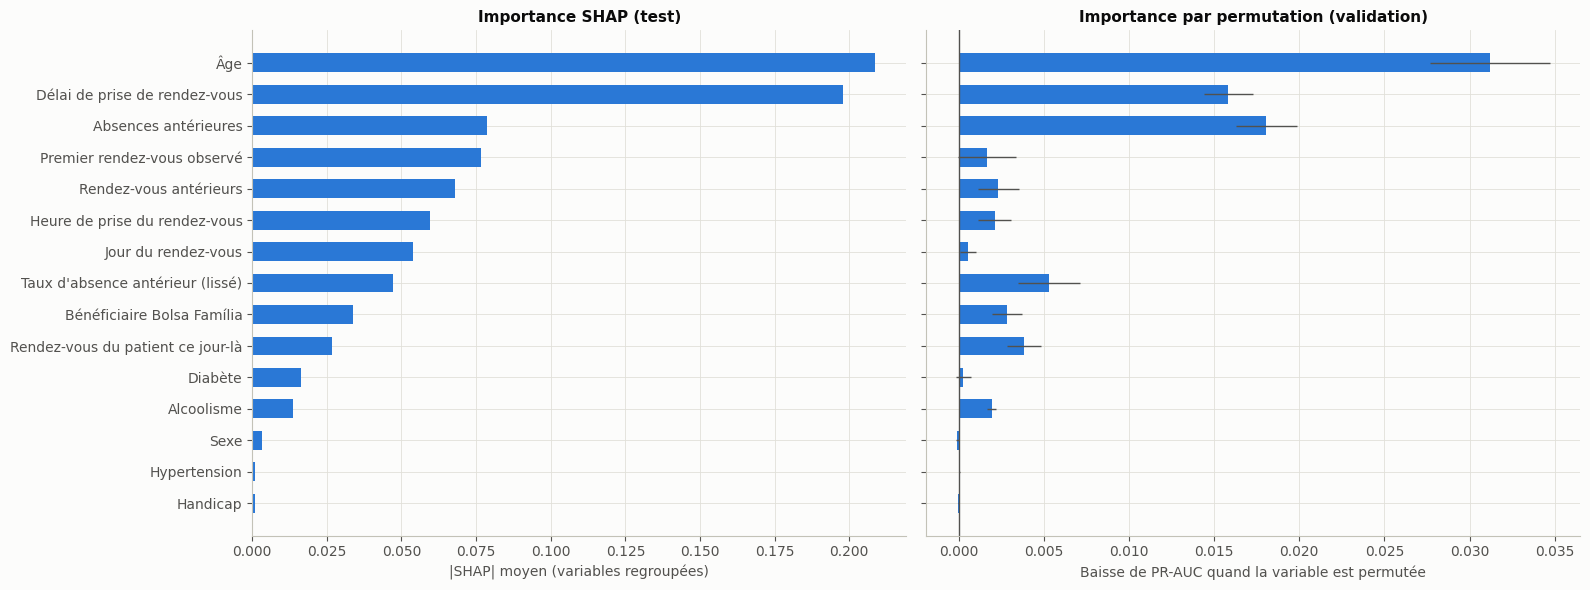

In [44]:
imp_shap = contrib_groupes.abs().mean().rename(index=lambda v: VARIABLES[v][0]).sort_values()
perm = permutation_importance(modele_final, X_val, y_val, scoring='average_precision', n_repeats=5,
                              random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=[VARIABLES[c][0] for c in X_val.columns]).reindex(imp_shap.index)
err_perm = pd.Series(perm.importances_std, index=[VARIABLES[c][0] for c in X_val.columns]).reindex(imp_shap.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(imp_shap.index, imp_shap.values, color=COULEUR[NOM_FINAL], height=0.6)
axes[0].set(xlabel='|SHAP| moyen (variables regroupées)', title='Importance SHAP (test)')
axes[1].barh(imp_perm.index, imp_perm.values, xerr=err_perm.values, color=COULEUR[NOM_FINAL], height=0.6,
             error_kw=dict(ecolor=INK2, lw=1))
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel='Baisse de PR-AUC quand la variable est permutée', title='Importance par permutation (validation)')
fig.tight_layout()
savefig(fig, '22_importances')
plt.show()

### 11.1 Carte rendez-vous : l'affichage prévu dans VIHEPAT
Pour chaque rendez-vous du lendemain, l'équipe voit le niveau de risque, l'action proposée et les **3 facteurs qui augmentent le plus le risque**.

In [45]:
ACTIONS = {'élevé': 'appel de confirmation', 'modéré': 'rappel renforcé (J−3 et J−1)', 'faible': 'rappel standard (J−1)'}


def valeur_affichee(var, ligne):
    lab, unite = VARIABLES[var]
    v = ligne[var]
    if var in VARS_BIN:
        return f"{lab} : {'oui' if v == 1 else 'non'}"
    if var == 'sexe':
        return f'{lab} : {TRAD[v]}'
    if var == 'jour_semaine':
        return f'{lab} : {v}'
    if var == 'heure_prise':
        return f'{lab} : {int(v)} h {int(round(60 * (v % 1))):02d}'
    if var == 'taux_absence_anterieur':
        return f'{lab} : {v:.0%}'
    return f'{lab} : {v:.0f} {unite}'.rstrip()


def carte_rdv(pos, contributions=contrib_groupes, probas=p_final_test, X_ref=X_test):
    ligne = df_model.loc[X_ref.index[pos]]
    c = contributions.iloc[pos].sort_values()
    niveau = niveau_risque(probas[pos])
    sortie = [f"Rendez-vous du {ligne['date_rdv']:%d/%m/%Y} (patient …{ligne['id_patient'][-4:]}) : risque d'absence "
              f"{probas[pos]:.0%}, niveau {niveau} → {ACTIONS[niveau]}", '  Facteurs qui augmentent le risque :']
    sortie += [f'    ↑ {valeur_affichee(v, ligne)}   (+{x:.2f})' for v, x in c[c >= 0.01][::-1].head(3).items()]
    sortie.append('  Facteurs qui diminuent le risque :')
    sortie += [f'    ↓ {valeur_affichee(v, ligne)}   ({x:.2f})' for v, x in c[c <= -0.01].head(2).items()]
    sortie.append(f"  Issue réelle : {'ABSENT' if ligne['absent'] else 'présent'}")
    print('\n'.join(sortie) + '\n')


for pos in np.argsort(-p_final_test)[[0, len(p_final_test) // 2]]:
    carte_rdv(pos)

Rendez-vous du 06/06/2016 (patient …5941) : risque d'absence 65%, niveau élevé → appel de confirmation
  Facteurs qui augmentent le risque :
    ↑ Absences antérieures : 10   (+0.75)
    ↑ Taux d'absence antérieur (lissé) : 85%   (+0.27)
    ↑ Délai de prise de rendez-vous : 42 jours   (+0.22)
  Facteurs qui diminuent le risque :
    ↓ Rendez-vous antérieurs : 11   (-0.23)
    ↓ Rendez-vous du patient ce jour-là : 1   (-0.02)
  Issue réelle : ABSENT

Rendez-vous du 06/06/2016 (patient …4128) : risque d'absence 30%, niveau faible → rappel standard (J−1)
  Facteurs qui augmentent le risque :
    ↑ Âge : 9 ans   (+0.19)
    ↑ Jour du rendez-vous : lundi   (+0.10)
    ↑ Premier rendez-vous observé : non   (+0.10)
  Facteurs qui diminuent le risque :
    ↓ Rendez-vous antérieurs : 3   (-0.12)
    ↓ Délai de prise de rendez-vous : 7 jours   (-0.09)
  Issue réelle : ABSENT



**Interprétation.**
* **Âge** : le risque culmine à **21 ans** (odds ratio 1,34 par rapport à 45 ans) et atteint son minimum à **74 ans** (0,70). Ce groupe mérite une attention particulière dans VIHEPAT : la rétention des adolescents et jeunes adultes est aussi un enjeu connu des programmes VIH.
* **Délai** : le risque augmente fortement durant les **4 premières semaines** (odds ratio 1,66 à 29 jours par rapport à 1 jour), puis décroît légèrement (1,42 à 120 jours). Pour VIHEPAT, c'est une recommandation directe : **raccourcir les délais** ou multiplier les rappels pour les rendez-vous lointains.
* **Autres facteurs** (à âge et délai égaux) : alcoolisme (OR 1,28), Bolsa Família (1,22) et absences antérieures (1,08 par écart-type) augmentent le risque. Le **diabète** devient un facteur de risque (1,13) alors qu'il semblait protecteur en analyse brute (section 6.4) : l'effet brut était dû à l'âge. L'**hypertension** n'a plus d'effet propre. Le **lundi** est le jour le plus à risque (1,10).
* « Premier rendez-vous observé » (OR 0,87) doit se lire **conjointement** avec les rendez-vous antérieurs, auxquels il est très corrélé (ρ = −0,96). Pris isolément, ces deux coefficients ne s'interprètent pas.
* **SHAP et permutation** concordent sur le trio de tête : **âge, délai, absences antérieures**. Le sexe, l'hypertension et le handicap n'apportent rien (importance par permutation ≈ 0).
* **Carte rendez-vous** : chaque facteur est exprimé en langage clair, avec sa contribution (en log-odds, par rapport au rendez-vous moyen). Le soignant sait ainsi *pourquoi* appeler, par exemple « 10 absences antérieures ». Il peut adapter son discours : rappeler l'importance du suivi, ou proposer un autre créneau quand le délai est long.

## 12. Analyse des erreurs : exemples de succès et d'échecs
### 12.1 Où le modèle discrimine-t-il bien ou mal ?

rendez-vous  % d'absents  risque moyen prédit (%)  ROC-AUC  % signalés  sensibilité   VPP
dimension  groupe                                                                                                    
Délai      1-2 j                   2499       22.089                   22.938    0.555       1.401        0.020 0.314
           3-7 j                   3878       22.357                   27.042    0.597       6.008        0.104 0.386
           8-30 j                  5897       28.184                   34.099    0.594      25.928        0.335 0.364
           > 30 j                  2134       32.146                   34.847    0.594      28.585        0.362 0.407
Historique aucun                   5576       24.785                   28.643    0.580       8.537        0.122 0.353
           avec absence(s)         3093       31.005                   37.168    0.606      45.231        0.562 0.385
           sans absence            5739       24.848                   28.395    0.605       9.270        0.139 0.372

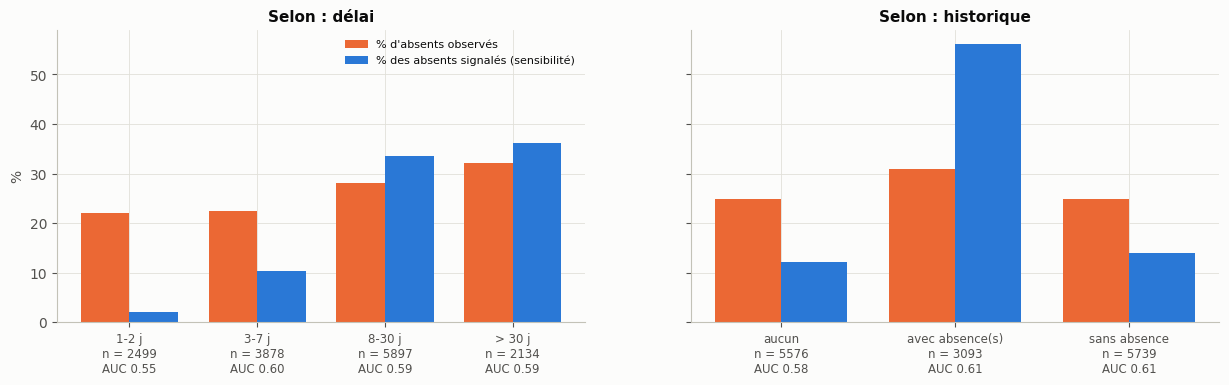

In [46]:
analyse = df_model.loc[idx_test].copy()
analyse['p'] = p_final_test
analyse['signalé'] = (analyse['p'] >= SEUIL_ELEVE).astype(int)
analyse['type'] = np.select([(analyse.signalé == 1) & (analyse.absent == 1), (analyse.signalé == 0) & (analyse.absent == 0),
                             (analyse.signalé == 1) & (analyse.absent == 0), (analyse.signalé == 0) & (analyse.absent == 1)],
                            ['Vrai positif', 'Vrai négatif', 'Faux positif', 'Faux négatif'], default='')
sous_groupes = {
    'Délai': pd.cut(analyse['delai_jours'], [0, 2, 7, 30, 200], labels=['1-2 j', '3-7 j', '8-30 j', '> 30 j']),
    'Historique': np.select([analyse.premier_rdv == 1, analyse.nb_absences_anterieures == 0],
                            ['aucun', 'sans absence'], default='avec absence(s)'),
}
lignes = []
for dimension, g in sous_groupes.items():
    for modalite, sous in analyse.groupby(g, observed=True):
        m = metriques(sous.absent, sous.p, SEUIL_ELEVE)
        lignes.append({'dimension': dimension, 'groupe': modalite, 'rendez-vous': len(sous), "% d'absents": 100 * sous.absent.mean(),
                       'risque moyen prédit (%)': 100 * sous.p.mean(), 'ROC-AUC': m['ROC-AUC'],
                       '% signalés': 100 * m['% signalés'], 'sensibilité': m['Sensibilité'], 'VPP': m['VPP']})
par_sous_groupe = pd.DataFrame(lignes).set_index(['dimension', 'groupe'])
display(par_sous_groupe)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, dimension in zip(axes, sous_groupes):
    t = par_sous_groupe.loc[dimension]
    pos, h = np.arange(len(t)), 0.38
    ax.bar(pos - h / 2, t["% d'absents"], width=h, color=C_ABS, label="% d'absents observés")
    ax.bar(pos + h / 2, 100 * t['sensibilité'], width=h, color=SERIES[0], label='% des absents signalés (sensibilité)')
    ax.set_xticks(pos, [f'{i}\nn = {n}\nAUC {a:.2f}' for i, n, a in zip(t.index, t['rendez-vous'], t['ROC-AUC'])], fontsize=8.5)
    ax.set_title(f'Selon : {dimension.lower()}')
axes[0].set_ylabel('%')
axes[0].legend(fontsize=8)
savefig(fig, '23_erreurs_sous_groupes')
plt.show()

In [47]:
# Profil des erreurs : en quoi les faux négatifs ressemblent-ils aux présents, et les faux positifs aux absents ?
profil = analyse.groupby('type').agg(
    rendez_vous=('p', 'size'), risque_moyen=('p', 'mean'), delai_median=('delai_jours', 'median'),
    age_median=('age', 'median'), pct_premier_rdv=('premier_rdv', lambda s: 100 * s.mean()),
    absences_anterieures_moy=('nb_absences_anterieures', 'mean'), pct_bolsa=('bolsa_familia', lambda s: 100 * s.mean()),
    pct_hypertension=('hypertension', lambda s: 100 * s.mean()))
profil.reindex(['Vrai positif', 'Faux négatif', 'Vrai négatif', 'Faux positif'])

,rendez_vous,risque_moyen,delai_median,age_median,pct_premier_rdv,absences_anterieures_moy,pct_bolsa,pct_hypertension
type,,,,,,,,
Vrai positif,905,0.439,21.000,23.000,18.564,1.006,25.525,6.740
Faux négatif,2862,0.290,9.000,39.000,42.418,0.203,5.381,19.672
Vrai négatif,9139,0.273,7.000,47.000,42.521,0.187,6.303,25.222
Faux positif,1502,0.432,21.000,23.000,20.506,0.878,21.105,6.591


### 12.2 Exemples concrets
Quatre rendez-vous du jeu de test : le succès le plus net dans chaque classe, et l'erreur la plus grossière dans chaque sens.

In [48]:
exemples = {
    'SUCCÈS : vrai positif le plus confiant': analyse.index.get_indexer([analyse[analyse.type == 'Vrai positif']['p'].idxmax()])[0],
    'SUCCÈS : vrai négatif le plus confiant': analyse.index.get_indexer([analyse[analyse.type == 'Vrai négatif']['p'].idxmin()])[0],
    'ÉCHEC : faux négatif le plus grossier': analyse.index.get_indexer([analyse[analyse.type == 'Faux négatif']['p'].idxmin()])[0],
    'ÉCHEC : faux positif le plus grossier': analyse.index.get_indexer([analyse[analyse.type == 'Faux positif']['p'].idxmax()])[0],
}
for titre, pos in exemples.items():
    print(f'=== {titre} ===')
    carte_rdv(pos)

=== SUCCÈS : vrai positif le plus confiant ===
Rendez-vous du 06/06/2016 (patient …5941) : risque d'absence 65%, niveau élevé → appel de confirmation
  Facteurs qui augmentent le risque :
    ↑ Absences antérieures : 10   (+0.75)
    ↑ Taux d'absence antérieur (lissé) : 85%   (+0.27)
    ↑ Délai de prise de rendez-vous : 42 jours   (+0.22)
  Facteurs qui diminuent le risque :
    ↓ Rendez-vous antérieurs : 11   (-0.23)
    ↓ Rendez-vous du patient ce jour-là : 1   (-0.02)
  Issue réelle : ABSENT

=== SUCCÈS : vrai négatif le plus confiant ===
Rendez-vous du 02/06/2016 (patient …4569) : risque d'absence 12%, niveau faible → rappel standard (J−1)
  Facteurs qui augmentent le risque :
    ↑ Premier rendez-vous observé : non   (+0.10)
  Facteurs qui diminuent le risque :
    ↓ Âge : 78 ans   (-0.38)
    ↓ Délai de prise de rendez-vous : 2 jours   (-0.28)
  Issue réelle : présent

=== ÉCHEC : faux négatif le plus grossier ===
Rendez-vous du 02/06/2016 (patient …7274) : risque d'absence 13%,

**Interprétation des erreurs.**
* **Rendez-vous à 1-2 jours** : le modèle ne les signale presque jamais (1,4 %), alors que 22 % sont manqués, et il les discrimine mal (AUC 0,55). Le délai étant court, aucun facteur de risque ne ressort. En pratique, ces rendez-vous reçoivent le rappel standard, qui reste pertinent pour eux.
* **Historique** : le modèle est le plus utile pour les patients **ayant déjà manqué un rendez-vous**. 45 % d'entre eux sont signalés, et 56 % de leurs absences sont détectées. Sans historique, la sensibilité tombe à 12 %. Plus VIHEPAT accumulera d'historique, meilleur sera le ciblage.
* **Profil des erreurs** : les **faux négatifs** ressemblent trait pour trait aux vrais négatifs (âge médian 39 contre 47 ans, délai médian 9 contre 7 jours, 0,2 absence antérieure en moyenne). Les **faux positifs** ressemblent aux vrais positifs (23 ans, délai de 21 jours, près d'une absence antérieure). Ces erreurs ne sont pas un défaut de réglage : avec ces variables, ces patients sont **indiscernables**. Ce qui les distingue (maladie, imprévu, transport, travail) n'est pas dans les données.
* **Exemples concrets** :
  * *Succès* : le vrai positif le plus net cumule 10 absences antérieures, un taux lissé de 85 % et un délai de 42 jours. Le risque prédit est de 65 %, et le patient est effectivement absent.
  * *Échec* : le faux négatif le plus grossier (59 ans, rendez-vous pris 2 jours avant, risque de 13 %) a exactement le profil du vrai négatif le plus net (78 ans, 2 jours, 12 %). Rien dans les données ne laissait prévoir son absence.
  * *Échec* : le faux positif le plus grossier (6 absences antérieures, bénéficiaire de la Bolsa Família, risque de 59 %) est venu. Un historique chargé n'est pas une fatalité, d'où l'importance de **ne jamais stigmatiser** un patient sur la base du score.

## 13. Équité et biais
Le modèle fonctionne-t-il aussi bien pour tous les groupes ? Deux indicateurs comptent ici :
* **l'égalité des chances** : un futur absent doit avoir la même probabilité d'être signalé, quel que soit son groupe ;
* **la calibration par groupe** : le risque affiché doit correspondre au taux d'absence réel du groupe.

**Point d'attention éthique.** Être signalé déclenche ici une action **bienveillante** (un appel, un rappel de plus). Signaler davantage un groupe à risque n'est donc pas pénalisant, à condition que le score ne serve jamais à refuser ou à surréserver un rendez-vous.

rendez-vous  % d'absents  risque moyen prédit (%)  ROC-AUC  sensibilité  taux de faux positifs   VPP  % signalés
dimension     groupe                                                                                                                            
Sexe          femme                    9643       25.780                   30.332    0.605        0.254                  0.143 0.381      17.152
              homme                    4765       26.884                   30.461    0.594        0.214                  0.137 0.364      15.803
Tranche d'âge 0-17 ans                 3249       29.486                   34.632    0.564        0.301                  0.235 0.349      25.423
              18-39 ans                3960       32.146                   35.583    0.572        0.382                  0.277 0.395      31.086
              40-59 ans                4096       23.950                   27.764    0.567        0.120                  0.063 0.375       7.690
              60 ans et +              3103       17.886                   22.716    0.545        0.023                  0.009 0.371       1.128
Bolsa Família bénéficiaire             1278       30.125                   36.857    0.651        0.600                  0.355 0.422      42.879
              non bénéficiaire        13130       25.758                   29.744    0.596        0.199                  0.122 0.363      14.158
Handicap      avec handicap             259       22.008                   27.919    0.644        0.211                  0.064 0.480       9.653
              sans handicap           14149       26.221                   30.419    0.601        0.241                  0.143 0.375      16.835

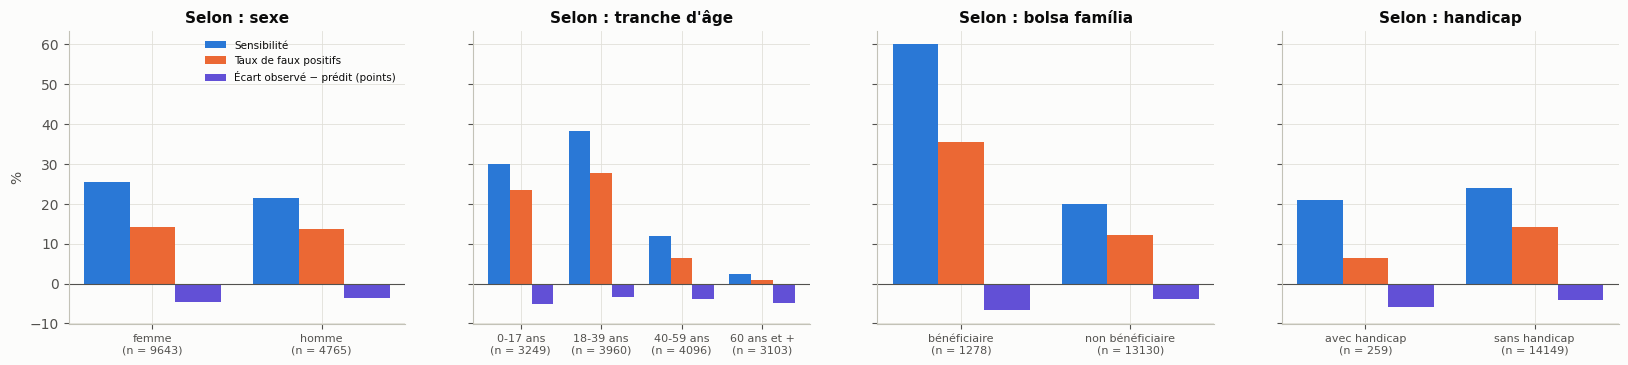

In [49]:
groupes_equite = {
    'Sexe': analyse['sexe'].map(TRAD),
    "Tranche d'âge": pd.cut(analyse['age'], [-1, 17, 39, 59, 120], labels=['0-17 ans', '18-39 ans', '40-59 ans', '60 ans et +']),
    'Bolsa Família': analyse['bolsa_familia'].map({0: 'non bénéficiaire', 1: 'bénéficiaire'}),
    'Handicap': analyse['handicap'].map({0: 'sans handicap', 1: 'avec handicap'})}
lignes = []
for dimension, g in groupes_equite.items():
    for modalite, sous in analyse.groupby(g, observed=True):
        if len(sous) < 30 or sous.absent.nunique() < 2:
            continue
        m = metriques(sous.absent, sous.p, SEUIL_ELEVE)
        lignes.append({'dimension': dimension, 'groupe': modalite, 'rendez-vous': len(sous), "% d'absents": 100 * sous.absent.mean(),
                       'risque moyen prédit (%)': 100 * sous.p.mean(), 'ROC-AUC': m['ROC-AUC'], 'sensibilité': m['Sensibilité'],
                       'taux de faux positifs': 1 - m['Spécificité'], 'VPP': m['VPP'], '% signalés': 100 * m['% signalés']})
equite = pd.DataFrame(lignes).set_index(['dimension', 'groupe'])
display(equite)

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, dimension in zip(axes, groupes_equite):
    t = equite.loc[dimension]
    pos, h = np.arange(len(t)), 0.27
    ax.bar(pos - h, 100 * t['sensibilité'], width=h, color=SERIES[0], label='Sensibilité')
    ax.bar(pos, 100 * t['taux de faux positifs'], width=h, color=SERIES[1], label='Taux de faux positifs')
    ax.bar(pos + h, t["% d'absents"] - t['risque moyen prédit (%)'], width=h, color=SERIES[6], label='Écart observé − prédit (points)')
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(pos, [f'{i}\n(n = {n})' for i, n in zip(t.index, t['rendez-vous'])], fontsize=8)
    ax.set_title(f'Selon : {dimension.lower()}')
axes[0].set_ylabel('%')
axes[0].legend(fontsize=7.5)
savefig(fig, '24_equite')
plt.show()

**Interprétation.**
* **Sexe** : aucun écart notable (sensibilité de 25 % chez les femmes et 21 % chez les hommes ; taux de faux positifs de 14 % dans les deux groupes).
* **Âge** : c'est le déséquilibre principal. Les 18-39 ans sont signalés dans 31 % des cas, les 60 ans et plus dans **1 %** seulement, alors que 18 % d'entre eux manquent leur rendez-vous (sensibilité de 2 %). Le modèle reproduit l'écart réel de risque entre âges. Mais **à l'intérieur de chaque tranche d'âge**, sa discrimination est faible (AUC de 0,55 à 0,57) : une grande partie de sa performance consiste à distinguer les jeunes des âgés.
* **Précarité** : les bénéficiaires de la Bolsa Família sont signalés dans 43 % des cas, contre 14 %. C'est cohérent avec leur risque observé (30 % contre 26 %), mais l'écart de signalement est bien plus grand que l'écart de risque.
* **Calibration par groupe** : le risque est surestimé de 3 à 7 points dans **tous** les groupes. C'est l'effet de la dérive globale, pas un biais visant un groupe particulier.

**Lecture éthique.** Être signalé déclenche une action **de soutien** : un appel bienveillant, un rappel supplémentaire. Orienter davantage d'appels vers les jeunes et les plus précaires revient à diriger l'aide là où les obstacles sont les plus fréquents. C'est acceptable à **trois conditions** :
1. le score ne sert **jamais** à refuser, retarder ou surréserver un rendez-vous ;
2. l'appel est formulé comme une **aide** (« avez-vous besoin d'un autre créneau ? »), jamais comme un contrôle ;
3. les patients âgés, rarement signalés, continuent de recevoir le rappel standard.

L'équité devra être **suivie en continu** dans VIHEPAT, sur données béninoises.

## 14. Analyses de sensibilité
Chaque variante ré-entraîne **le même type de modèle avec les mêmes hyperparamètres** sur la période d'entraînement et l'évalue sur la période de validation. Le jeu de test reste intact.

| Variante | Question |
|---|---|
| **S1. Fuite volontaire** : taux d'absence du patient calculé sur **tous** ses rendez-vous | Que se passe-t-il si l'on commet l'erreur la plus fréquente des notebooks publiés sur ce jeu ? |
| **S2. Découpage aléatoire** (ni temporel, ni par patient) | Le découpage temporel est-il plus exigeant ? |
| **S3. + SMS reçu** | Que gagnerait-on en utilisant la variable écartée pour circularité ? |
| **S4. + quartier** | Que perd-on en écartant la variable non transposable au Bénin ? |
| **S5. Sans historique** (démarrage à froid) | Que vaut le modèle pour un centre qui démarre, sans historique de présence ? |
| **S6. Rendez-vous du jour même inclus** | Pourquoi ne pas avoir modélisé tous les rendez-vous ? |

In [50]:
def evaluer_variante(nom_modele, idx_tr, idx_ev, donnees=None, idx_score=None, **kw_prep):
    """idx_score : sous-ensemble de idx_ev sur lequel calculer les métriques (par défaut idx_ev)."""
    donnees = df_model if donnees is None else donnees
    prep = construire_preprocesseur(**kw_prep)
    colonnes = [c for _, _, cols in prep.transformers for c in cols]
    modele = Pipeline([('prep', prep), ('clf', clone(modeles[nom_modele].named_steps['clf']))])
    if nom_modele == 'MLP':
        modele.set_params(clf__max_iter=mlp_retenu['epoch'], clf__warm_start=False)
    modele.fit(donnees.loc[idx_tr, colonnes], donnees.loc[idx_tr, 'absent'])
    idx_score = idx_ev if idx_score is None else idx_score
    p = modele.predict_proba(donnees.loc[idx_score, colonnes])[:, 1]
    cible = donnees.loc[idx_score, 'absent']
    return {'ROC-AUC': roc_auc_score(cible, p), 'PR-AUC': average_precision_score(cible, p), 'prévalence': cible.mean(),
            'PR-AUC / prévalence': average_precision_score(cible, p) / cible.mean()}


# S2 : découpage aléatoire des rendez-vous, mêmes effectifs que le découpage temporel
rng_s2 = np.random.default_rng(SEED)
melange = rng_s2.permutation(df_model.index.to_numpy())
idx_tr_alea, idx_ev_alea = melange[:len(idx_train)], melange[len(idx_train):len(idx_train) + len(idx_val)]
# S6 : tous les rendez-vous (y compris le jour même) des mêmes périodes
idx_tr_tous = df.index[df['date_rdv'] <= FIN_ENTRAINEMENT]
idx_ev_tous = df.index[(df['date_rdv'] > FIN_ENTRAINEMENT) & (df['date_rdv'] <= FIN_VALIDATION)]
idx_ev_tous_avance = idx_ev_tous[df.loc[idx_ev_tous, 'delai_jours'] >= 1]
sans_hist = dict(vars_compte=['nb_rdv_jour'], vars_num=['heure_prise'], vars_bin=[v for v in VARS_BIN if v != 'premier_rdv'])

variantes = {}
for nom in dict.fromkeys([NOM_FINAL, 'Régression logistique', 'XGBoost']):
    variantes[(nom, 'Modèle de référence')] = evaluer_variante(nom, idx_train, idx_val)
    variantes[(nom, 'S1. Fuite : taux d\'absence global du patient')] = evaluer_variante(nom, idx_train, idx_val, vars_num=VARS_NUM + ['FUITE_taux_absence_global'])
    variantes[(nom, 'S2. Découpage aléatoire')] = evaluer_variante(nom, idx_tr_alea, idx_ev_alea)
    variantes[(nom, 'S3. + SMS reçu')] = evaluer_variante(nom, idx_train, idx_val, vars_bin=VARS_BIN + ['sms_recu'])
    variantes[(nom, 'S4. + quartier')] = evaluer_variante(nom, idx_train, idx_val, vars_cat_rares=['quartier'])
    variantes[(nom, 'S5. Sans historique')] = evaluer_variante(nom, idx_train, idx_val, **sans_hist)
    variantes[(nom, 'S6a. Jour même inclus : évalué sur tous')] = evaluer_variante(nom, idx_tr_tous, idx_ev_tous, donnees=df, vars_bin=VARS_BIN + ['meme_jour'])
    variantes[(nom, 'S6b. Jour même inclus : évalué sur les pris à l\'avance')] = evaluer_variante(
        nom, idx_tr_tous, idx_ev_tous, donnees=df, idx_score=idx_ev_tous_avance, vars_bin=VARS_BIN + ['meme_jour'])
sensibilite = pd.DataFrame(variantes).T
sensibilite.index.names = ['modèle', 'variante']
sensibilite

ROC-AUC  PR-AUC  prévalence  PR-AUC / prévalence
modèle                variante                                                                                            
Régression logistique Modèle de référence                                   0.608   0.363       0.274                1.323
                      S1. Fuite : taux d'absence global du patient          0.990   0.973       0.274                3.547
                      S2. Découpage aléatoire                               0.604   0.368       0.284                1.298
                      S3. + SMS reçu                                        0.611   0.366       0.274                1.336
                      S4. + quartier                                        0.607   0.360       0.274                1.314
                      S5. Sans historique                                   0.596   0.346       0.274                1.263
                      S6a. Jour même inclus : évalué sur tous               0.736   0.356       0.191                1.866
                      S6b. Jour même inclus : évalué sur les pris à l...    0.607   0.365       0.274                1.331
XGBoost               Modèle de référence                                   0.605   0.354       0.274                1.292
                      S1. Fuite : taux d'absence global du patient          0.990   0.974       0.274                3.552
                      S2. Découpage aléatoire                               0.616   0.382       0.284                1.345
                      S3. + SMS reçu                                        0.606   0.356       0.274                1.298
                      S4. + quartier                                        0.607   0.356       0.274                1.299
                      S5. Sans historique                                   0.595   0.339       0.274                1.235
                      S6a. Jour même inclus : évalué sur tous               0.741   0.354       0.191                1.858
                      S6b. Jour même inclus : évalué sur les pris à l...    0.608   0.357       0.274                1.301

**Interprétation.**
* **S1, fuite volontaire** : avec le taux d'absence calculé sur tous les rendez-vous du patient, l'AUC bondit à **0,990**. Le modèle « lit » l'issue du rendez-vous dans la variable. C'est l'erreur la plus fréquente des notebooks publiés sur ce jeu. Notre historique strictement antérieur l'évite.
* **S2, découpage aléatoire** : la régression logistique reste stable (0,604). XGBoost, en revanche, **gagne 0,011** (0,616) et deviendrait le meilleur modèle. Le découpage aléatoire place des rendez-vous d'une même session et d'une même semaine des deux côtés, ce dont un modèle flexible profite. Un découpage aléatoire aurait donc conduit à **un mauvais choix de modèle**.
* **S3, + SMS reçu** : gain négligeable (+0,003 d'AUC). Écarter cette variable pour des raisons de conception ne coûte rien.
* **S4, + quartier** : aucun gain (−0,001). Le signal géographique est déjà porté par la précarité, comme le montrait la corrélation de 0,40 en 6.7. Le modèle est donc **transposable sans perte**.
* **S5, sans historique** : l'AUC baisse de 0,012 (0,596). L'historique aide, même tronqué à 6 semaines. Un centre qui démarre sans historique dispose d'une version à peine moins bonne.
* **S6, rendez-vous du jour même inclus** : l'AUC monte à **0,736**, ce qui semble bien meilleur. Mais **le même modèle**, évalué sur les rendez-vous pris à l'avance, retombe à **0,607**. Tout le gain vient de la séparation triviale des rendez-vous du jour même, qui n'ont besoin d'aucune prédiction. Cela explique les AUC de 0,73-0,75 souvent rapportées sur ce jeu.

➡️ Nos choix de conception ont un **coût nul en performance utile**, et chacun évite une conclusion trompeuse.

## 15. Limites
**Données**
1. **Signal faible.** Avec les variables disponibles, l'AUC plafonne à 0,60 quel que soit l'algorithme. Les courbes d'apprentissage montrent que la limite vient du contenu des variables, pas de leur volume. Les déterminants majeurs de l'absence manquent : distance et coût du transport, contraintes professionnelles, motif de la consultation, état de santé du jour, confirmation du rappel.
2. **Contexte éloigné du Bénin.** Consultations générales du système public brésilien (Vitória, 2016), et non suivi VIH ou hépatite. La Bolsa Família n'a pas d'équivalent direct au Bénin, et les quartiers ne se transposent pas. **Ce modèle valide une méthode ; il n'est pas déployable tel quel.**
3. **Fenêtre de 6 semaines.** L'historique est tronqué (58,6 % des rendez-vous sans historique observé), ce qui sous-estime probablement la valeur de l'assiduité passée. Dans VIHEPAT, le suivi sur plusieurs années donnera un historique bien plus riche.
4. **Variables imprécises.** Il n'y a pas d'heure de rendez-vous, ni de distinction entre annulation et absence ; le handicap et les conditions de santé sont déclaratifs.

**Modèle**

5. **Dérive et calibration.** Le taux d'absence passe de 29,6 % à 26,1 % en 6 semaines. Le risque affiché est surestimé de 4 points au test et devra être recalibré régulièrement.
6. **Discrimination faible au sein des groupes d'âge** (AUC de 0,55 à 0,57). Le score distingue surtout des profils : il ne « devine » pas l'imprévu individuel.
7. **Effet des rappels inconnu.** Le SMS étant confondu avec le délai, ces données ne permettent pas de mesurer l'effet causal d'une relance. Le modèle prédit le risque, pas le bénéfice d'une action.
8. **Boucle de rétroaction.** Une fois déployé, le modèle déclenchera des appels qui réduiront les absences des patients signalés. Les futures données d'entraînement en seront biaisées (*prédiction performative*) : il faudra enregistrer chaque action pour pouvoir corriger ce biais.

**Cadre**

9. **Licence non commerciale** (CC BY-NC-SA 4.0). Le modèle entraîné sur ces données est réservé à la démonstration ; le modèle de production devra être appris sur des données béninoises.

## 16. Pistes d'amélioration
| Priorité | Piste | Effet attendu |
|---|---|---|
| 1 | **Collecter dans VIHEPAT les déterminants manquants** : réponse au rappel (« répondez 1 pour confirmer »), distance ou temps de trajet, mode de prise du rendez-vous, motif (renouvellement d'ARV, charge virale), langue préférée, joignabilité | Gain de discrimination attendu bien supérieur à tout changement d'algorithme : les courbes d'apprentissage montrent que le modèle manque d'information, pas de données |
| 2 | **Ré-entraîner et recalibrer sur données béninoises**, puis recalibrer chaque mois sur les données récentes | Probabilités fidèles malgré la dérive ; adaptation au contexte local |
| 3 | **Évaluer l'effet des rappels** par une attribution aléatoire du type de rappel (avec accord éthique), puis passer à un modèle d'*uplift* | Cibler les patients pour qui l'appel **change** l'issue, et pas seulement ceux qui sont à risque |
| 4 | **Relier les deux modèles** : chaque rendez-vous manqué alimente l'historique utilisé par le modèle 1 (perte de suivi) | Détection plus précoce du décrochage : un rendez-vous manqué est souvent le premier signe d'une perte de suivi |
| 5 | Modèles à **effet patient** (modèles mixtes, historique long) | Mieux capter l'assiduité propre à chaque patient |
| 6 | **Suivi de l'équité** par âge, sexe et précarité, avec alerte en cas d'écart | Éviter que le ciblage n'oublie durablement un groupe |
| 7 | Ré-entraîner le modèle final sur entraînement + validation avant déploiement | Profiter des données les plus récentes |

## 17. Export du modèle et journal des expérimentations
Le pipeline complet (prétraitement et modèle) est sauvegardé avec ses métadonnées : variables attendues, seuils, performances et version des données. C'est ce fichier que le back-end de VIHEPAT chargera pour la démonstration.

In [51]:
CHEMIN_MODELE = MODEL_DIR / 'rdv_manque_modele_final.joblib'
joblib.dump(modele_final, CHEMIN_MODELE)
assert np.allclose(joblib.load(CHEMIN_MODELE).predict_proba(X_test)[:, 1], p_final_test)   # rechargement vérifié

metadonnees = {
    'modele': NOM_FINAL, 'version': '1.0.0', 'date': date.today().isoformat(),
    'usage': "Aide à l'organisation des rappels ; ne doit jamais servir à refuser ou surréserver un rendez-vous.",
    'cible': 'Absence au rendez-vous (No-show = Yes), rendez-vous pris au moins la veille',
    'moment_prediction': 'Veille du rendez-vous (J-1)',
    'donnees': {'source': 'Kaggle, Medical Appointment No Shows (joniarroba/noshowappointments, v5), CC BY-NC-SA 4.0',
                'sha256_csv': SHA256_ATTENDU, 'rendez_vous_modelises': len(df_model), 'absents': int(df_model['absent'].sum()),
                'decoupage': {'entrainement': '2016-04-29 -> 2016-05-20', 'validation': '2016-05-24 -> 2016-06-01',
                              'test': '2016-06-02 -> 2016-06-08'}},
    'licence_modele': "Dérivé de données CC BY-NC-SA 4.0 : démonstration non commerciale uniquement",
    'variables_entree': FEATURES,
    'pretraitement_requis': ("nettoyer() puis creer_variables() (sections 4.4 et 5) sur l'ensemble des rendez-vous "
                             "connus du patient, pour reconstruire l'historique"),
    'hyperparametres': {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                        for k, v in modele_final.named_steps['clf'].get_params().items()
                        if k in {'C', 'n_estimators', 'max_depth', 'learning_rate', 'min_child_weight', 'subsample',
                                 'colsample_bytree', 'reg_lambda', 'gamma', 'min_samples_leaf', 'max_features', 'alpha'}},
    'seuils': {'eleve_appel_top20': SEUIL_ELEVE, 'modere_rappel_renforce_top50': SEUIL_MODERE},
    'performances_test': {k: {'valeur': float(v), 'ic95': [float(resultats_test.loc[k, 'IC95 bas']), float(resultats_test.loc[k, 'IC95 haut'])]}
                          for k, v in resultats_test['valeur'].items()},
    'environnement': versions,
}
(MODEL_DIR / 'rdv_manque_modele_final.json').write_text(json.dumps(metadonnees, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Modèle : {CHEMIN_MODELE.relative_to(ROOT)}\nMétadonnées : models/rdv_manque_modele_final.json')

Modèle : models\rdv_manque_modele_final.joblib
Métadonnées : models/rdv_manque_modele_final.json


In [52]:
def f3(v):
    return f'{v:.3f}'


ref = (NOM_FINAL, 'Modèle de référence')
journal = pd.DataFrame([
    ('E01', 'Population : rendez-vous pris au moins la veille', f"{len(df_model)} rendez-vous, {df_model['absent'].mean():.1%} d'absents (jour même : {df.loc[df.delai_jours == 0, 'absent'].mean():.1%})", 'Retenue'),
    ('E02', 'Historique strictement antérieur (anti-fuite)', f"{df_model['premier_rdv'].mean():.1%} des rendez-vous sans historique observé", 'Retenu'),
    ('E03', 'Référence naïve', f"PR-AUC val = {f3(tab_val.loc['Référence naïve', 'PR-AUC'])}", 'Plancher'),
    ('E04', f'Régression logistique + splines (C = {C_OPT:.3g})', f"PR-AUC val = {f3(tab_val.loc['Régression logistique', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['Régression logistique', 'ROC-AUC'])}", 'Référence interprétable'),
    ('E05', 'Random Forest (15 combinaisons, CV groupée)', f"PR-AUC val = {f3(tab_val.loc['Random Forest', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['Random Forest', 'ROC-AUC'])}", 'Comparé'),
    ('E06', 'XGBoost (30 combinaisons, CV groupée)', f"PR-AUC val = {f3(tab_val.loc['XGBoost', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['XGBoost', 'ROC-AUC'])}", 'Comparé'),
    ('E07', f'MLP 32-16 (alpha = {ALPHA_OPT}, arrêt epoch {mlp_retenu["epoch"]})', f"PR-AUC val = {f3(tab_val.loc['MLP', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['MLP', 'ROC-AUC'])}", 'Comparé'),
    ('E08', 'Sélection (règle 7.1)', f'{NOM_FINAL} : {raison}', 'Modèle final'),
    ('E09', 'Seuils par capacité (20 % / 50 %)', f'élevé ≥ {SEUIL_ELEVE:.3f} ; modéré ≥ {SEUIL_MODERE:.3f}', 'Retenus'),
    ('E10', 'Évaluation test', f"ROC-AUC = {f3(resultats_test.loc['ROC-AUC', 'valeur'])}, PR-AUC = {f3(resultats_test.loc['PR-AUC', 'valeur'])}, sensibilité (appel) = {f3(resultats_test.loc['Sensibilité', 'valeur'])}", 'Résultat final'),
    ('E11', 'S1 : fuite volontaire', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S1. Fuite : taux d' + chr(39) + 'absence global du patient'), 'ROC-AUC'])}", 'Démontre la fuite, rejeté'),
    ('E12', 'S3 / S4 : + SMS, + quartier', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S3. + SMS reçu'), 'ROC-AUC'])} / {f3(sensibilite.loc[(NOM_FINAL, 'S4. + quartier'), 'ROC-AUC'])} (réf. {f3(sensibilite.loc[ref, 'ROC-AUC'])})", 'Non retenus (circularité, transposabilité)'),
    ('E13', 'S5 : sans historique', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S5. Sans historique'), 'ROC-AUC'])}", 'Borne basse au démarrage'),
    ('E14', 'S6 : jour même inclus', f"ROC-AUC = {f3(sensibilite.loc[(NOM_FINAL, 'S6a. Jour même inclus : évalué sur tous'), 'ROC-AUC'])} sur tous, {f3(sensibilite.loc[(NOM_FINAL, 'S6b. Jour même inclus : évalué sur les pris à l' + chr(39) + 'avance'), 'ROC-AUC'])} sur les pris à l'avance", 'Rejeté : AUC gonflée sans valeur opérationnelle'),
], columns=['ID', 'Expérience', 'Résultat', 'Décision'])
journal.to_csv(REPORT_DIR / 'journal_experiences.csv', index=False, encoding='utf-8-sig')
pd.concat({'validation': tab_val, 'test': tab_test}).to_csv(REPORT_DIR / 'metriques_modeles.csv', encoding='utf-8-sig')
sensibilite.to_csv(REPORT_DIR / 'analyses_sensibilite.csv', encoding='utf-8-sig')
print(f'Durée totale d\'exécution : {(time.time() - T_DEBUT) / 60:.1f} min')
journal.set_index('ID')

Durée totale d'exécution : 9.5 min


,Expérience,Résultat,Décision
ID,,,
E01,Population : rendez-vous pris au moins la veille,"71955 rendez-vous, 28.5% d'absents (jour même ...",Retenue
E02,Historique strictement antérieur (anti-fuite),58.6% des rendez-vous sans historique observé,Retenu
E03,Référence naïve,PR-AUC val = 0.274,Plancher
E04,Régression logistique + splines (C = 0.01),"PR-AUC val = 0.363, ROC-AUC = 0.608",Référence interprétable
E05,"Random Forest (15 combinaisons, CV groupée)","PR-AUC val = 0.357, ROC-AUC = 0.602",Comparé
E06,"XGBoost (30 combinaisons, CV groupée)","PR-AUC val = 0.354, ROC-AUC = 0.605",Comparé
E07,"MLP 32-16 (alpha = 1.0, arrêt epoch 4)","PR-AUC val = 0.362, ROC-AUC = 0.606",Comparé
E08,Sélection (règle 7.1),Régression logistique : meilleur modèle,Modèle final
E09,Seuils par capacité (20 % / 50 %),élevé ≥ 0.385 ; modéré ≥ 0.312,Retenus


## 18. Conclusion
* **Démarche complète et reproductible** : téléchargement vérifié, définition explicite du moment de la prédiction et de la population, historique sans fuite, découpage temporel, validation groupée par patient, cinq modèles comparés selon une règle fixée à l'avance, intervalles de confiance par bootstrap, explicabilité, équité et six analyses de sensibilité.
* **Résultat honnête** : avec les seules variables administratives, l'absence à un rendez-vous pris à l'avance est **difficile à prédire** (ROC-AUC 0,60 au test). Ce résultat est cohérent sur cinq algorithmes et confirmé par les courbes d'apprentissage.
* **Valeur opérationnelle réelle** : le score gradue l'intensité des rappels. Le niveau « élevé » concentre près de **deux fois plus d'absences** que le niveau « faible » (37,6 % contre 21,0 %), avec des explications lisibles par le soignant : âge, délai, absences antérieures.
* **Trois pièges évités et chiffrés** : la fuite par le taux d'absence global (AUC trompeuse de 0,99), l'inclusion des rendez-vous du jour même (0,74) et le découpage aléatoire, qui aurait désigné le mauvais modèle.
* **Pour VIHEPAT** : (1) envoyer un rappel standard à tous ; (2) utiliser le score pour graduer les rappels et prioriser les appels ; (3) collecter dès le lancement la confirmation des rappels et les obstacles d'accès ; (4) relier ce modèle au modèle de perte de suivi.

*Le score priorise, le soignant décide.*

### Sources
1. Hoppen J. (2017). *Medical Appointment No Shows*, version 5. Kaggle. [kaggle.com/datasets/joniarroba/noshowappointments](https://www.kaggle.com/datasets/joniarroba/noshowappointments). Licence CC BY-NC-SA 4.0.
2. Dantas L.F., Fleck J.L., Cyrino Oliveira F.L., Hamacher S. (2018). No-shows in appointment scheduling: a systematic literature review. *Health Policy* 122(4): 412-421. doi:10.1016/j.healthpol.2018.02.002.
3. Gurol-Urganci I., de Jongh T., Vodopivec-Jamsek V., Atun R., Car J. (2013). Mobile phone messaging reminders for attendance at healthcare appointments. *Cochrane Database of Systematic Reviews* (12): CD007458.
4. Vickers A.J., Elkin E.B. (2006). Decision curve analysis: a novel method for evaluating prediction models. *Medical Decision Making* 26(6): 565-574.
5. Lundberg S.M., Lee S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS* (SHAP).
6. Chen T., Guestrin C. (2016). XGBoost: a scalable tree boosting system. *KDD*.
7. Pedregosa F. *et al.* (2011). Scikit-learn: machine learning in Python. *JMLR* 12: 2825-2830.